# Candlehand wholesale customers: re-ordering, customer groups, early signals and lifetime value

**Background.** Candlehand designs and manufactures gift candles and sells them to consumers and to businesses worldwide. This analysis covers the **wholesale (B2B) customers**: shops that buy **directly** from Candlehand and shops that buy through **wholesale platforms** (called *Platform A*, *Platform B* and *Platform C* in this synthetic version; *marketplace* in this notebook).

**Candlehand's goals and where they are answered**

| Goal | Sections |
|---|---|
| 1. Understand wholesale ordering patterns of direct and marketplace customers | R1–R4 (every view split by channel where relevant) |
| 2. Calculate the re-order rate | 5 (re-order window), R1, R8 |
| 3. Identify what share of customers order regularly (4+ times a year) and how this has changed | R2 |
| 4. Find whether product category, country and client type are related to the re-order rate (for territories, acquisition channels and product development) | R5 (countries), R6–R8 (first-order features, channel, category) |
| 5. Lifetime value of customers | R9 (average new customer) |

**Scope notes**
- **Client type** means direct vs marketplace. Customers managed by agents or distributors cannot be identified in this data; they are counted as direct customers.
- **Trade fairs:** Candlehand would like the lifetime value of customers acquired at trade fairs (Maison&Objet, Ambiente). The data does not record where a customer was acquired, so R9 gives the lifetime value of an **average new customer**. This is the baseline that fair-acquired customers can be compared with once they are identified (see Next steps).

**Further questions answered**
- How are orders split by **size** (100–400 €, 400–1000 €, 1000+ €)? (R3)
- Which **gestures** are bought, and how does this differ between groups and regions? (R4.2, R5.4)
- What predicts a shop that **never** comes back? (R7)

Appendix A documents a data-quality investigation of the invoice amounts.

**Data (synthetic).** This notebook runs on a **synthetic version** of Candlehand's two ERP exports (Odoo, via AWS QuickSight), created to protect the company's and its customers' confidentiality:
- `data_synthetic.csv` (one row per invoice line, wholesale customers) and `Total_synthetic.xlsx` (all invoices, grouped by delivery partner);
- all **names are invented**: shops, companies, private persons, delivery addresses, salespeople, and the three wholesale platforms (*Platform A, B, C*); invoice numbers and order references are renumbered;
- **amounts are changed slightly:** each invoice's amounts are multiplied by a random factor between 0.95 and 1.05, and line quantities by up to about ±10%, keeping fixed relations such as flat shipping charges and platform commission (Appendix A);
- **dates, product categories, gestures, colours and countries are unchanged.**

The analysis therefore reproduces the real results closely but not exactly. It is a skill showcase: the figures are not Candlehand's actual figures and should not be used for business decisions.


## 1. Setup
Imports are grouped as standard library → third-party (PEP 8). Library versions are printed because pandas 2 and 3 differ in some behaviours (copy-on-write, string dtype).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import statsmodels
import statsmodels.formula.api as smf
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import roc_auc_score
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

print(f"pandas {pd.__version__} | numpy {np.__version__} | statsmodels {statsmodels.__version__}")

pandas 3.0.5 | numpy 2.5.3 | statsmodels 0.15.0


All fixed choices are collected here as constants (CAPITALS = "do not change further down"). Changing a value here changes it everywhere.

In [2]:
# --- Files -------------------------------------------------------------------
DATA_DIR = Path(".")                       # folder with the two exports
SALES_FILE = DATA_DIR / "data_synthetic.csv"         # synthetic version of the QuickSight export (one row per invoice line)
PARTNERS_FILE = DATA_DIR / "Total_synthetic.xlsx"    # synthetic version of the ERP export (invoices grouped by delivery partner)
FIGURE_DIR = DATA_DIR / "figures_synthetic"
UNKNOWN_COUNTRY_FILE = DATA_DIR / "unknown_country_shops_synthetic.xlsx"   # written in 4.2: shops without a country
COUNTRY_LOOKUP_FILE = DATA_DIR / "shop_country_lookup_synthetic.xlsx"      # read in 4.2: manual web lookup
LOOKUP_CONFIDENCE_USED = "likely"                                # only these lookup results are used
SAVE_FIGURES = True

# --- Cleaning ----------------------------------------------------------------
REFUND_PREFIX = "RINV"                     # credit notes, not orders
EXCLUDED_CUSTOMERS = ["Pirkėjas"]          # generic placeholder customer ("Buyer")
MIN_INVOICE_VALUE = 100                    # € (invoice_total_amount); smaller invoices removed
MARKETPLACES = ["Platform A", "Platform B", "Platform C"]

# --- Analysis ----------------------------------------------------------------
REORDER_QUANTILE = 0.80                    # window = days within which 80% of re-orders happen
ORDER_GROUP_BINS = [0, 1, 3, np.inf]
ORDER_GROUP_LABELS = ["1 order", "2–3 orders", "4+ orders"]
SIZE_EDGES = [MIN_INVOICE_VALUE, 400, 1000, np.inf]
SIZE_LABELS = ["100–400", "400–1000", "1000+"]
MAIN_CATEGORIES = ["Hand Gesture candles", "Baby hand candle", "CandleCan", "3D Taper Candles"]
TOP_GESTURES_N = 5
TOP_COUNTRIES_N = 20                       # countries with the highest total invoice value (R5, R6)
REGIONS = {                                 # country -> regional block (R5.4)
    "Southern Europe": ["Italy",  "Spain", "Portugal", "Monaco", "Malta", "Cyprus"],
    "Central Europe": ["Germany", "Belgium", "Netherlands", "Austria", "Switzerland", "Luxembourg",
                       "Czech Republic", "Slovakia", "Hungary", "France"],
    "UK & Ireland": ["United Kingdom", "Ireland"],
    "Nordic countries": ["Sweden", "Norway", "Denmark", "Iceland", "Finland"],
    "North-East Europe": ["Lithuania", "Latvia", "Estonia", "Poland","Ukraine", "Georgia", "Armenia"],
    "Balkans & Eastern Europe": ["Slovenia", "Croatia", "Serbia", "Bosnia and Herzegovina", "Montenegro",
                                 "North Macedonia", "Albania", "Bulgaria", "Romania", "Moldova", "Greece",
                                 ],
    "Middle East": ["Israel", "Lebanon", "Jordan", "Turkey", "United Arab Emirates", "Kuwait", "Oman",
                    "Saudi Arabia", "Qatar", "Bahrain"],
    "North America": ["United States", "Canada", "Bermuda", "Bahamas"],
    "Latin America": ["Mexico", "Venezuela", "Panama", "Brazil", "Argentina", "Chile", "Colombia"],
    "Asia & Oceania": ["China", "Japan", "Taiwan", "Hong Kong", "South Korea", "Singapore",
                       "Australia", "New Zealand"],
    "Africa": ["South Africa", "Morocco", "Senegal", "Réunion", "Egypt", "Tunisia"],
}

# --- Model -------------------------------------------------------------------
INCLUDE_FIRST_YEAR_IN_MODEL = False         # first data year: "first orders" include existing customers
YEAR_CONTROL = True                         # add year of first order as a control in R6 and R7
MIN_MODEL_COUNTRY_SHOPS = 10                # R6/R7: top countries with fewer shops in the model join "Other"
MODEL_REFERENCE_COUNTRY = "France"          # R6/R7: countries are compared with this one
SENSITIVITY_COUNTRY = "Italy"               # R6/R7: models are fitted with and without this country
KM_MIN_AT_RISK = 10                         # R8: curves stop where fewer shops are still followed
KM_REPORT_COUNTRIES = ["France", "Italy", "Lithuania", "Germany", "Netherlands", "Spain", "Belgium"]  # R8.3: one chart
LTV_HORIZON_YEARS = [1, 2, 3]               # R9: lifetime value after 1, 2 and 3 years
LTV_COHORT_HORIZON_YEARS = [0.5, 1]         # R9.2: value per year of first order after 6 and 12 months

# --- Plot style --------------------------------------------------------------
ORDINAL_3 = ["#86b6ef", "#2a78d6", "#104281"]          # light → dark for ordered groups
ORDINAL_TEXT = ["#0b0b0b", "white", "white"]
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER_GREY = "#b4b2a9"
DARK_TEXT_ON = {"#1baf7a", "#eda100", "#e87ba4", OTHER_GREY, "#86b6ef"}
MAIN_COLOUR = "#2a78d6"
REFERENCE_GREY = "#888888"

REPORT_RC = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,   # larger text for figures
             "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10}  # used in the report
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "font.size": 10,
})
if SAVE_FIGURES:
    FIGURE_DIR.mkdir(exist_ok=True)

### Helper functions
Small, pure functions used throughout. None of them modify their input.

In [3]:
def fingerprint(df: pd.DataFrame) -> int:
    """One number that changes if any value in the table changes."""
    return int(pd.util.hash_pandas_object(df, index=True).sum())


def norm_name(names: pd.Series) -> pd.Series:
    """Lower-case, strip punctuation and repeated spaces: 'Ramilo Maison SARL, ' -> 'ramilo maison sarl'."""
    return (names.astype("string").str.lower().str.strip()
                 .str.replace(r"[.,]", "", regex=True)
                 .str.replace(r"\s+", " ", regex=True))


def order_group(n_orders: pd.Series) -> pd.Series:
    """Number of orders -> '1 order' / '2–3 orders' / '4+ orders' (ordered categorical)."""
    return pd.cut(n_orders, bins=ORDER_GROUP_BINS, labels=ORDER_GROUP_LABELS)


def size_group(value: pd.Series) -> pd.Series:
    """Order value (€) -> '100–400' / '400–1000' / '1000+' (ordered categorical)."""
    return pd.cut(value, bins=SIZE_EDGES, labels=SIZE_LABELS, right=False)


def year_label(year: int, partial_years: set) -> str:
    """'2021*' for partial years, '2022' otherwise."""
    return f"{year}*" if year in partial_years else str(year)


def shares(table: pd.DataFrame) -> pd.DataFrame:
    """Row shares: each row sums to 1."""
    return table.div(table.sum(axis=1), axis=0)


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure to FIGURE_DIR if SAVE_FIGURES is on."""
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", dpi=150)


def text_colour(fill: str) -> str:
    """Dark ink on light fills, white on dark fills."""
    return "#0b0b0b" if fill in DARK_TEXT_ON else "white"


def stacked_bars(ax, share_table: pd.DataFrame, colours: list, title: str,
                 top_labels: list | None = None, legend_title: str | None = None,
                 min_label: float = 0.05, label_size: float = 8) -> None:
    """100% stacked vertical bars. Rows = bars, columns = segments (in order)."""
    bottom = np.zeros(len(share_table))
    x = [str(i) for i in share_table.index]
    for col, colour in zip(share_table.columns, colours):
        vals = share_table[col].fillna(0).to_numpy()
        ax.bar(x, vals, bottom=bottom, color=colour, edgecolor="white",
               linewidth=1.5, width=0.7, label=str(col))
        for xi, v, b in zip(x, vals, bottom):
            if v >= min_label:
                ax.text(xi, b + v / 2, f"{v:.0%}", ha="center", va="center",
                        fontsize=label_size, color=text_colour(colour))
        bottom += vals
    if top_labels is not None:
        for xi, lab in zip(x, top_labels):
            ax.text(xi, 1.02, lab, ha="center", va="bottom", fontsize=label_size - 1, color="#444")
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title, pad=14)
    ax.tick_params(axis="x", length=0)
    if legend_title is not None:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], title=legend_title, frameon=False,
                  loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8, title_fontsize=8)


def heatmap(ax, table: pd.DataFrame, fmt: str = "{:.0%}", cmap: str = "Blues",
            title: str = "", vmax: float | None = None) -> None:
    """Annotated heatmap; missing cells are grey."""
    values = table.to_numpy(dtype=float)
    vmax = np.nanmax(values) if vmax is None else vmax
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad("#f0f0f0")
    ax.imshow(np.ma.masked_invalid(values), cmap=cm, aspect="auto", vmin=0, vmax=vmax)
    ax.set_xticks(range(table.shape[1]), [str(c) for c in table.columns])
    ax.set_yticks(range(table.shape[0]), [str(r) for r in table.index], fontsize=8)
    ax.xaxis.tick_top()
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            v = values[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if v > 0.6 * vmax else "#222")
    ax.set_title(title, pad=24)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)

## 2. Loading the raw data

**`data_synthetic.csv`** is the (synthetic) QuickSight export of wholesale sales: one row per invoice line (invoice × product × colour). Invoice-level fields (date, customer, country, `invoice_total_amount`, state) are repeated on every line of an invoice.

The fingerprint is stored right after loading, so the end of the notebook can prove that `raw_lines` was never changed.

In [4]:
def load_sales(path: Path) -> pd.DataFrame:
    """Read the QuickSight line-level export.

    :param path: path to the sales export (SALES_FILE)
    :return: one row per invoice line, with Date parsed as a date
    """
    return pd.read_csv(path, parse_dates=["Date"], encoding="utf-8")


raw_lines = load_sales(SALES_FILE)
RAW_FINGERPRINT = fingerprint(raw_lines)
print(raw_lines.shape)
print(f"Dates: {raw_lines['Date'].min().date()} to {raw_lines['Date'].max().date()}")
raw_lines.head(3)

(28545, 18)
Dates: 2021-06-17 to 2026-10-29


,Date,MonthNum,Quarter,Invoice number,invoice_total_amount,Invoice_interval,state,invoice_payment_state,Customer,street,FlagEUnonEu,CountryName,Product category,Gesture,Color,Quantity total,Sales total,is_company
0,2021-06-17,6,2,CH9100042,564.0,550-600,posted,paid,Elmisa Home & Living S.R.L.,"Piazza Gabriella, 89 Appartamento 6",EU,Italy,Hand Gesture candles,"Candle ""Crossed Fingers""",black,1,18.8,1
1,2021-06-17,6,2,CH9100042,564.0,550-600,posted,paid,Elmisa Home & Living S.R.L.,"Piazza Gabriella, 89 Appartamento 6",EU,Italy,Hand Gesture candles,"Candle ""Crossed Fingers""",green,1,18.8,1
2,2021-06-17,6,2,CH9100042,564.0,550-600,posted,paid,Elmisa Home & Living S.R.L.,"Piazza Gabriella, 89 Appartamento 6",EU,Italy,Hand Gesture candles,"Candle ""Crossed Fingers""",red,1,18.8,1


In [5]:
raw_lines.info()

<class 'pandas.DataFrame'>
RangeIndex: 28545 entries, 0 to 28544
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Date                   28545 non-null  datetime64[us]
 1   MonthNum               28545 non-null  int64         
 2   Quarter                28545 non-null  int64         
 3   Invoice number         28545 non-null  str           
 4   invoice_total_amount   28545 non-null  float64       
 5   Invoice_interval       28545 non-null  str           
 6   state                  28545 non-null  str           
 7   invoice_payment_state  28545 non-null  str           
 8   Customer               28545 non-null  str           
 9   street                 28388 non-null  str           
 10  FlagEUnonEu            26776 non-null  str           
 11  CountryName            26776 non-null  str           
 12  Product category       28545 non-null  str           
 13  Gesture     

**`Total_synthetic.xlsx`** is the (synthetic) ERP export of all invoices, grouped by **delivery partner**. It is needed because QuickSight only knows the *invoicing* customer: for marketplace orders that is the platform (e.g. "Platform A"), not the shop that actually ordered. The file has a grouped layout:

- a **header row** per delivery partner, e.g. `Platform A, <shop name> (1)`: partner name and number of documents;
- below it, one row per document: posted invoices (`CH…`), credit notes (`RINV…`) and drafts or cancelled documents, whose number is `/`.

Header rows are the only rows without an *Invoice Partner Display Name*. An earlier version of this parser also treated the `/` drafts as headers, which gave the following invoices the shop name "/"; identifying headers by the empty partner column avoids this. The check below confirms that every header's count matches the documents under it.

In [6]:
def load_partners(path: Path) -> pd.DataFrame:
    """Parse the grouped ERP export into one row per invoice with its delivery partner.

    :param path: path to the partner export (PARTNERS_FILE)
    :return: Invoice number, delivery_partner, invoice_partner, total_signed, untaxed_signed
    """
    x = pd.read_excel(path, dtype=str)
    label = x["Number"].str.strip()
    is_header = label.notna() & x["Invoice Partner Display Name"].isna()
    is_invoice = label.str.match(r"^(CH|RINV)\S*\d+$", na=False)

    header_label = label.where(is_header)
    x = x.assign(
        row_label=label,
        delivery_partner=header_label.str.replace(r"\s*\(\d+\)$", "", regex=True).ffill(),
        expected=pd.to_numeric(header_label.str.extract(r"\((\d+)\)$", expand=False)).ffill(),
        group_id=is_header.cumsum(),
    )

    documents = x[~is_header]
    mismatched = (documents.groupby("group_id").size()
                  != documents.groupby("group_id")["expected"].first()).sum()
    assert mismatched == 0, f"{mismatched} partner groups do not match their header count"

    out = x[is_invoice].rename(columns={"row_label": "Invoice number",
                                        "Invoice Partner Display Name": "invoice_partner"})
    out = out.assign(total_signed=pd.to_numeric(out["Total Signed"]),
                     untaxed_signed=pd.to_numeric(out["Untaxed Amount Signed"]))
    assert not out["Invoice number"].duplicated().any(), "duplicate invoice numbers"
    return out[["Invoice number", "delivery_partner", "invoice_partner",
                "total_signed", "untaxed_signed"]].reset_index(drop=True)


partners = load_partners(PARTNERS_FILE)
print(partners.shape)
partners.head(3)

(14301, 5)


,Invoice number,delivery_partner,invoice_partner,total_signed,untaxed_signed
0,CH9102909,Jake Rogers,Jake Rogers,33.89,27.78
1,CH9103048,Fravito Emporium,Covina Interiors,497.29,497.29
2,CH9100910,Fravito Emporium,Covina Interiors,612.42,612.42


## 3. Cleaning

Cleaning decisions (each is a separate, documented step):

| Step | Rule | Reason |
|---|---|---|
| 1 | Remove credit notes (`RINV…`) | Refunds are not orders |
| 2 | Keep `state == "posted"` | Drafts and cancelled invoices are not sales. **Payment status is not used**: an unpaid posted invoice is still an order, and filtering on "paid" would remove recent re-orders still within payment terms |
| 3 | Remove the placeholder customer *Pirkėjas* ("Buyer") | Not an identifiable customer |
| 4 | Keep `is_company == 1` | The wholesale export also contains private persons |
| 5 | Remove invoices with `invoice_total_amount` < 100 € | Very small purchases, mostly private persons not caught by step 4 |

**Invoice value.** `invoice_total_amount` is used as the single measure of order value and is called *invoice value* below. Appendix A shows what it contains: the goods value **including VAT where VAT is charged** (e.g. 21% for Lithuanian customers), **excluding shipping charges and marketplace commission**. VAT is only charged to a small minority of customers (mostly in Lithuania), so for most shops it equals the goods value.

In [7]:
def clean_lines(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply line-level cleaning steps 1–4.

    :param raw: raw line-level table (not modified)
    :return: (cleaned lines, funnel table with rows and invoices left after each step)
    """
    steps = [
        ("raw export", pd.Series(True, index=raw.index)),
        ("remove credit notes", ~raw["Invoice number"].str.startswith(REFUND_PREFIX, na=False)),
        ("keep posted only", raw["state"] == "posted"),
        ("remove placeholder customers", ~raw["Customer"].str.strip().isin(EXCLUDED_CUSTOMERS)),
        ("keep companies only", raw["is_company"] == 1),
    ]
    keep = pd.Series(True, index=raw.index)
    funnel = []
    for name, mask in steps:
        keep &= mask
        funnel.append({"step": name, "lines": int(keep.sum()),
                       "invoices": raw.loc[keep, "Invoice number"].nunique()})
    return raw[keep].copy(), pd.DataFrame(funnel).set_index("step")


lines_step4, funnel = clean_lines(raw_lines)

Next, the lines are collapsed to **one row per invoice**. Invoice-level fields are checked to be identical on every line of an invoice before taking them once; product information is summarised (units, number of categories and gestures).

In [8]:
INVOICE_FIELDS = ["Date", "Customer", "CountryName", "invoice_total_amount", "state"]


def to_invoices(lines: pd.DataFrame) -> pd.DataFrame:
    """One row per invoice, with product summaries.

    :param lines: cleaned line-level table
    :return: invoice table (invoice_value = invoice_total_amount)
    """
    varying = lines.groupby("Invoice number")[INVOICE_FIELDS].nunique(dropna=False).max()
    assert (varying <= 1).all(), f"invoice-level fields vary within an invoice: {varying[varying > 1]}"

    inv = (lines.groupby("Invoice number", as_index=False)
                .agg(date=("Date", "first"),
                     customer=("Customer", "first"),
                     country=("CountryName", "first"),
                     invoice_value=("invoice_total_amount", "first"),
                     sales_total=("Sales total", "sum"),
                     units=("Quantity total", "sum"),
                     n_categories=("Product category", "nunique"),
                     n_gestures=("Gesture", "nunique")))
    return inv.sort_values(["date", "Invoice number"]).reset_index(drop=True)


def filter_small(invoices: pd.DataFrame, min_value: float) -> pd.DataFrame:
    """Cleaning step 5: keep invoices with invoice_value >= min_value."""
    return invoices[invoices["invoice_value"] >= min_value].copy()


invoices = filter_small(to_invoices(lines_step4), MIN_INVOICE_VALUE)
lines = lines_step4[lines_step4["Invoice number"].isin(invoices["Invoice number"])].copy()

last_step = pd.DataFrame({"lines": [len(lines)], "invoices": [len(invoices)]},
                         index=[f"remove invoices < {MIN_INVOICE_VALUE} €"])
pd.concat([funnel, last_step]).rename_axis("step")

,lines,invoices
step,,
raw export,28545,3070
remove credit notes,27819,2823
keep posted only,27724,2808
remove placeholder customers,27572,2783
keep companies only,26895,2399
remove invoices < 100 €,26770,2330


*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

The export contains 3,070 invoices; 2,330 remain. The largest reductions are credit notes (−247 invoices) and private persons (−384 invoices, step 4). The 100 € minimum removes a further 69 invoices.

## 4. Shops, channels, countries and orders

### 4.1 Who is the customer? Shop identity
The unit of analysis is the **shop** (the delivery partner), not the invoicing customer:

- For **marketplace** invoices (Platform A, B and C), the invoicing customer is the platform. The shop is the delivery partner from `Total_synthetic.xlsx`, written as `Platform A, <shop name>`; the platform prefix is removed.
- For **direct** invoices, the delivery partner is the customer's own name.
- Names are normalised (lower case, no punctuation), so `Ramilo Maison SARL` and `ramilo maison sarl` are one shop. A shop that ordered through a marketplace and later directly (under the same name) counts as **one** shop.

A name without any letter or digit would not identify a shop; for those, the customer name is put in front. With the corrected parser this does not occur, but the rule is kept as a safeguard.

**Channel** is assigned per invoice: *marketplace* if the invoicing customer is one of the platforms, otherwise *direct*.

In [9]:
MARKETPLACE_PATTERN = "|".join(MARKETPLACES)
PREFIX_PATTERN = r"^(Platform A|Platform B Wholesale, Inc\.|Platform B|Platform C \w+)\s*,\s*"


def add_shop_identity(invoices: pd.DataFrame, partners: pd.DataFrame) -> pd.DataFrame:
    """Attach delivery partner, shop_id and channel to each invoice.

    :param invoices: invoice table
    :param partners: parsed partner export (PARTNERS_FILE)
    :return: new invoice table with shop, shop_id, channel, total_signed, untaxed_signed
    """
    inv = invoices.merge(partners, on="Invoice number", how="left", validate="one_to_one")
    shop = inv["delivery_partner"].str.replace(PREFIX_PATTERN, "", regex=True)
    shop_norm = norm_name(shop)
    informative = shop_norm.str.contains(r"[^\W_]", regex=True, na=False)
    fallback = (norm_name(inv["customer"]) + " " + shop_norm.fillna("")).str.strip()
    return inv.assign(
        shop=shop,
        shop_id=np.where(informative, shop_norm, fallback),
        channel=np.where(inv["customer"].str.contains(MARKETPLACE_PATTERN, case=False, na=False),
                         "marketplace", "direct"),
    )


invoices_id = add_shop_identity(invoices, partners)

print(f"Invoices not found in {PARTNERS_FILE.name}:", invoices_id["delivery_partner"].isna().sum())
print("Shops:", invoices_id["shop_id"].nunique())
print(invoices_id["channel"].value_counts().to_string())
multi = invoices_id.groupby("shop_id")["customer"].nunique()
print("Shops invoiced under more than one customer name (e.g. marketplace and direct):",
      (multi > 1).sum())

Invoices not found in Total_synthetic.xlsx: 0
Shops: 1140
channel
direct         1749
marketplace     581
Shops invoiced under more than one customer name (e.g. marketplace and direct): 15


### 4.2 Missing countries

`CountryName` is empty for some invoices, mostly Platform B orders (the platform does not pass the shop's country on). Countries are filled in four documented steps:

1. **From the data.** If the same shop (`shop_id`) has a known country on another invoice, that country is used.
2. **Export what is still missing.** The remaining invoices are written to `unknown_country_shops_synthetic.xlsx`: one sheet per shop and one per invoice, with the shop name (`delivery_partner`) and `shop_id`.
3. **Manual web lookup by shop name.** Each shop in that file was searched on the web by its **business name**. The result is stored in `shop_country_lookup_synthetic.xlsx` (one row per `shop_id`) with:
   - `country_inferred`: the country found;
   - `confidence`: **likely** when there is clear evidence, **not sure** otherwise;
   - `evidence` and `source`: why, and where it was found, so every decision can be checked.

   *Likely* requires one of: a web page or company register entry placing the business in a country; a place name in the shop name; a legal form used in only one country (UAB → Lithuania, OÜ → Estonia, Oy → Finland, LLC → United States); a web domain (.fi); or the same business appearing with a known country elsewhere in the data.
   *Not sure* covers names that are only a person's name, generic names, legal forms used in several countries (GmbH, LTD), and shops that could not be found. Only the country was recorded, never addresses.

   *Synthetic version:* the lookup results (country and confidence) are carried over from the real lookup to the matching synthetic shops; the evidence and sources are removed, because they would identify the real shops.
4. **Use only "likely".** The notebook adds countries from the lookup only where `confidence == "likely"` (`LOOKUP_CONFIDENCE_USED` in the configuration). All other shops stay **"Unknown"**.

Each shop then gets one country: the most frequent among its invoices. The column `country_source` records where each invoice's country came from.

**When the data is updated,** new shops without a country appear in `unknown_country_shops_synthetic.xlsx` but not in the lookup file; they stay "Unknown" until they are looked up and added to `shop_country_lookup_synthetic.xlsx`.

In [10]:
def fill_from_data(invoices: pd.DataFrame) -> pd.DataFrame:
    """Step 1: fill a missing country from the same shop's other invoices.

    :return: new table with country_step1 and country_source
    """
    known = invoices.dropna(subset=["country"])
    shop_mode = known.groupby("shop_id")["country"].agg(lambda s: s.mode().iat[0])
    from_shop = invoices["shop_id"].map(shop_mode)
    source = np.select([invoices["country"].notna(), from_shop.notna()],
                       ["invoice", "same shop, other invoice"], default="unknown")
    return invoices.assign(country_step1=invoices["country"].fillna(from_shop), country_source=source)


def unknown_country_tables(invoices: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Step 2: invoices still without a country, and the same grouped per shop.

    :param invoices: invoice table after step 1
    :return: (one row per invoice, one row per shop)
    """
    inv = (invoices.loc[invoices["country_step1"].isna(),
                        ["Invoice number", "date", "shop_id", "delivery_partner",
                         "customer", "channel", "invoice_value"]]
                   .sort_values(["shop_id", "date"]))
    shops = (inv.groupby("shop_id")
                .agg(delivery_partner=("delivery_partner", "first"),
                     customer=("customer", "first"),
                     invoices=("Invoice number", "size"),
                     invoice_value=("invoice_value", "sum"))
                .sort_values("invoice_value", ascending=False))
    return inv, shops


invoices_step1 = fill_from_data(invoices_id)
unknown_inv, unknown_shops = unknown_country_tables(invoices_step1)

print(f"Invoices with an empty country in {SALES_FILE.name}:", invoices_id["country"].isna().sum())
print("Filled from the same shop's other invoices (step 1):",
      (invoices_step1["country_source"] == "same shop, other invoice").sum())
print(f"Still without a country: {len(unknown_inv)} invoices from {len(unknown_shops)} shops")
print(unknown_inv["customer"].value_counts().head(3).to_string())

with pd.ExcelWriter(UNKNOWN_COUNTRY_FILE) as writer:
    unknown_shops.to_excel(writer, sheet_name="shops")
    unknown_inv.to_excel(writer, sheet_name="invoices", index=False)
print("Step 2: written to", UNKNOWN_COUNTRY_FILE)

Invoices with an empty country in data_synthetic.csv: 196
Filled from the same shop's other invoices (step 1): 7
Still without a country: 189 invoices from 140 shops
customer
Platform B Wholesale, Inc.    177
Ortarum Emporium                1
Altava Emporium                 1
Step 2: written to unknown_country_shops_synthetic.xlsx


Step 3 is done outside the notebook (web search). Its result is loaded here and checked: one row per shop, and only the two allowed confidence values.

In [11]:
def load_country_lookup(path: Path) -> pd.DataFrame:
    """Read the manual web lookup (step 3). Returns an empty table if the file is missing."""
    if not path.exists():
        print(f"{path.name} not found: no countries are added from the web lookup.")
        return pd.DataFrame(columns=["country_inferred", "confidence"]).rename_axis("shop_id")
    lookup = pd.read_excel(path, sheet_name="lookup", dtype={"shop_id": str}).set_index("shop_id")
    assert lookup.index.is_unique, "a shop appears twice in the lookup"
    assert lookup["confidence"].isin(["likely", "not sure"]).all(), "unexpected confidence value"
    assert lookup.loc[lookup["confidence"] == "likely", "country_inferred"].notna().all()
    return lookup


def apply_country_lookup(invoices: pd.DataFrame, lookup: pd.DataFrame, confidence: str) -> pd.DataFrame:
    """Step 4: add lookup countries with the given confidence; one country per shop.

    :return: new table with country_filled, country_source and shop_country
    """
    usable = lookup.loc[lookup["confidence"] == confidence, "country_inferred"]
    from_lookup = invoices["shop_id"].map(usable)
    use = invoices["country_step1"].isna() & from_lookup.notna()
    out = invoices.assign(
        country_filled=invoices["country_step1"].fillna(from_lookup).fillna("Unknown"),
        country_source=invoices["country_source"].where(~use, f"web lookup ({confidence})"),
    )
    shop_country = out.groupby("shop_id")["country_filled"].agg(lambda s: s.mode().iat[0])
    return out.assign(shop_country=out["shop_id"].map(shop_country))


country_lookup = load_country_lookup(COUNTRY_LOOKUP_FILE)
invoices_c = apply_country_lookup(invoices_step1, country_lookup, LOOKUP_CONFIDENCE_USED)

lookup_status = unknown_shops.index.to_series().map(country_lookup["confidence"]).fillna("not in lookup")
print("Shops without a country after step 1, by lookup result:")
display(pd.DataFrame({"shops": lookup_status.value_counts(),
                      "invoices": unknown_shops.groupby(lookup_status)["invoices"].sum()})
        .rename_axis("lookup result"))
print("Where each invoice's country comes from:")
display(invoices_c.groupby("country_source")
                  .agg(invoices=("Invoice number", "size"), shops=("shop_id", "nunique")))
print("Countries added by the web lookup (shops):")
display(invoices_c[invoices_c["country_source"].str.startswith("web lookup")]
        .groupby("country_filled")["shop_id"].nunique().sort_values(ascending=False).to_frame("shops"))

Shops without a country after step 1, by lookup result:


,shops,invoices
lookup result,,
likely,78,112
not sure,62,77


Where each invoice's country comes from:


,invoices,shops
country_source,,
invoice,2134,1000
"same shop, other invoice",7,6
unknown,77,62
web lookup (likely),112,78


Countries added by the web lookup (shops):


,shops
country_filled,
United States,39
Germany,9
Lithuania,7
France,6
Italy,3
Belgium,3
Portugal,3
Finland,2
Austria,1


*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **196 invoices** had an empty country in `data_synthetic.csv`. **7** were filled from the same shop's other invoices (step 1), leaving **189 invoices from 140 shops** (177 of them Platform B invoices).
- The web lookup (step 3) found a **likely** country for **78 shops (112 invoices)** and marked **62 shops (77 invoices)** as **not sure**.
- Likely countries: United States 39 shops, Germany 9, Lithuania 7, France 6, Italy, Belgium and Portugal 3 each, Finland 2, and one shop each in Austria, Estonia, Czech Republic, Greece, Ireland and the United Kingdom. Platform B is a US platform, so most of its shops are in the United States.
- **77 invoices (62 shops) stay "Unknown"**, still mostly Platform B shops. In the country tables, "Unknown" therefore remains mostly Platform B.


### 4.3 Orders
One **order** = all invoices of one shop on one day. A few orders are invoiced in two parts on the same day; counting each part as a re-order would be wrong. From here on, *orders* are the unit for counting and sizing; the order value is the sum of its invoices' values.

In [12]:
def to_orders(invoices: pd.DataFrame) -> pd.DataFrame:
    """Merge same-day invoices of a shop into orders and number each shop's orders.

    :return: one row per order, with order_no (1 = first order of the shop)
    """
    inv = invoices.assign(order_date=invoices["date"].dt.normalize())
    orders = (inv.groupby(["shop_id", "order_date"], as_index=False)
                 .agg(channel=("channel", "first"),
                      country=("shop_country", "first"),
                      order_value=("invoice_value", "sum"),
                      units=("units", "sum"),
                      n_invoices=("Invoice number", "nunique"))
                 .sort_values(["shop_id", "order_date"])
                 .reset_index(drop=True))
    orders["order_id"] = orders["shop_id"] + " | " + orders["order_date"].dt.strftime("%Y-%m-%d")
    orders["order_no"] = orders.groupby("shop_id").cumcount() + 1
    orders["year"] = orders["order_date"].dt.year
    orders["size_group"] = size_group(orders["order_value"])
    return orders


orders = to_orders(invoices_c)
print(f"{len(invoices_c)} invoices → {len(orders)} orders "
      f"({(orders['n_invoices'] > 1).sum()} orders consist of several same-day invoices)")

2330 invoices → 2298 orders (23 orders consist of several same-day invoices)


### 4.4 Partial years and order groups
A year is **partial** if the data does not cover it from start to end. Partial years are marked with `*` in every chart and are not comparable with full years.

Each order also gets the shop's **order group**, in two versions:

- **all years**: the shop's total number of orders over the whole period;
- **within the year**: the number of orders the shop placed in that calendar year.

In [13]:
def partial_years(dates: pd.Series, tolerance_days: int = 14) -> set:
    """Years not covered from (about) 1 January to 31 December."""
    first, last = dates.min(), dates.max()
    partial = set()
    if first > pd.Timestamp(year=first.year, month=1, day=1) + pd.Timedelta(days=tolerance_days):
        partial.add(first.year)
    if last < pd.Timestamp(year=last.year, month=12, day=31) - pd.Timedelta(days=tolerance_days):
        partial.add(last.year)
    return partial


def add_order_groups(orders: pd.DataFrame) -> pd.DataFrame:
    """Add the shop's order group over all years and within each year."""
    n_total = orders.groupby("shop_id")["order_id"].transform("nunique")
    n_year = orders.groupby(["shop_id", "year"])["order_id"].transform("nunique")
    return orders.assign(group_total=order_group(n_total), group_year=order_group(n_year))


DATA_START = orders["order_date"].min()
DATA_END = orders["order_date"].max()
PARTIAL_YEARS = partial_years(orders["order_date"])
YEARS = sorted(orders["year"].unique())
YEAR_LABELS = [year_label(y, PARTIAL_YEARS) for y in YEARS]

orders = add_order_groups(orders)
print(f"Data: {DATA_START.date()} to {DATA_END.date()}. Partial years: {sorted(PARTIAL_YEARS)}")

Data: 2021-06-17 to 2026-10-29. Partial years: [2021, 2026]


Product lines are linked to their order, so every product analysis can be split by order group, order size, year and country. The four main product categories are kept; the smaller ones are combined as **Other**.

In [14]:
def link_lines(lines: pd.DataFrame, invoices: pd.DataFrame, orders: pd.DataFrame) -> pd.DataFrame:
    """Attach order attributes to every product line."""
    inv_to_order = invoices.assign(
        order_id=invoices["shop_id"] + " | " + invoices["date"].dt.strftime("%Y-%m-%d")
    )[["Invoice number", "order_id"]]
    order_cols = ["order_id", "shop_id", "year", "channel", "country",
                  "size_group", "group_total", "group_year"]
    linked = (lines.merge(inv_to_order, on="Invoice number", how="left", validate="many_to_one")
                   .merge(orders[order_cols], on="order_id", how="left", validate="many_to_one"))
    category = linked["Product category"].where(linked["Product category"].isin(MAIN_CATEGORIES), "Other")
    return linked.assign(category=category)


order_lines = link_lines(lines, invoices_c, orders)

### 4.5 Validation
If the notebook runs past this cell, the tables have the expected structure.

In [15]:
def validate(raw, invoices, orders, order_lines) -> None:
    """Structural checks on the prepared tables."""
    assert fingerprint(raw) == RAW_FINGERPRINT, "raw data was modified"
    assert invoices["Invoice number"].is_unique
    assert (invoices["invoice_value"] >= MIN_INVOICE_VALUE).all()
    assert invoices["shop_id"].notna().all()
    assert orders["order_id"].is_unique
    assert orders.groupby("shop_id")["country"].nunique().max() == 1, "a shop has two countries"
    assert order_lines["order_id"].notna().all(), "a line is not linked to an order"
    assert np.isclose(orders["order_value"].sum(), invoices["invoice_value"].sum())
    assert order_lines["Quantity total"].sum() == invoices["units"].sum()


validate(raw_lines, invoices_c, orders, order_lines)
print(f"OK: {invoices_c['shop_id'].nunique()} shops, {len(orders)} orders, "
      f"{len(order_lines)} product lines, invoice value {orders['order_value'].sum():,.0f} €")

OK: 1140 shops, 2298 orders, 26770 product lines, invoice value 1,873,714 €


## 5. Re-order window

A shop is counted as **retained** if it places its second order within a fixed window after its first order. The window is derived from the data: the number of days within which **80%** of all re-orders (gaps between consecutive orders of the same shop, all chains) happen.

Using a fixed window gives every shop the same chance to re-order. Shops whose first order is less than one window before the data end have not had that chance yet; they are excluded from retention figures (**not eligible**).

In [16]:
def order_gaps(orders: pd.DataFrame) -> pd.Series:
    """Days between consecutive orders of the same shop."""
    return orders.groupby("shop_id")["order_date"].diff().dt.days.dropna()


gaps = order_gaps(orders)
REORDER_WINDOW = int(np.ceil(gaps.quantile(REORDER_QUANTILE)))
ELIGIBILITY_CUTOFF = DATA_END - pd.Timedelta(days=REORDER_WINDOW)

print(f"{len(gaps)} re-orders. Median gap {gaps.median():.0f} days.")
print(f"Re-order window: {REORDER_WINDOW} days ({REORDER_QUANTILE:.0%} of re-orders). "
      f"First orders up to {ELIGIBILITY_CUTOFF.date()} are eligible.")
gaps.describe(percentiles=[0.25, 0.5, 0.75, 0.8, 0.9]).round(0).to_frame("days between orders").T

1158 re-orders. Median gap 92 days.
Re-order window: 243 days (80% of re-orders). First orders up to 2026-02-28 are eligible.


,count,mean,std,min,25%,50%,75%,80%,90%,max
days between orders,1158.0,152.0,172.0,1.0,40.0,92.0,207.0,243.0,359.0,1434.0


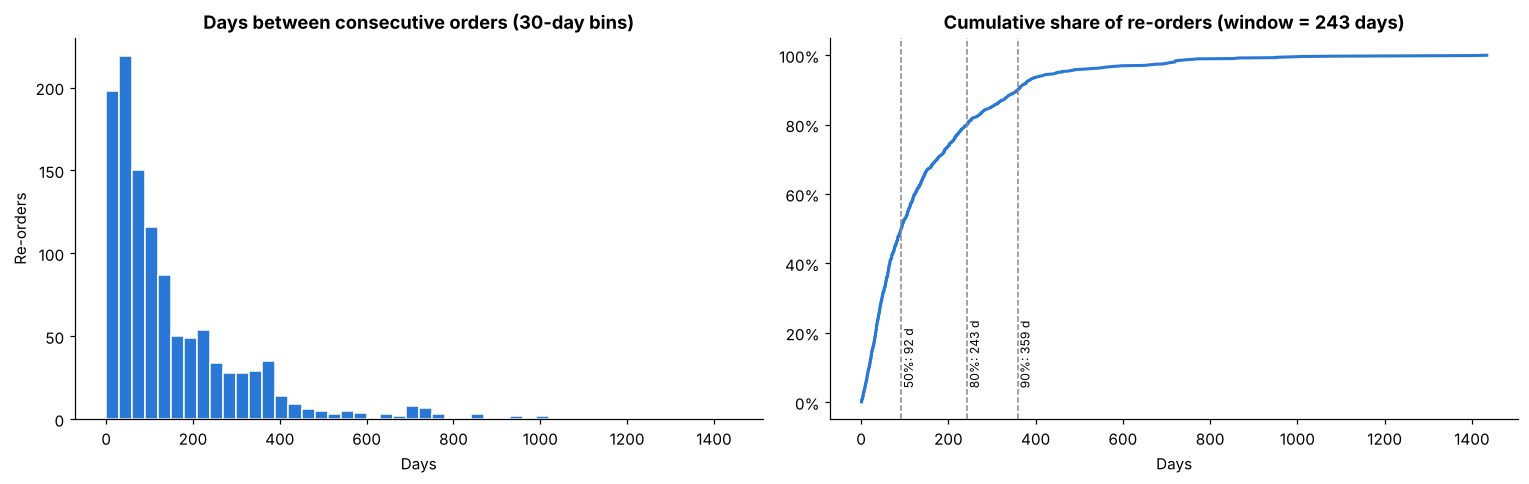

In [17]:
def plot_gaps(gaps: pd.Series, window: int) -> plt.Figure:
    """Histogram and cumulative curve of days between orders."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    ax1.hist(gaps, bins=range(0, int(gaps.max()) + 30, 30), color=MAIN_COLOUR, edgecolor="white")
    ax1.set(title="Days between consecutive orders (30-day bins)",
            xlabel="Days", ylabel="Re-orders")

    xs = np.sort(gaps.to_numpy())
    ax2.plot(xs, np.arange(1, len(xs) + 1) / len(xs), color=MAIN_COLOUR, linewidth=2)
    for q in [0.5, 0.8, 0.9]:
        v = gaps.quantile(q)
        ax2.axvline(v, color=REFERENCE_GREY, linestyle="--", linewidth=1)
        ax2.text(v, 0.03, f" {q:.0%}: {v:.0f} d", rotation=90, va="bottom", fontsize=8)
    ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax2.set(title=f"Cumulative share of re-orders (window = {window} days)", xlabel="Days")
    fig.tight_layout()
    return fig


fig = plot_gaps(gaps, REORDER_WINDOW)
save(fig, "01_reorder_gaps")
plt.show()

# Report

## R1. New and retained shops by year

Shops are grouped by the year of their **first order** (cohort). For each cohort: how many eligible new shops there were and what share placed a second order within the re-order window.

**About the first data year.** The data starts in the middle of the first year. A shop whose first order *in the data* falls in that year may have been a customer before, so the first cohort contains existing customers and its retention is overstated. It is shown, but marked.

In [18]:
def shop_table(orders: pd.DataFrame, window: int, cutoff: pd.Timestamp) -> pd.DataFrame:
    """One row per shop: first and second order, retention flag and first-order features.

    :param window: re-order window in days
    :param cutoff: last first-order date with a full window
    """
    first = orders[orders["order_no"] == 1].set_index("shop_id")
    second_date = orders[orders["order_no"] == 2].set_index("shop_id")["order_date"]
    n_orders = orders.groupby("shop_id")["order_id"].nunique()
    shops = pd.DataFrame({
        "first_date": first["order_date"],
        "cohort": first["order_date"].dt.year,
        "channel": first["channel"],
        "country": first["country"],
        "first_value": first["order_value"],
        "first_units": first["units"],
        "n_orders": n_orders,
    })
    shops["days_to_second"] = (second_date.reindex(shops.index) - shops["first_date"]).dt.days
    shops["eligible"] = shops["first_date"] <= cutoff
    shops["retained"] = (shops["days_to_second"] <= window).astype(int)
    shops["group_total"] = order_group(shops["n_orders"])
    return shops


def retention_by_cohort(shops: pd.DataFrame, by: list | None = None) -> pd.DataFrame:
    """Eligible new shops and retention rate per cohort (optionally split further)."""
    keys = ["cohort"] + (by or [])
    t = (shops[shops["eligible"]].groupby(keys)
             .agg(new_shops=("retained", "size"), retained=("retained", "sum")))
    t["retention_rate"] = t["retained"] / t["new_shops"]
    return t


shops = shop_table(orders, REORDER_WINDOW, ELIGIBILITY_CUTOFF)
cohorts = retention_by_cohort(shops)
overall_rate = shops.loc[shops["eligible"], "retained"].mean()
print(f"Eligible shops: {shops['eligible'].sum()} of {len(shops)}; "
      f"retained within {REORDER_WINDOW} days: {overall_rate:.1%}")
cohorts.style.format({"retention_rate": "{:.1%}"})

Eligible shops: 1005 of 1140; retained within 243 days: 30.4%


,new_shops,retained,retention_rate
cohort,,,
2021,267,122,45.7%
2022,295,78,26.4%
2023,107,37,34.6%
2024,131,24,18.3%
2025,153,34,22.2%
2026,52,11,21.2%


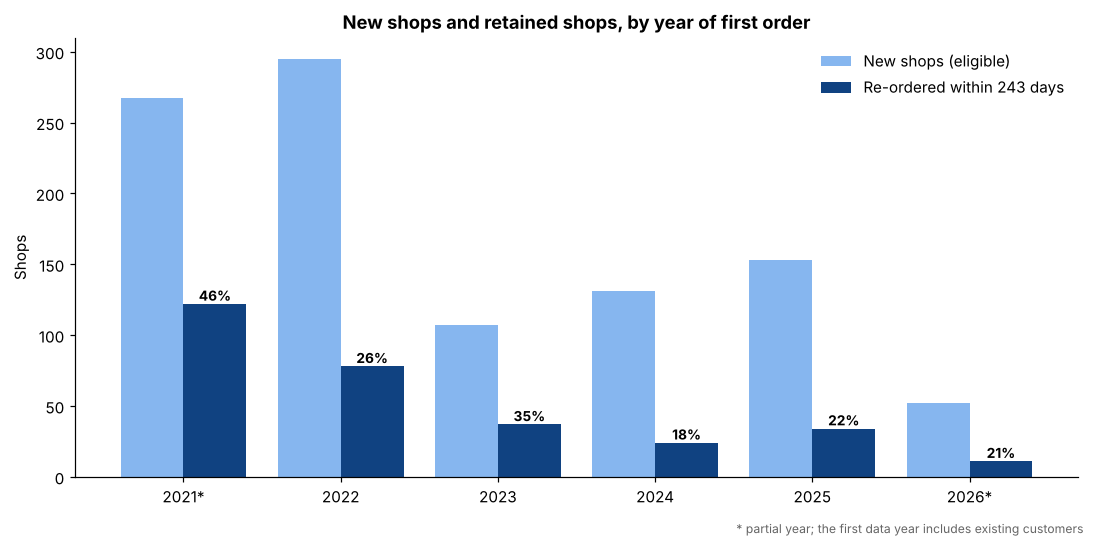

In [19]:
def plot_cohorts(cohorts: pd.DataFrame, window: int) -> plt.Figure:
    """New eligible shops vs shops retained, per cohort."""
    labels = [year_label(y, PARTIAL_YEARS) for y in cohorts.index]
    pos = np.arange(len(cohorts))
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.bar(pos - 0.2, cohorts["new_shops"], width=0.4, color=ORDINAL_3[0], label="New shops (eligible)")
    ax.bar(pos + 0.2, cohorts["retained"], width=0.4, color=ORDINAL_3[2],
           label=f"Re-ordered within {window} days")
    for p, n, r in zip(pos, cohorts["retained"], cohorts["retention_rate"]):
        ax.text(p + 0.2, n, f"{r:.0%}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(pos, labels)
    ax.set(ylabel="Shops", title="New shops and retained shops, by year of first order")
    ax.legend(frameon=False)
    fig.text(0.99, -0.02, "* partial year; the first data year includes existing customers",
             ha="right", fontsize=8, color="#666")
    fig.tight_layout()
    return fig


fig = plot_cohorts(cohorts, REORDER_WINDOW)
save(fig, "R1_new_vs_retained")
plt.show()

The same retention rates split by the channel of the first order, as a figure and as a table:

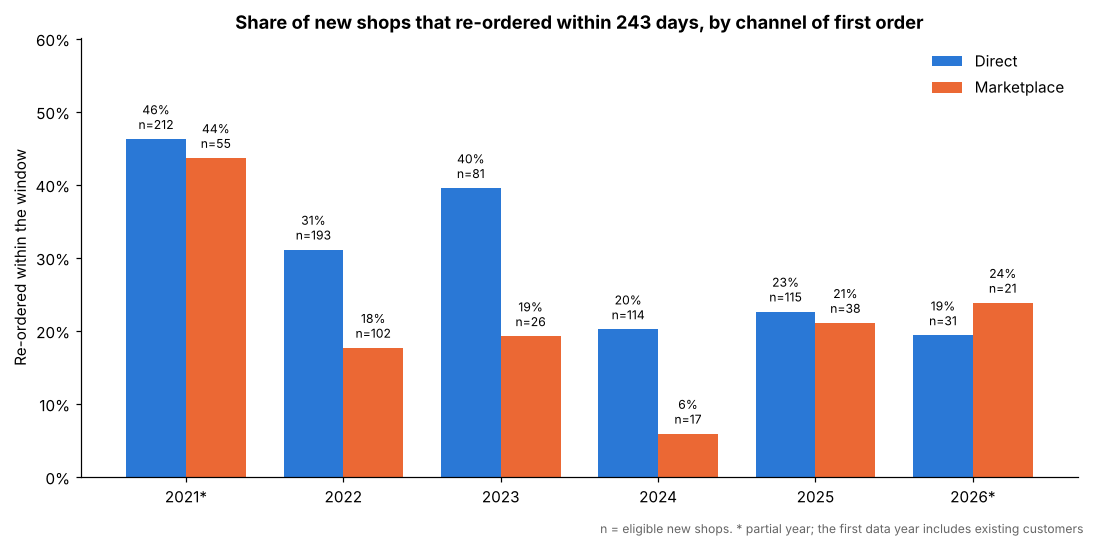

channel,direct,marketplace
cohort,,
2021,46%,44%
2022,31%,18%
2023,40%,19%
2024,20%,6%
2025,23%,21%
2026,19%,24%


In [20]:
def plot_retention_by_channel(by_channel: pd.DataFrame, window: int) -> plt.Figure:
    """Retention rate per cohort, direct vs marketplace, with the number of new shops."""
    rate = by_channel["retention_rate"].unstack("channel")
    n = by_channel["new_shops"].unstack("channel")
    channels = [c for c in ["direct", "marketplace"] if c in rate.columns]
    colours = {"direct": CATEGORICAL[0], "marketplace": CATEGORICAL[1]}
    pos = np.arange(len(rate))
    width = 0.38
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for k, ch in enumerate(channels):
        x = pos + (k - 0.5) * width
        ax.bar(x, rate[ch].fillna(0), width=width, color=colours[ch], label=ch.capitalize())
        for xi, r, cnt in zip(x, rate[ch], n[ch]):
            if pd.notna(r):
                ax.text(xi, r + 0.01, f"{r:.0%}\nn={int(cnt)}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(pos, [year_label(y, PARTIAL_YEARS) for y in rate.index])
    ax.set_ylim(0, max(0.6, rate.max().max() * 1.3))
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(ylabel="Re-ordered within the window",
           title=f"Share of new shops that re-ordered within {window} days, by channel of first order")
    ax.legend(frameon=False)
    fig.text(0.99, -0.02, "n = eligible new shops. * partial year; the first data year includes existing customers",
             ha="right", fontsize=8, color="#666")
    fig.tight_layout()
    return fig


by_channel = retention_by_cohort(shops, by=["channel"])
fig = plot_retention_by_channel(by_channel, REORDER_WINDOW)
save(fig, "R1_retention_by_channel")
plt.show()
(by_channel["retention_rate"].unstack()
    .style.format("{:.0%}", na_rep="–"))

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **About 3 in 10 new shops re-order within the window** (30.4% of 1,005 eligible shops). Half of all re-orders happen within about 3 months (median gap 92 days); 80% within 243 days.
- **Retention fell after 2023.** 26% (2022) and 35% (2023) against 18% (2024) and 22% (2025). The 2021 rate (46%) is overstated because many of its "new" shops were existing customers. The 2026 cohort is small (52 shops whose first order was before March).
- **The number of new shops also fell:** 295 eligible new shops in 2022, about 110–150 per year since.
- **Direct shops re-order more often than marketplace shops** in every full year up to 2024 (31% vs 18% in 2022, 40% vs 19% in 2023, 20% vs 6% in 2024). In 2025 the gap closed (23% vs 21%). The marketplace rates rest on few shops in 2023–2024 (26 and 17), so their exact level is uncertain.

## R2. Order groups: 1 order, 2–3 orders, 4+ orders

For each year, shops are grouped by how many orders they placed **in that year**. The three panels show what share of the year's **shops**, **orders** and **invoice value** each group accounts for. Small groups of loyal shops can carry a large share of orders and value, which the shop share alone hides.

In [21]:
def group_composition(orders: pd.DataFrame, group_col: str, by: str | None = "year") -> pd.DataFrame:
    """Shops, orders and invoice value per order group (optionally per year)."""
    keys = ([by] if by else []) + [group_col]
    return (orders.groupby(keys, observed=False)
                  .agg(shops=("shop_id", "nunique"),
                       orders=("order_id", "nunique"),
                       value=("order_value", "sum")))


comp_year = group_composition(orders, "group_year")
comp_total = group_composition(orders, "group_total", by=None)

print("All years (group = total orders over the whole period):")
display(comp_total.assign(**{f"% {c}": comp_total[c] / comp_total[c].sum()
                             for c in ["shops", "orders", "value"]})
        .style.format({"value": "{:,.0f}", "% shops": "{:.1%}", "% orders": "{:.1%}",
                       "% value": "{:.1%}"}))

All years (group = total orders over the whole period):


,shops,orders,value,% shops,% orders,% value
group_total,,,,,,
1 order,736,736,"510,124",64.6%,32.0%,27.2%
2–3 orders,272,634,"438,790",23.9%,27.6%,23.4%
4+ orders,132,928,"924,800",11.6%,40.4%,49.4%


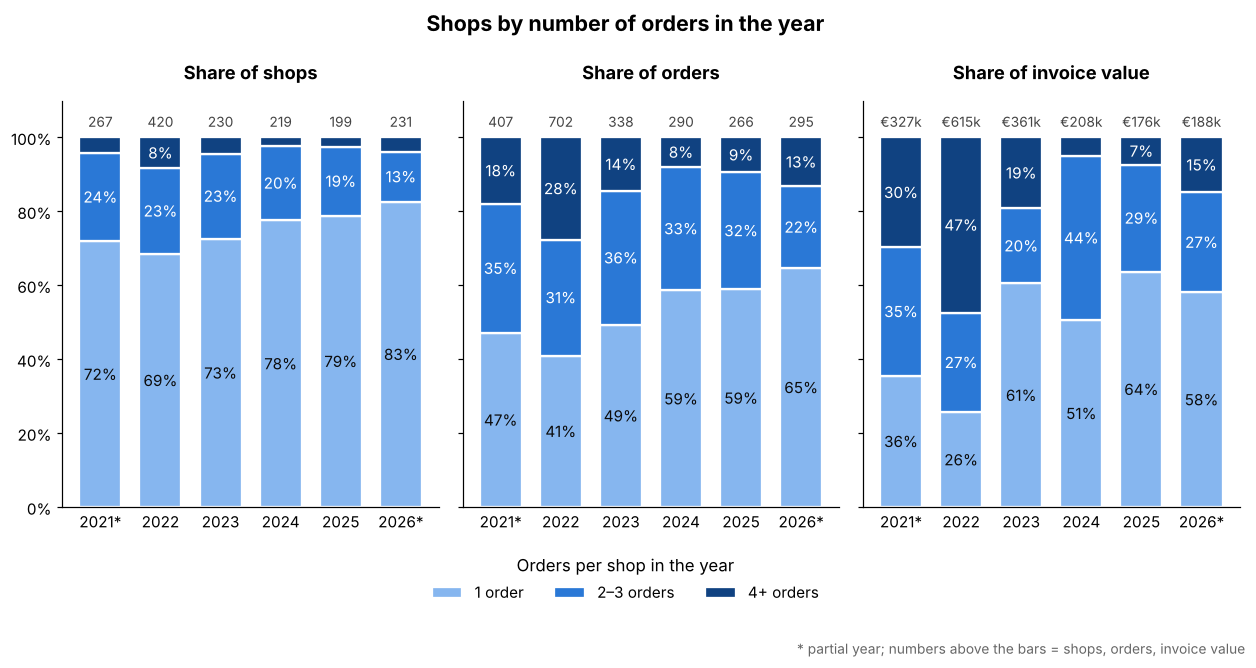

In [22]:
def plot_group_composition(comp: pd.DataFrame, group_col: str) -> plt.Figure:
    """Three 100% stacked panels: shares of shops, orders and value per year."""
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 5.0), sharey=True)
    panels = [("shops", "Share of shops", lambda v: f"{v:,.0f}"),
              ("orders", "Share of orders", lambda v: f"{v:,.0f}"),
              ("value", "Share of invoice value", lambda v: f"€{v / 1000:,.0f}k")]
    for ax, (metric, title, fmt) in zip(axes, panels):
        table = comp[metric].unstack(group_col)[ORDER_GROUP_LABELS]
        totals = table.sum(axis=1)
        table.index = [year_label(y, PARTIAL_YEARS) for y in table.index]
        stacked_bars(ax, shares(table), ORDINAL_3, title, [fmt(v) for v in totals], label_size=10)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Orders per shop in the year", loc="lower center",
               ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("Shops by number of orders in the year", fontsize=14, fontweight="bold")
    fig.text(0.99, -0.19, "* partial year; numbers above the bars = shops, orders, invoice value",
             ha="right", fontsize=9, color="#666")
    fig.tight_layout()
    return fig


with plt.rc_context(REPORT_RC):
    fig = plot_group_composition(comp_year, "group_year")
save(fig, "R2_order_groups_by_year")
plt.show()

The same split by channel (share of shops only). If marketplace shops re-order less within a year, a growing share of marketplace shops would push the overall "1 order" share up even if no shop changed its behaviour.

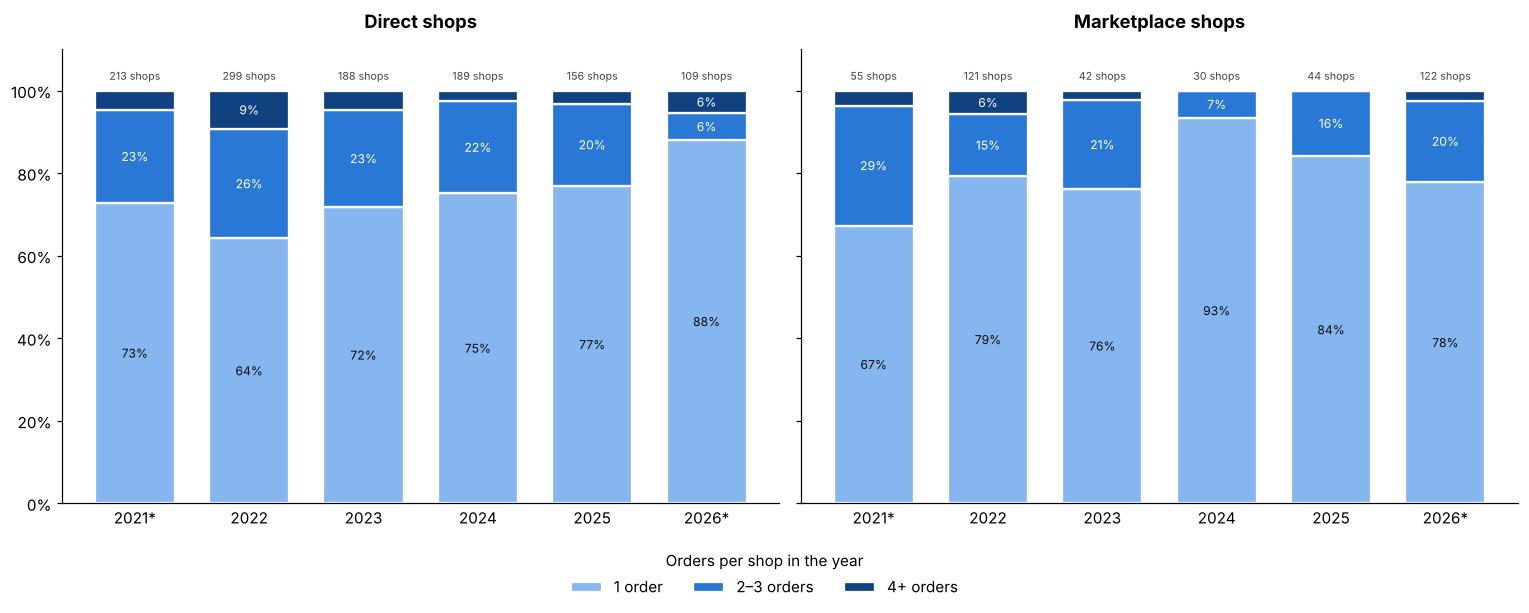

In [23]:
def plot_group_by_channel(orders: pd.DataFrame) -> plt.Figure:
    """Share of shops per order group per year, one panel per channel."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    for ax, ch in zip(axes, ["direct", "marketplace"]):
        sub = orders[orders["channel"] == ch]
        table = (sub.groupby(["year", "group_year"], observed=False)["shop_id"].nunique()
                    .unstack("group_year").reindex(YEARS)[ORDER_GROUP_LABELS].fillna(0))
        n = table.sum(axis=1)
        table.index = YEAR_LABELS
        stacked_bars(ax, shares(table), ORDINAL_3, f"{ch.capitalize()} shops",
                     [f"{v:,.0f} shops" for v in n])
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Orders per shop in the year", loc="lower center",
               ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    return fig


fig = plot_group_by_channel(orders)
save(fig, "R2_order_groups_by_channel")
plt.show()

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **A small group of loyal shops carries half the business.** Over all years, 12% of shops (4+ orders) placed 40% of all orders and brought 49% of invoice value. 65% of shops ordered only once and brought 27% of value.
- **Regular customers (4+ orders in a year) are few, and fewer than in 2022:** 8.3% of the year's active shops in 2022 (35 shops), 4.3% in 2023 (10), 2.3–2.5% in 2024 and 2025 (5 shops each) and 3.9% in the partial 2026 (9 shops).
- **The share of shops ordering only once a year has been rising:** 69% (2022) → 73% (2023) → 78% (2024) → 79% (2025), and 83% in the partial 2026.
- **The value from frequent buyers collapsed after 2022.** Shops with 4+ orders in the year brought 47% of the year's value in 2022, but only 5–7% in 2024–2025. About two-thirds of the fall in yearly value (615k € in 2022 → 176k € in 2025, a drop of 439k €) is value that frequent shops brought in 2022 and no longer bring (≈ 278k €).
- **Both channels show the trend**, so it is not just a shift towards marketplaces: the direct one-order share went from 64% (2022) to 77% (2025). Marketplace shops are more often one-order shops in most years. The jump in active shops in 2026 comes from Platform B (122 marketplace shops vs 44 in 2025).

## R3. Order sizes: 100–400 €, 400–1000 €, 1000+ €

Orders are grouped by their invoice value. The size groups are business categories (small, medium, large), not equal-width bins, so their heights should not be read as a histogram.

In [24]:
size_counts_year = pd.crosstab(orders["year"], orders["size_group"]).reindex(columns=SIZE_LABELS)
size_value_year = orders.pivot_table(index="year", columns="size_group", values="order_value",
                                     aggfunc="sum", observed=False).reindex(columns=SIZE_LABELS)

size_all = pd.DataFrame({
    "orders": orders["size_group"].value_counts().reindex(SIZE_LABELS),
    "value": orders.groupby("size_group", observed=False)["order_value"].sum().reindex(SIZE_LABELS),
})
size_all["% orders"] = size_all["orders"] / size_all["orders"].sum()
size_all["% value"] = size_all["value"] / size_all["value"].sum()
size_all.style.format({"value": "{:,.0f}", "% orders": "{:.1%}", "% value": "{:.1%}"})

,orders,value,% orders,% value
size_group,,,,
100–400,1035,"287,373",45.0%,15.3%
400–1000,968,"598,208",42.1%,31.9%
1000+,295,"988,134",12.8%,52.7%


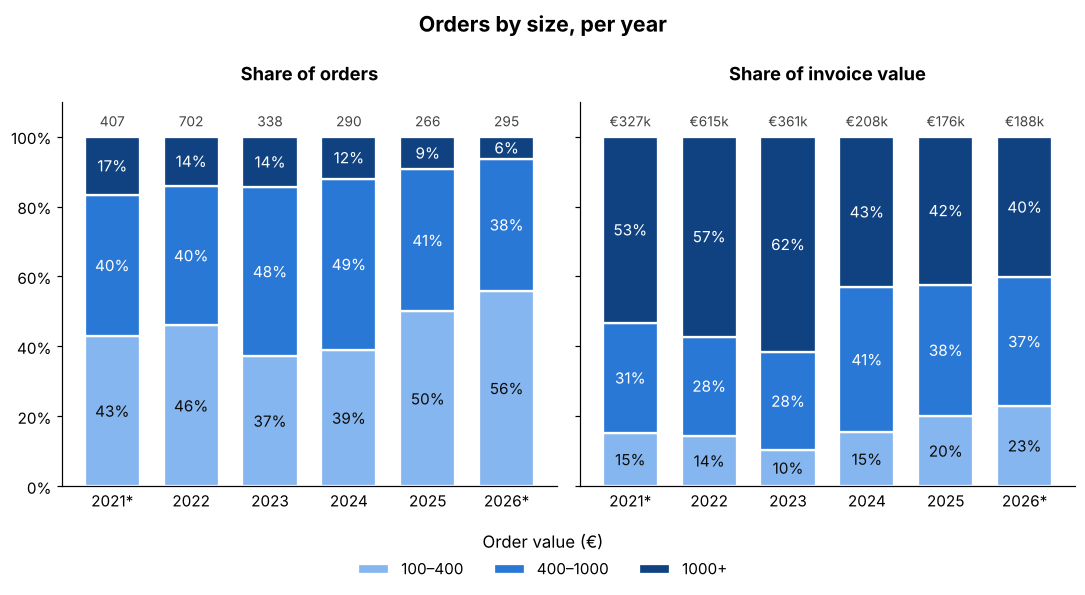

In [25]:
def plot_sizes_by_year(counts: pd.DataFrame, values: pd.DataFrame) -> plt.Figure:
    """Share of orders and of invoice value per size group, per year."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharey=True)
    for ax, table, title, fmt in [
        (axes[0], counts, "Share of orders", lambda v: f"{v:,.0f}"),
        (axes[1], values, "Share of invoice value", lambda v: f"€{v / 1000:,.0f}k"),
    ]:
        t = table.copy()
        totals = t.sum(axis=1)
        t.index = [year_label(y, PARTIAL_YEARS) for y in t.index]
        stacked_bars(ax, shares(t), ORDINAL_3, title, [fmt(v) for v in totals], label_size=10)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Order value (€)", loc="lower center",
               ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle("Orders by size, per year", fontsize=14, fontweight="bold")
    fig.tight_layout()
    return fig


with plt.rc_context(REPORT_RC):
    fig = plot_sizes_by_year(size_counts_year, size_value_year)
save(fig, "R3_order_sizes_by_year")
plt.show()

**Order size by order group.** Left: all years, with groups based on the shop's total orders. Right: per year, with groups based on orders within the year. `n` is the number of orders behind each bar; bars based on few orders are noisy.

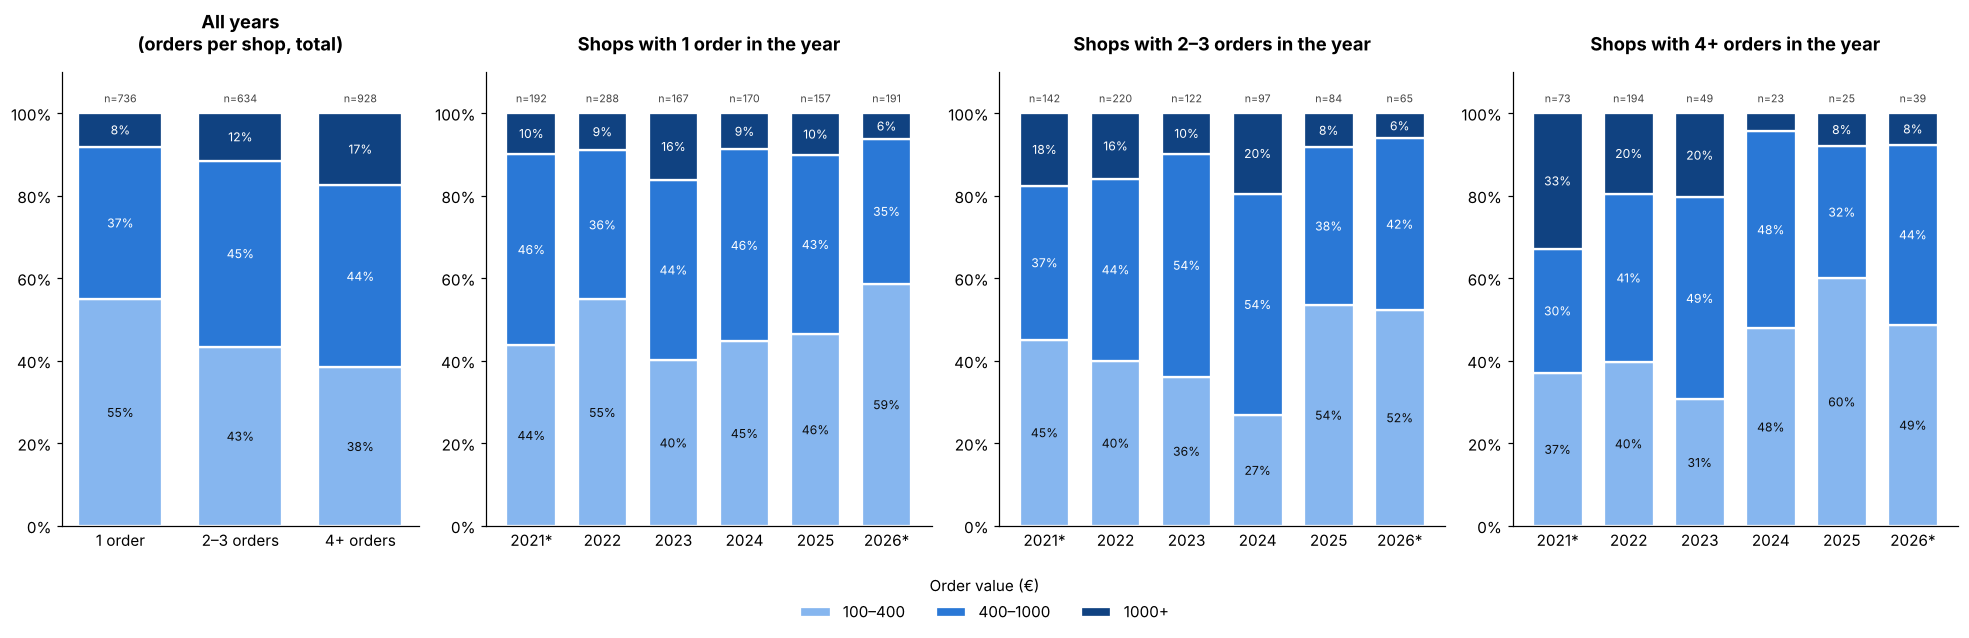

In [26]:
def plot_size_by_group(orders: pd.DataFrame) -> plt.Figure:
    """Size mix per order group: all years, and per year for each group."""
    fig = plt.figure(figsize=(18, 5.2))
    grid = fig.add_gridspec(1, 4, width_ratios=[0.8, 1, 1, 1])

    ax0 = fig.add_subplot(grid[0])
    t = pd.crosstab(orders["group_total"], orders["size_group"]).reindex(
        index=ORDER_GROUP_LABELS, columns=SIZE_LABELS)
    stacked_bars(ax0, shares(t), ORDINAL_3, "All years\n(orders per shop, total)",
                 [f"n={v:,}" for v in t.sum(axis=1)])

    for k, g in enumerate(ORDER_GROUP_LABELS):
        ax = fig.add_subplot(grid[k + 1], sharey=ax0)
        sub = orders[orders["group_year"] == g]
        t = pd.crosstab(sub["year"], sub["size_group"]).reindex(index=YEARS, columns=SIZE_LABELS)
        n = t.sum(axis=1)
        t.index = YEAR_LABELS
        stacked_bars(ax, shares(t), ORDINAL_3, f"Shops with {g} in the year",
                     [f"n={v:,.0f}" for v in n])

    handles, labels = ax0.get_legend_handles_labels()
    fig.legend(handles, labels, title="Order value (€)", loc="lower center", ncol=3,
               frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.tight_layout()
    return fig


fig = plot_size_by_group(orders)
save(fig, "R3_order_size_by_group")
plt.show()

A typical order size per shop (each shop's **median** order value) compared across groups, so that a few very active shops do not dominate. Medians are used because order values are strongly skewed by a few very large orders.

In [27]:
shop_median = orders.groupby("shop_id").agg(median_order=("order_value", "median"),
                                           group=("group_total", "first"))
(shop_median.groupby("group", observed=False)["median_order"]
    .describe(percentiles=[0.25, 0.5, 0.75]).round(0))

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
1 order,736.0,693.0,3480.0,101.0,260.0,370.0,618.0,91374.0
2–3 orders,272.0,693.0,1177.0,105.0,335.0,476.0,687.0,11953.0
4+ orders,132.0,719.0,1048.0,130.0,349.0,493.0,677.0,9699.0


*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **Large orders are few but bring most of the value:** orders of 1000+ € are 13% of orders but 53% of invoice value; orders of 100–400 € are 45% of orders but 15% of value.
- **Orders are getting smaller.** The share of 100–400 € orders rose from 37–46% (2022–2024) to 50% (2025) and 56% (2026, partial), and the 1000+ € share fell from 14% to 9% and 6%.
- **Shops that re-order place larger orders.** The typical (median) order of a shop is 370 € for one-order shops, 476 € for 2–3 orders and 493 € for 4+ orders. The difference is mainly between one-order shops and the rest.

## R4. What shops buy

### R4.1 Product categories
Units sold per category. The four main categories are shown separately; the smaller ones (Funny quote, OOGNIS, Scented jars, Candle Holders, CandleCycle, …) are combined as **Other**. Shares are of **units** (candles), not value: the lines do not carry a reliable value per product (see Appendix A).

In [28]:
CATEGORY_ORDER = MAIN_CATEGORIES + ["Other"]
CATEGORY_COLOURS = CATEGORICAL[:len(MAIN_CATEGORIES)] + [OTHER_GREY]

def unit_mix(lines: pd.DataFrame, rows: str, cols: str = "category",
             col_order: list = CATEGORY_ORDER) -> pd.DataFrame:
    """Units per (rows × cols), columns in a fixed order."""
    return (lines.pivot_table(index=rows, columns=cols, values="Quantity total",
                              aggfunc="sum", fill_value=0, observed=False)
                 .reindex(columns=col_order, fill_value=0))


cat_year = unit_mix(order_lines, "year")
print("Units per category and year:")
display(cat_year.assign(total=cat_year.sum(axis=1)))

Units per category and year:


category,Hand Gesture candles,Baby hand candle,CandleCan,3D Taper Candles,Other,total
year,,,,,,
2021,10362,6032,3150,0,0,19544
2022,20211,11790,4089,0,0,36090
2023,9732,3662,2789,0,313,16496
2024,5980,1387,4409,0,987,12763
2025,3261,1102,5009,4812,856,15040
2026,2205,555,5505,6797,637,15699


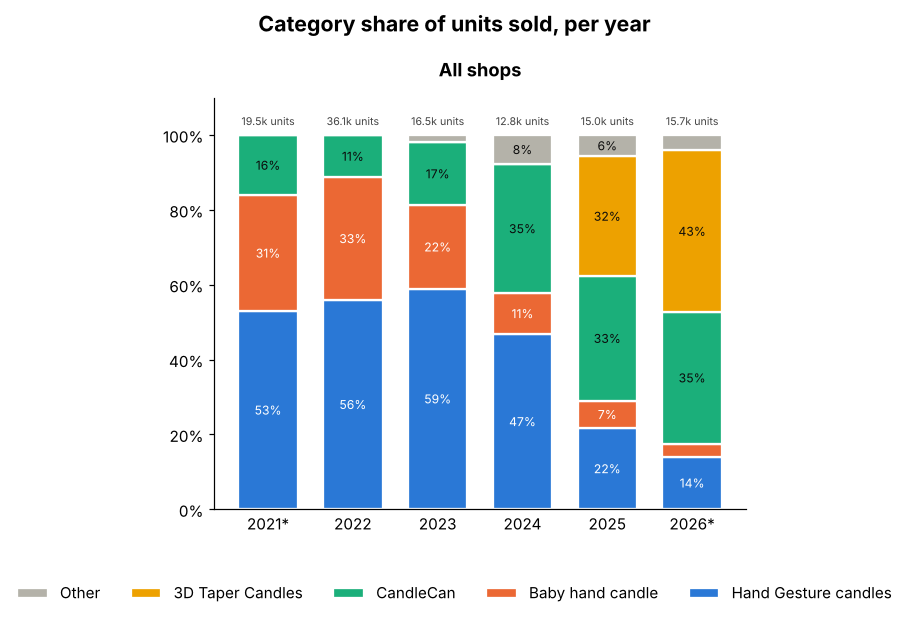

In [29]:
def plot_category_panels(lines: pd.DataFrame, split_col: str, split_values: list,
                         title: str, panel_title: str) -> plt.Figure:
    """One 100% stacked panel per split value: category share of units per year."""
    fig, axes = plt.subplots(1, len(split_values), figsize=(5.6 * len(split_values), 5),
                             sharey=True, squeeze=False)
    for ax, value in zip(axes[0], split_values):
        sub = lines if value is None else lines[lines[split_col] == value]
        t = unit_mix(sub, "year").reindex(YEARS, fill_value=0)
        n = t.sum(axis=1)
        t.index = YEAR_LABELS
        stacked_bars(ax, shares(t), CATEGORY_COLOURS,
                     panel_title.format(value) if value is not None else "All shops",
                     [f"{v / 1000:,.1f}k units" for v in n])
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles[::-1], labels[::-1], loc="lower center", ncol=len(CATEGORY_ORDER),
               frameon=False, bbox_to_anchor=(0.5, -0.12))
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    return fig


fig = plot_category_panels(order_lines, None, [None], "Category share of units sold, per year", "")
save(fig, "R4_categories_by_year")
plt.show()

**By order group** (orders within the year) and **by order size**:

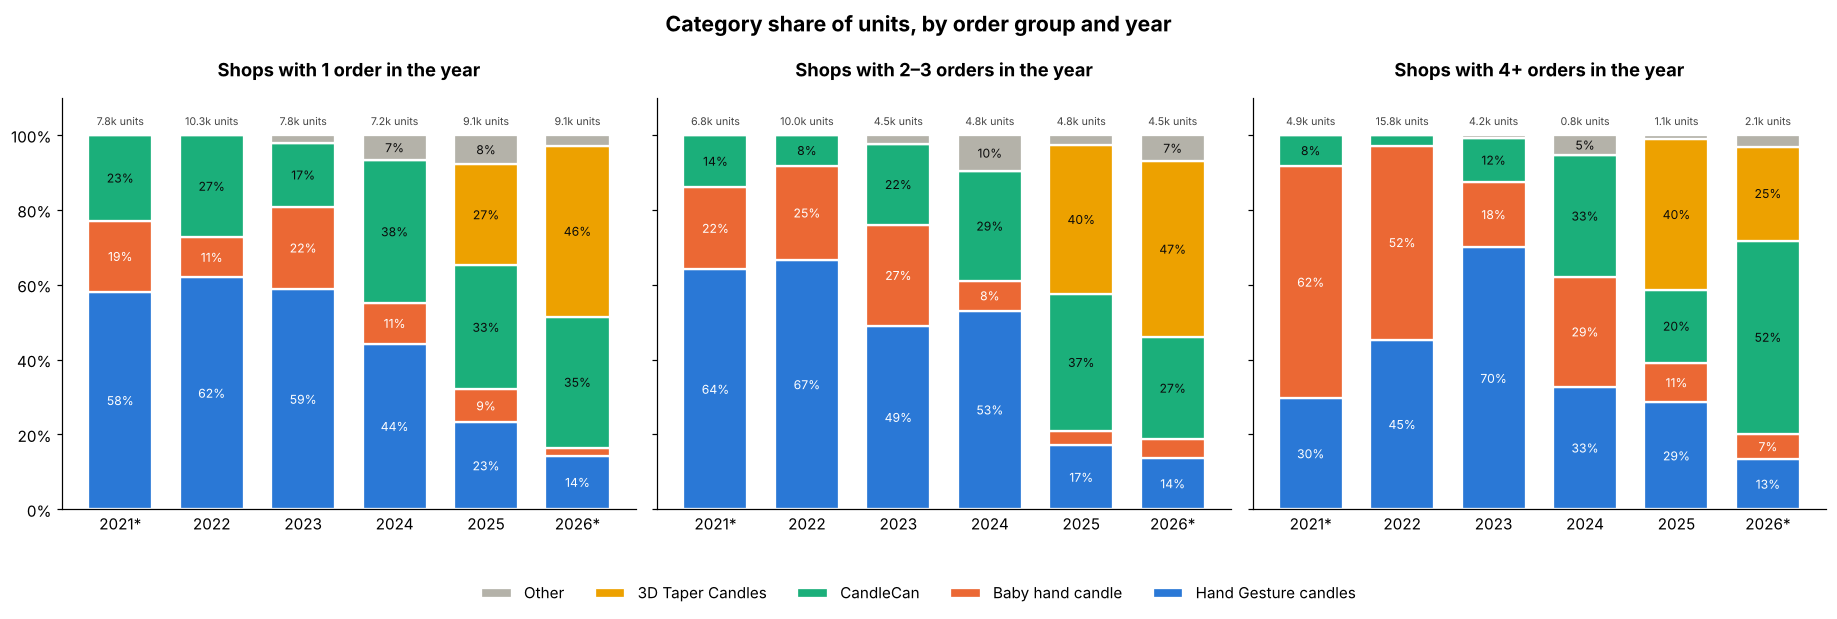

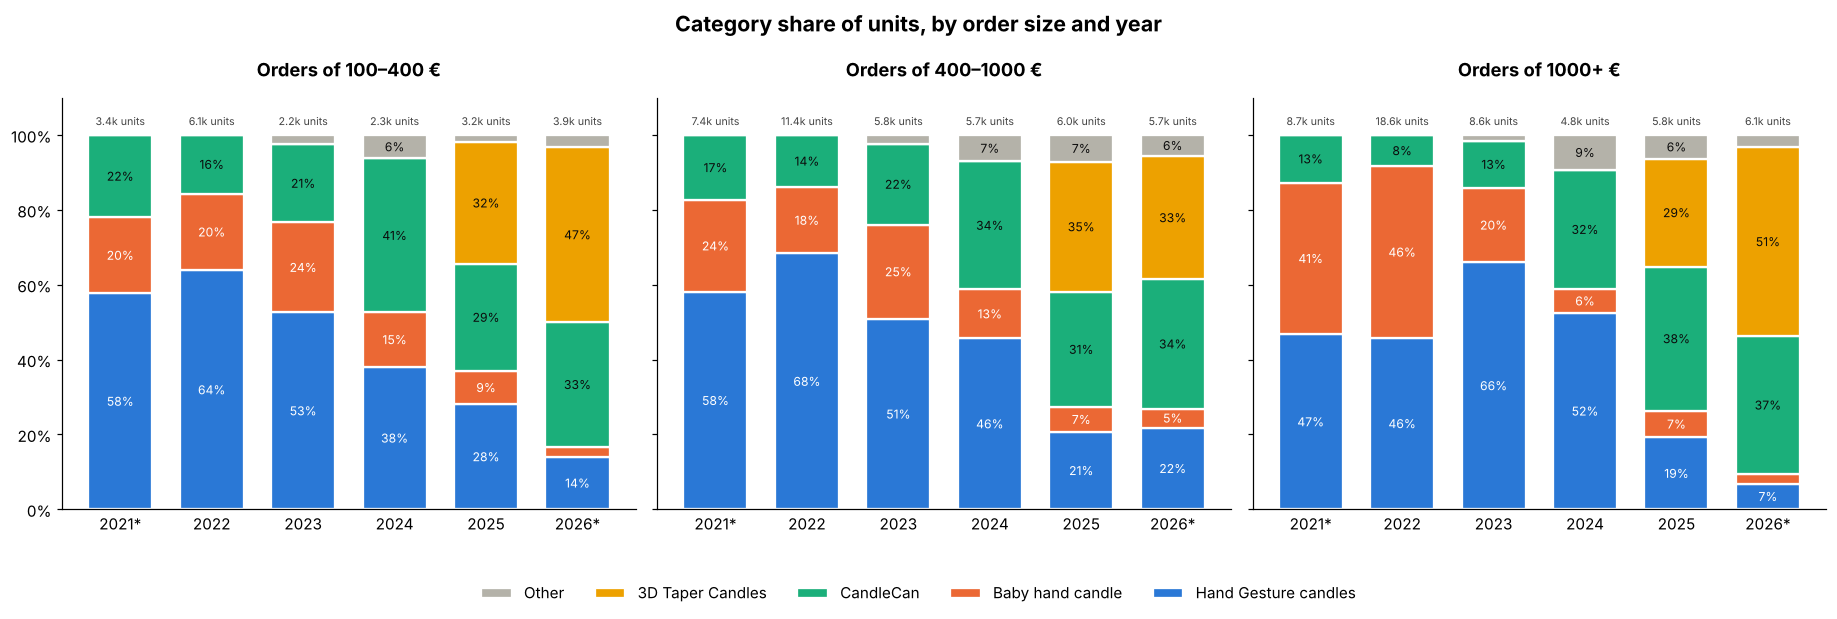

In [30]:
fig = plot_category_panels(order_lines, "group_year", ORDER_GROUP_LABELS,
                           "Category share of units, by order group and year", "Shops with {} in the year")
save(fig, "R4_categories_by_group")
plt.show()

fig = plot_category_panels(order_lines, "size_group", SIZE_LABELS,
                           "Category share of units, by order size and year", "Orders of {} €")
save(fig, "R4_categories_by_size")
plt.show()

**Range per order:** how many different categories an order contains, by order group and order size.

In [31]:
def range_per_order(lines: pd.DataFrame, item: str) -> pd.DataFrame:
    """Number of distinct `item` values per order, with the order's group and size."""
    return (lines.groupby("order_id")
                 .agg(n=(item, "nunique"), group=("group_total", "first"),
                      size=("size_group", "first"), year=("year", "first")))


cat_range = range_per_order(order_lines, "category")
pd.concat({
    "by order group (all years)": cat_range.groupby("group", observed=False)["n"].agg(["mean", "median", "count"]),
    "by order size": cat_range.groupby("size", observed=False)["n"].agg(["mean", "median", "count"]),
}).round(2)

mean  median  count
by order group (all years) 1 order     1.46     1.0    736
                           2–3 orders  1.53     1.0    634
                           4+ orders   1.52     1.0    928
by order size              100–400     1.33     1.0   1035
                           400–1000    1.63     2.0    968
                           1000+       1.66     1.0    295

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **The product mix has changed completely.** Hand Gesture candles fell from 20,200 units (2022) to 3,300 (2025), and Baby hand candles from 11,800 to 1,100. CandleCan grew steadily (4,100 → 5,000, and 5,500 in the first ten months of 2026). 3D Taper candles were introduced in 2025 and are already the largest category in 2026 (6,800 units, 43%).
- **Total units recovered slightly** (12,800 in 2024, 15,000 in 2025, 15,700 in 2026 up to October), driven by the new categories.
- **In 2021–2022, frequent buyers bought mostly Baby and Hand Gesture candles** (Baby hand: 62% and 52% of the units of 4+ shops). In 2025–2026 the frequent buyers' mix follows the new products.
- **Orders usually contain one category** (mean 1.5); larger orders contain slightly more (1.3 for 100–400 € vs 1.6 for 400+ €). Frequent and one-time buyers do not differ in range.
- The "Other" category is empty in 2021–2022; the smaller categories appear from 2023.

### R4.2 Gestures
A *gesture* is the individual design (e.g. Candle "F*ck you", BABY Candle "Peace"). There are over 100, so only the top `TOP_GESTURES_N` are shown (set in the configuration). First, the top gestures of each year:

In [32]:
def top_items_by_year(lines: pd.DataFrame, item: str, n: int) -> pd.DataFrame:
    """Top n items per year by units, written as 'name (share of the year's units)'."""
    out = {}
    for year, sub in lines.groupby("year"):
        units = sub.groupby(item)["Quantity total"].sum().sort_values(ascending=False)
        share = units / units.sum()
        out[year_label(year, PARTIAL_YEARS)] = [f"{g} ({s:.0%})" for g, s in share.head(n).items()]
    return pd.DataFrame({k: pd.Series(v) for k, v in out.items()}).set_axis(range(1, n + 1))


top_items_by_year(order_lines, "Gesture", TOP_GESTURES_N)

,2021*,2022,2023,2024,2025,2026*
1,"Candle ""F*ck you"" (23%)","Candle ""F*ck you"" (26%)","Candle ""F*ck you"" (29%)","Candle ""F*ck you"" (23%)","Candle ""F*ck you"" (9%)",Taper candle LOVE YOU (8%)
2,"BABY Candle ""F*ck You"" (14%)","BABY Candle ""F*ck You"" (16%)","BABY Candle ""F*ck You"" (13%)","Candle ""You Rock"" (9%)","Candle ""You Rock"" (6%)","Candle ""F*ck you"" (6%)"
3,"Candle ""You Rock"" (9%)","Candle ""You Rock"" (9%)","Candle ""Peace"" (10%)","BABY Candle ""F*ck You"" (6%)",Taper candle LOVE YOU (6%),Taper candle MERRY XMAS (6%)
4,"BABY Candle ""Peace"" (9%)","BABY Candle ""You Rock"" (8%)","Candle ""You Rock"" (8%)","Candle ""Peace"" (5%)",Taper candle MERRY XMAS (6%),"Candle ""Cinnamon Blackberry"" (5%)"
5,"BABY Candle ""You Rock"" (8%)","Candle ""Peace"" (8%)","Candle ""Crossed Fingers"" (6%)","Candle ""Ripe Strawberries"" (4%)",Taper candle HAPPY BDAY (4%),Taper candle HAPPY BDAY (5%)


The heatmaps below use the **overall top** `TOP_GESTURES_N` gestures (all years) as rows, so that rows are comparable across columns. Each cell is the gesture's share of the column's units.

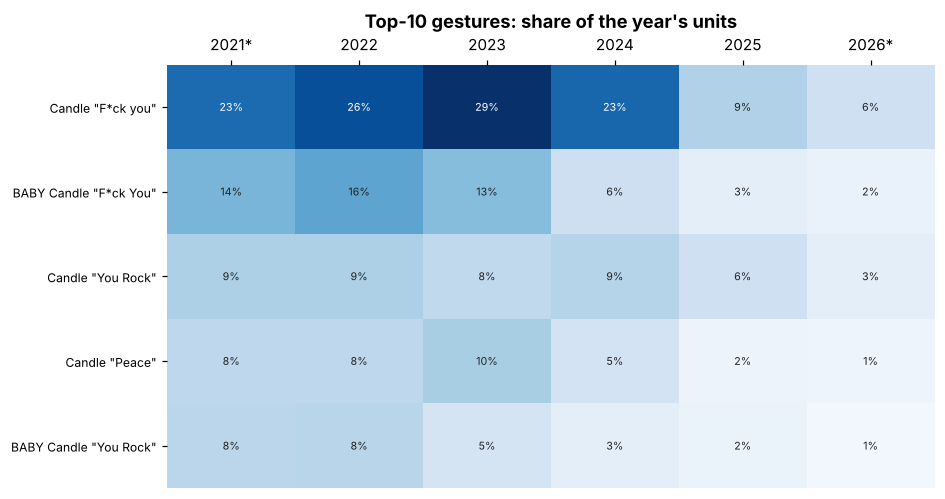

In [33]:
TOP_GESTURES = (order_lines.groupby("Gesture")["Quantity total"].sum()
                .nlargest(TOP_GESTURES_N).index.tolist())


def gesture_share(lines: pd.DataFrame, by: str, by_order: list) -> pd.DataFrame:
    """Share of units of each top gesture within each value of `by`."""
    total = lines.groupby(by, observed=False)["Quantity total"].sum().reindex(by_order)
    units = (lines[lines["Gesture"].isin(TOP_GESTURES)]
             .pivot_table(index="Gesture", columns=by, values="Quantity total",
                          aggfunc="sum", fill_value=0, observed=False)
             .reindex(index=TOP_GESTURES, columns=by_order, fill_value=0))
    return units.div(total, axis=1)


fig, ax = plt.subplots(figsize=(9, 5))
t = gesture_share(order_lines, "year", YEARS)
t.columns = YEAR_LABELS
heatmap(ax, t, title="Top-10 gestures: share of the year's units")
save(fig, "R4_gestures_by_year")
plt.show()

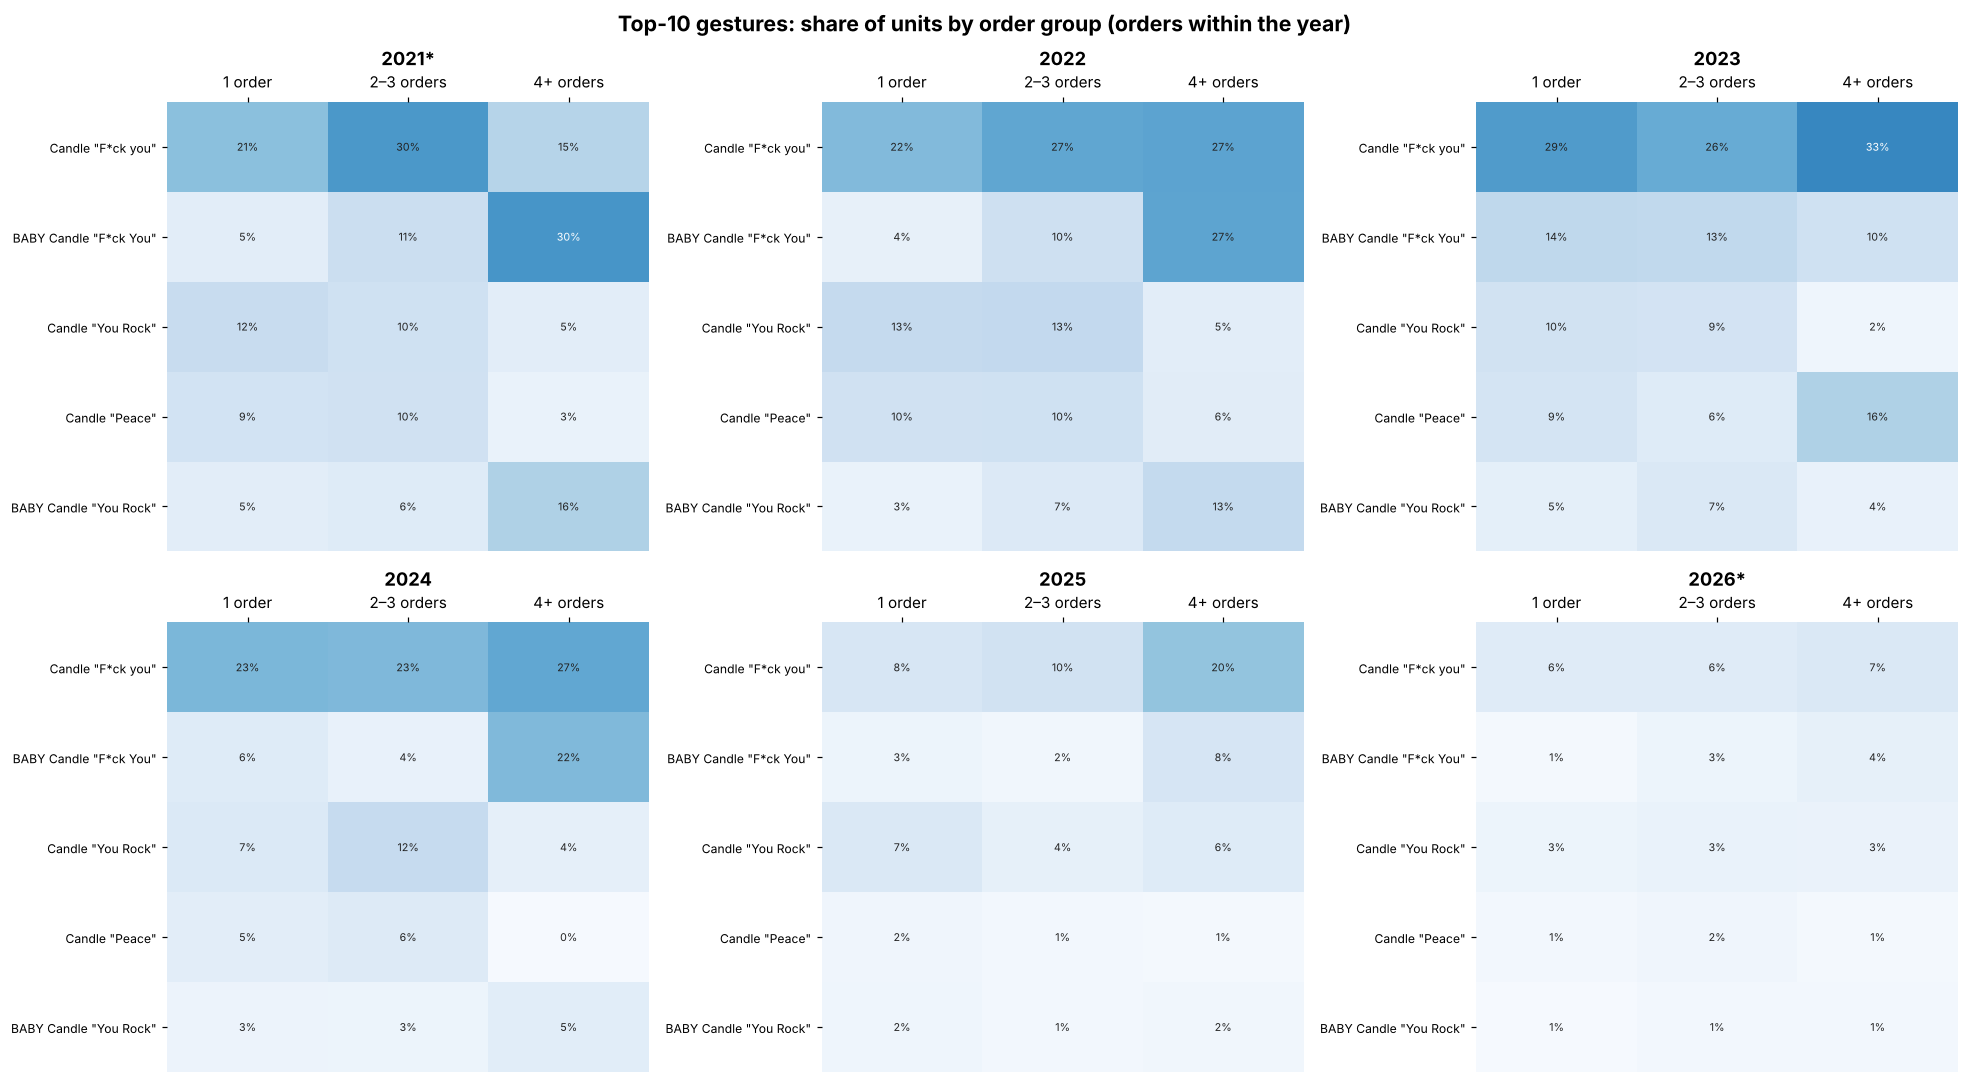

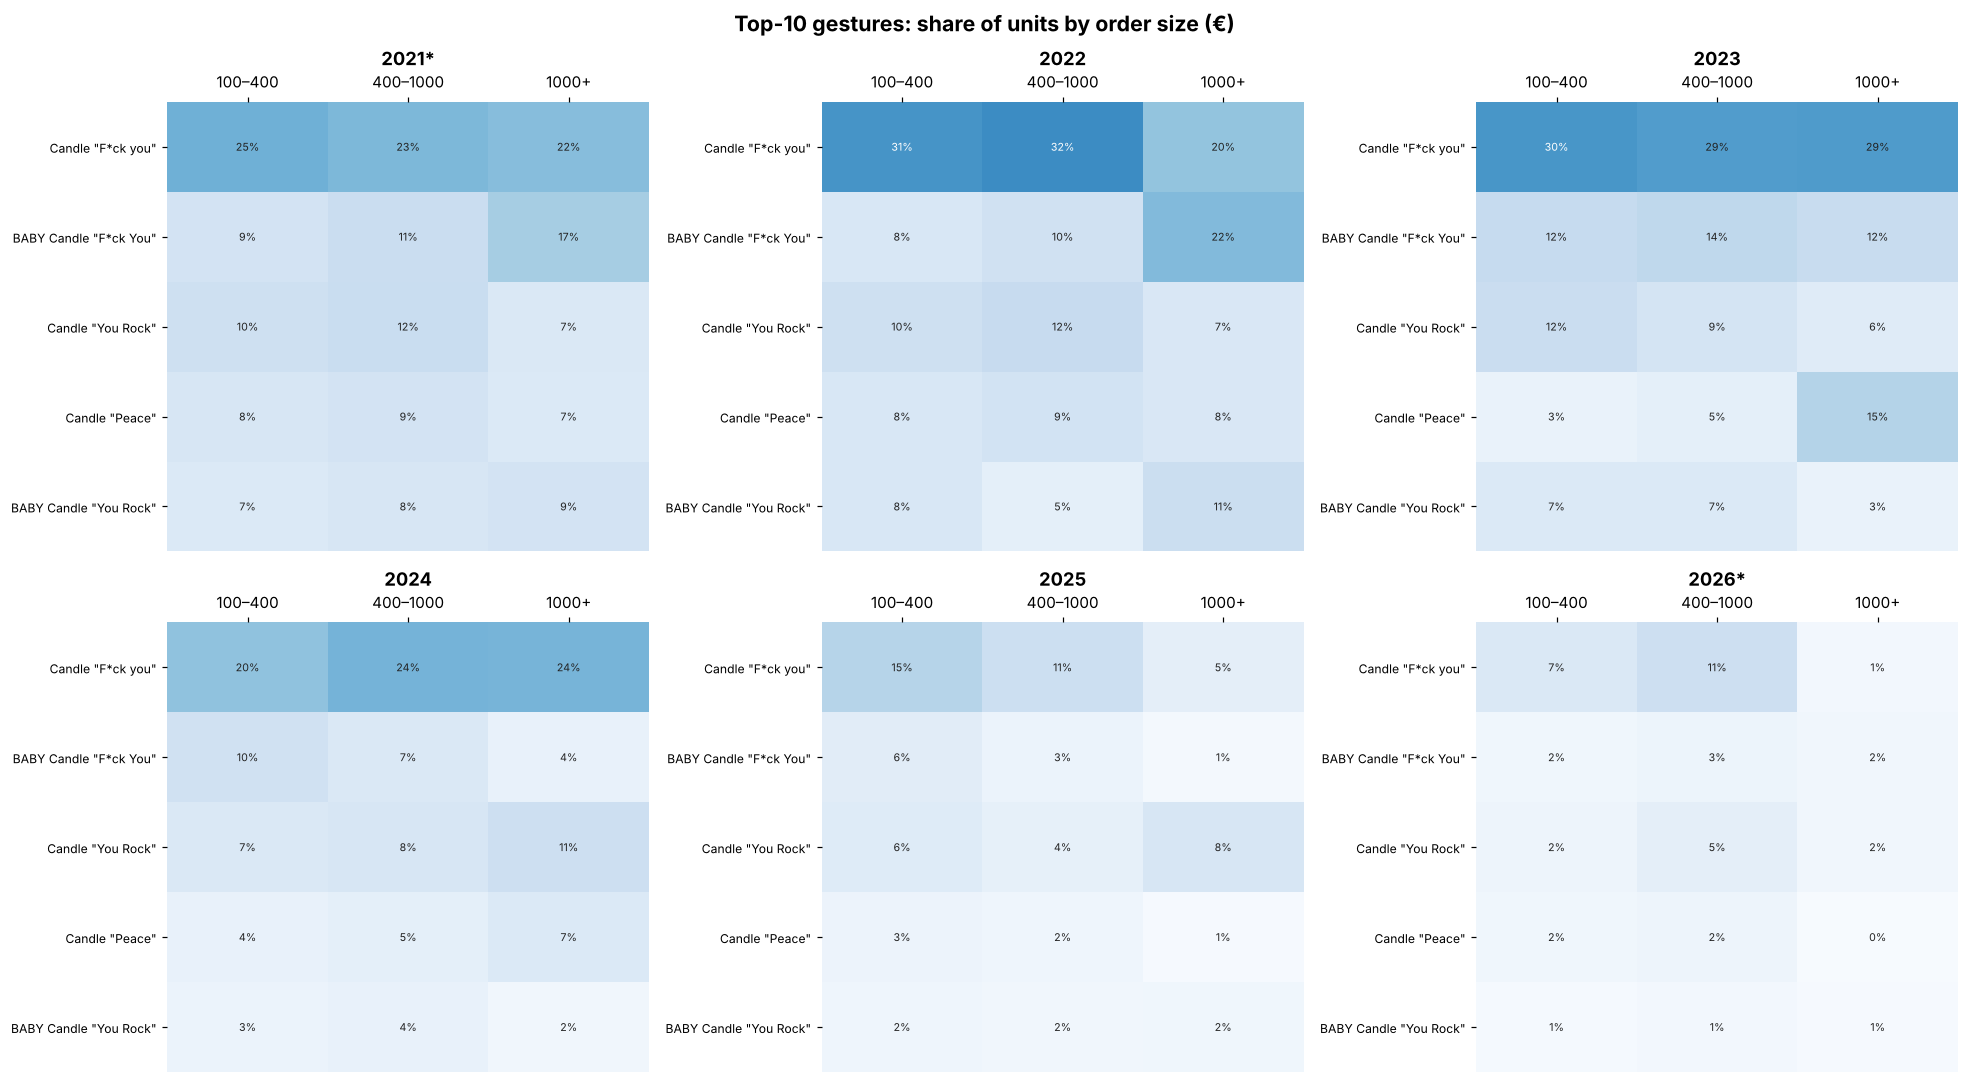

In [34]:
def gesture_panels(lines: pd.DataFrame, by: str, by_order: list, title: str) -> plt.Figure:
    """One heatmap per year: top gestures × groups."""
    fig, axes = plt.subplots(2, int(np.ceil(len(YEARS) / 2)), figsize=(18, 10), squeeze=False)
    for ax, (year, label) in zip(axes.flat, zip(YEARS, YEAR_LABELS)):
        heatmap(ax, gesture_share(lines[lines["year"] == year], by, by_order),
                title=label, vmax=0.5)
    for ax in list(axes.flat)[len(YEARS):]:
        ax.axis("off")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    return fig


fig = gesture_panels(order_lines, "group_year", ORDER_GROUP_LABELS,
                     "Top-10 gestures: share of units by order group (orders within the year)")
save(fig, "R4_gestures_by_group")
plt.show()

fig = gesture_panels(order_lines, "size_group", SIZE_LABELS,
                     "Top-10 gestures: share of units by order size (€)")
save(fig, "R4_gestures_by_size")
plt.show()

**Gesture range per category:** how many different gestures an order contains *within* each main category (only orders that contain the category).

In [35]:
def gestures_per_category(lines: pd.DataFrame, by: str, by_order: list) -> pd.DataFrame:
    """Mean number of distinct gestures per order, within each main category."""
    per = (lines[lines["category"] != "Other"]
           .groupby(["order_id", "category"])
           .agg(n=("Gesture", "nunique"), grp=(by, "first")))
    return (per.groupby(["category", "grp"], observed=False)["n"].mean()
               .unstack("grp").reindex(index=MAIN_CATEGORIES, columns=by_order))


pd.concat({
    "by order group (all years)": gestures_per_category(order_lines, "group_total", ORDER_GROUP_LABELS),
    "by order size": gestures_per_category(order_lines, "size_group", SIZE_LABELS),
}, axis=1).round(1)

by order group (all years)                       \
grp                                     1 order 2–3 orders 4+ orders   
category                                                               
Hand Gesture candles                        3.4        3.3       3.2   
Baby hand candle                            2.1        2.2       2.1   
CandleCan                                   6.5        5.7       5.3   
3D Taper Candles                            5.2        4.9       4.9   

                     by order size                 
grp                        100–400 400–1000 1000+  
category                                           
Hand Gesture candles           2.9      3.5   3.9  
Baby hand candle               2.0      2.1   2.5  
CandleCan                      5.4      6.3   6.2  
3D Taper Candles               4.4      5.6   6.2

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **Candle "F\*ck you" was the best-selling design every year up to 2025** (23–29% of units in 2021–2024), but its share dropped to 9% in 2025. In 2026 the taper candles lead (LOVE YOU, MERRY XMAS, HAPPY BDAY).
- **BABY Candle "F\*ck You" is strongly linked to the frequent buyers** in 2021, 2022 and 2024 (22–30% of their units vs 4–6% for one-order shops). Part of this comes from a few large accounts (see R5.4: it is the top design in North America, the Nordic countries and the UK & Ireland).
- **Larger orders contain more designs per category** (Hand Gesture: 2.9 different gestures in 100–400 € orders, 3.9 in 1000+ € orders). Frequent and one-time buyers do not differ.

## R5. Countries

### R5.1 Invoice value per shop per year
The measure is **invoice value per shop per active year**: a shop that ordered in 2023 and 2025 counts as two *shop-years*. This puts long-standing and new shops on the same footing.

To summarise many countries in one number per year there are three options, and they answer different questions:

- **mean of countries:** every country counts equally, so a country with one large shop moves it a lot;
- **median of countries:** the middle country; robust to such outliers;
- **pooled:** all value ÷ all shops; every *shop* counts equally, so it describes the average shop and follows the largest markets.

The pooled value is the best answer to "how much does an average shop spend per year". The median of countries is shown as the robust country-level view. The chart shows these two; the mean of countries is only in the table, because a single large shop can move it a lot. "Unknown" (mostly Platform B) is excluded, because it is not a location.

In [36]:
def country_year(orders: pd.DataFrame) -> pd.DataFrame:
    """Shops active, orders and invoice value per country and year."""
    t = (orders.groupby(["country", "year"])
               .agg(shops=("shop_id", "nunique"), orders=("order_id", "nunique"),
                    value=("order_value", "sum"))
               .reset_index())
    t["value_per_shop"] = t["value"] / t["shops"]
    return t


cy = country_year(orders)
known = cy[cy["country"] != "Unknown"]
trend = known.groupby("year").agg(countries=("country", "nunique"), shops=("shops", "sum"),
                                  value=("value", "sum"),
                                  mean_of_countries=("value_per_shop", "mean"),
                                  median_of_countries=("value_per_shop", "median"))
trend["pooled"] = trend["value"] / trend["shops"]
trend.round(0)

,countries,shops,value,mean_of_countries,median_of_countries,pooled
year,,,,,,
2021,24,267,327008.0,3879.0,920.0,1225.0
2022,26,418,611652.0,7601.0,1388.0,1463.0
2023,21,229,359620.0,6146.0,1321.0,1570.0
2024,22,218,207488.0,1940.0,1185.0,952.0
2025,29,190,172165.0,1767.0,971.0,906.0
2026,28,179,168918.0,1750.0,1085.0,944.0


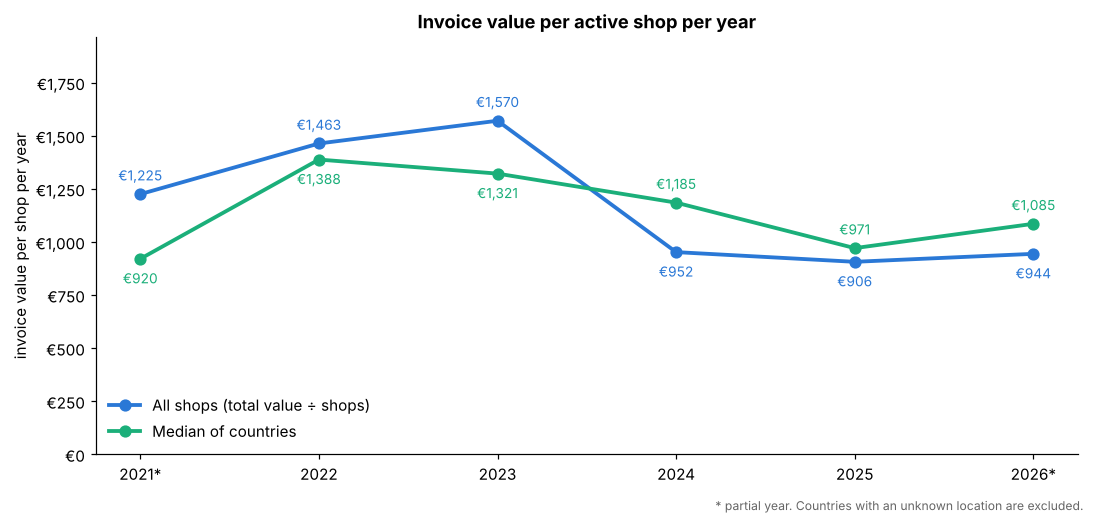

In [37]:
def plot_trend(trend: pd.DataFrame) -> plt.Figure:
    """Invoice value per active shop per year: all shops (pooled) and the median of countries."""
    x = np.arange(len(trend))
    fig, ax = plt.subplots(figsize=(10, 4.6))
    lines_spec = [("pooled", "All shops (total value ÷ shops)", CATEGORICAL[0], 2.5),
                  ("median_of_countries", "Median of countries", CATEGORICAL[2], 2.5)]
    for col, label, colour, lw in lines_spec:
        other = trend["median_of_countries"] if col == "pooled" else trend["pooled"]
        ax.plot(x, trend[col], marker="o", markersize=7, linewidth=lw, color=colour, label=label)
        for xi, v, w in zip(x, trend[col], other):
            ax.annotate(f"€{v:,.0f}", (xi, v), xytext=(0, 9 if v >= w else -16), textcoords="offset points",
                        ha="center", fontsize=9, color=colour)
    ax.set_xticks(x, [year_label(y, PARTIAL_YEARS) for y in trend.index])
    ax.set_ylim(0, trend[["pooled", "median_of_countries"]].max().max() * 1.25)
    ax.yaxis.set_major_formatter(lambda v, p: f"€{v:,.0f}")
    ax.set(ylabel="invoice value per shop per year", title="Invoice value per active shop per year")
    ax.legend(frameon=False, loc="lower left")
    fig.text(0.99, -0.02, "* partial year. Countries with an unknown location are excluded.",
             ha="right", fontsize=8, color="#666")
    fig.tight_layout()
    return fig


fig = plot_trend(trend)
save(fig, "R5_value_per_shop_trend")
plt.show()


### R5.2 Country ranking (all years)
Countries are ranked by **total invoice value** over all years, and the first `TOP_COUNTRIES_N` (20) form the **top countries** used in the rest of R5 and in the model (R6). "Unknown" (mostly Platform B shops whose country could not be identified, section 4.2) is not a location and is left out of the ranking.

The other columns put the total in context: `value_per_shop_year` (total value ÷ shop-years) and `median_shop_value_per_year` (the typical shop's yearly value, not influenced by one large account). A country with few `shops` can rank high because of a single large customer.


In [38]:
def country_summary(orders: pd.DataFrame, shops: pd.DataFrame) -> pd.DataFrame:
    """All-years summary per country, including retention of eligible new shops."""
    shop_years = orders.groupby(["country", "year"])["shop_id"].nunique().groupby("country").sum()
    t = orders.groupby("country").agg(shops=("shop_id", "nunique"),
                                      orders=("order_id", "nunique"),
                                      value=("order_value", "sum"))
    t["shop_years"] = shop_years
    t["value_per_shop_year"] = t["value"] / t["shop_years"]
    per_shop = orders.groupby(["country", "shop_id"]).agg(value=("order_value", "sum"),
                                                         years=("year", "nunique"))
    t["median_shop_value_per_year"] = (per_shop["value"] / per_shop["years"]).groupby("country").median()
    t["orders_per_shop"] = t["orders"] / t["shops"]
    el = shops[shops["eligible"]].groupby("country")["retained"].agg(["size", "mean"])
    t["eligible_new_shops"] = el["size"]
    t["retention_rate"] = el["mean"]
    return t.sort_values("value", ascending=False)


countries = country_summary(orders, shops)
ranked = countries.drop(index="Unknown", errors="ignore").head(TOP_COUNTRIES_N)
TOP_COUNTRIES = ranked.index.tolist()

known_value = countries.drop(index="Unknown", errors="ignore")["value"].sum()
print(f"{len(countries.drop(index='Unknown', errors='ignore'))} countries with a known location. "
      f"The top {TOP_COUNTRIES_N} bring {ranked['value'].sum() / known_value:.1%} of their invoice value.")
ranked.style.format({"value": "{:,.0f}", "value_per_shop_year": "{:,.0f}",
                     "median_shop_value_per_year": "{:,.0f}",
                     "orders_per_shop": "{:.2f}", "retention_rate": "{:.0%}",
                     "eligible_new_shops": "{:.0f}"})

53 countries with a known location. The top 20 bring 94.0% of their invoice value.


,shops,orders,value,shop_years,value_per_shop_year,median_shop_value_per_year,orders_per_shop,eligible_new_shops,retention_rate
country,,,,,,,,,
France,387,941,"602,006",582,"1,034",475,2.43,362,34%
Italy,264,517,"319,691",395,809,595,1.96,264,32%
Switzerland,7,18,"175,273",9,"19,475",704,2.57,5,20%
United States,51,68,"117,449",56,"2,097",370,1.33,20,25%
Lithuania,45,95,"99,800",68,"1,468",429,2.11,44,36%
Germany,69,100,"70,601",76,929,532,1.45,59,22%
Netherlands,80,126,"48,841",98,498,266,1.57,78,21%
United Kingdom,5,19,"34,666",6,"5,778","6,739",3.80,5,60%
Sweden,2,10,"34,591",4,"8,648","5,799",5.00,2,50%


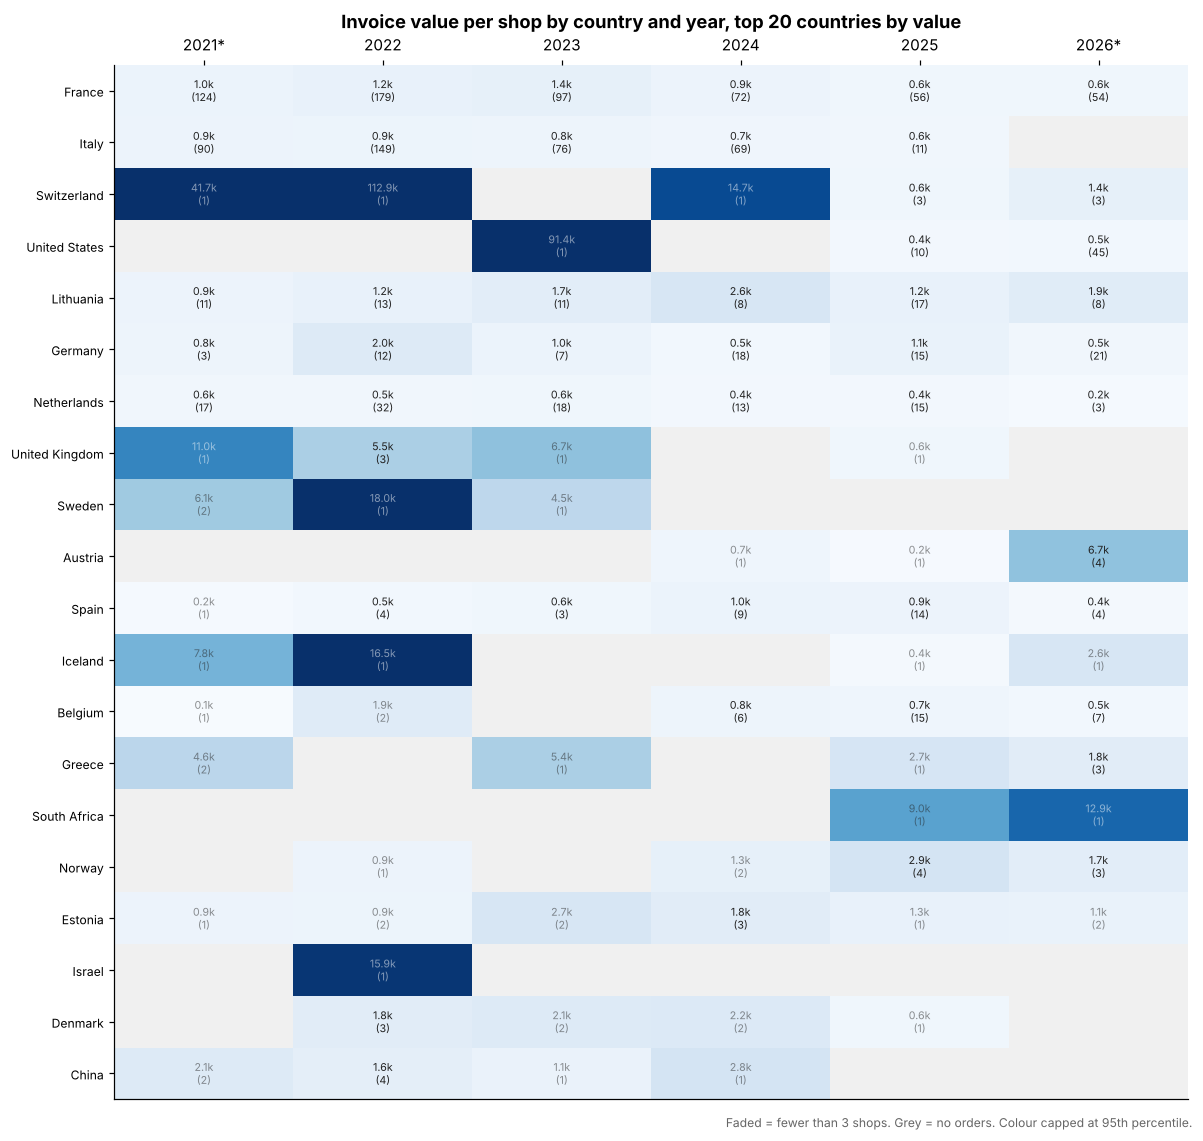

In [39]:
def plot_country_year_heatmap(cy: pd.DataFrame, countries: list) -> plt.Figure:
    """Invoice value per shop by country and year; colour capped at the 95th percentile."""
    val = (cy.pivot(index="country", columns="year", values="value_per_shop")
             .reindex(index=countries, columns=YEARS))
    n = cy.pivot(index="country", columns="year", values="shops").reindex(index=countries, columns=YEARS)
    vmax = np.nanpercentile(val.to_numpy(dtype=float), 95)
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(countries) + 1.8))
    cm = plt.get_cmap("Blues").copy()
    cm.set_bad("#f0f0f0")
    ax.imshow(np.ma.masked_invalid(val.to_numpy(dtype=float)), cmap=cm, aspect="auto", vmin=0, vmax=vmax)
    for i in range(val.shape[0]):
        for j in range(val.shape[1]):
            v, k = val.iat[i, j], n.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v / 1000:.1f}k\n({int(k)})", ha="center", va="center", fontsize=7,
                        color="white" if v > 0.6 * vmax else "#222", alpha=1 if k >= 3 else 0.5)
    ax.set_xticks(range(len(YEARS)), YEAR_LABELS)
    ax.set_yticks(range(len(countries)), countries, fontsize=8)
    ax.xaxis.tick_top()
    ax.set_title(f"Invoice value per shop by country and year, top {len(countries)} countries by value", pad=24)
    fig.text(0.99, -0.01, "Faded = fewer than 3 shops. Grey = no orders. Colour capped at 95th percentile.",
             ha="right", fontsize=8, color="#666")
    fig.tight_layout()
    return fig


fig = plot_country_year_heatmap(cy, TOP_COUNTRIES)
save(fig, "R5_country_year_heatmap")
plt.show()


### R5.3 Top countries: what their shops do and buy
For the top countries (by total value): how their shops split into order groups (all years), how their orders split by size, and what they buy (category share of units). The last bar is all countries together, as the reference.


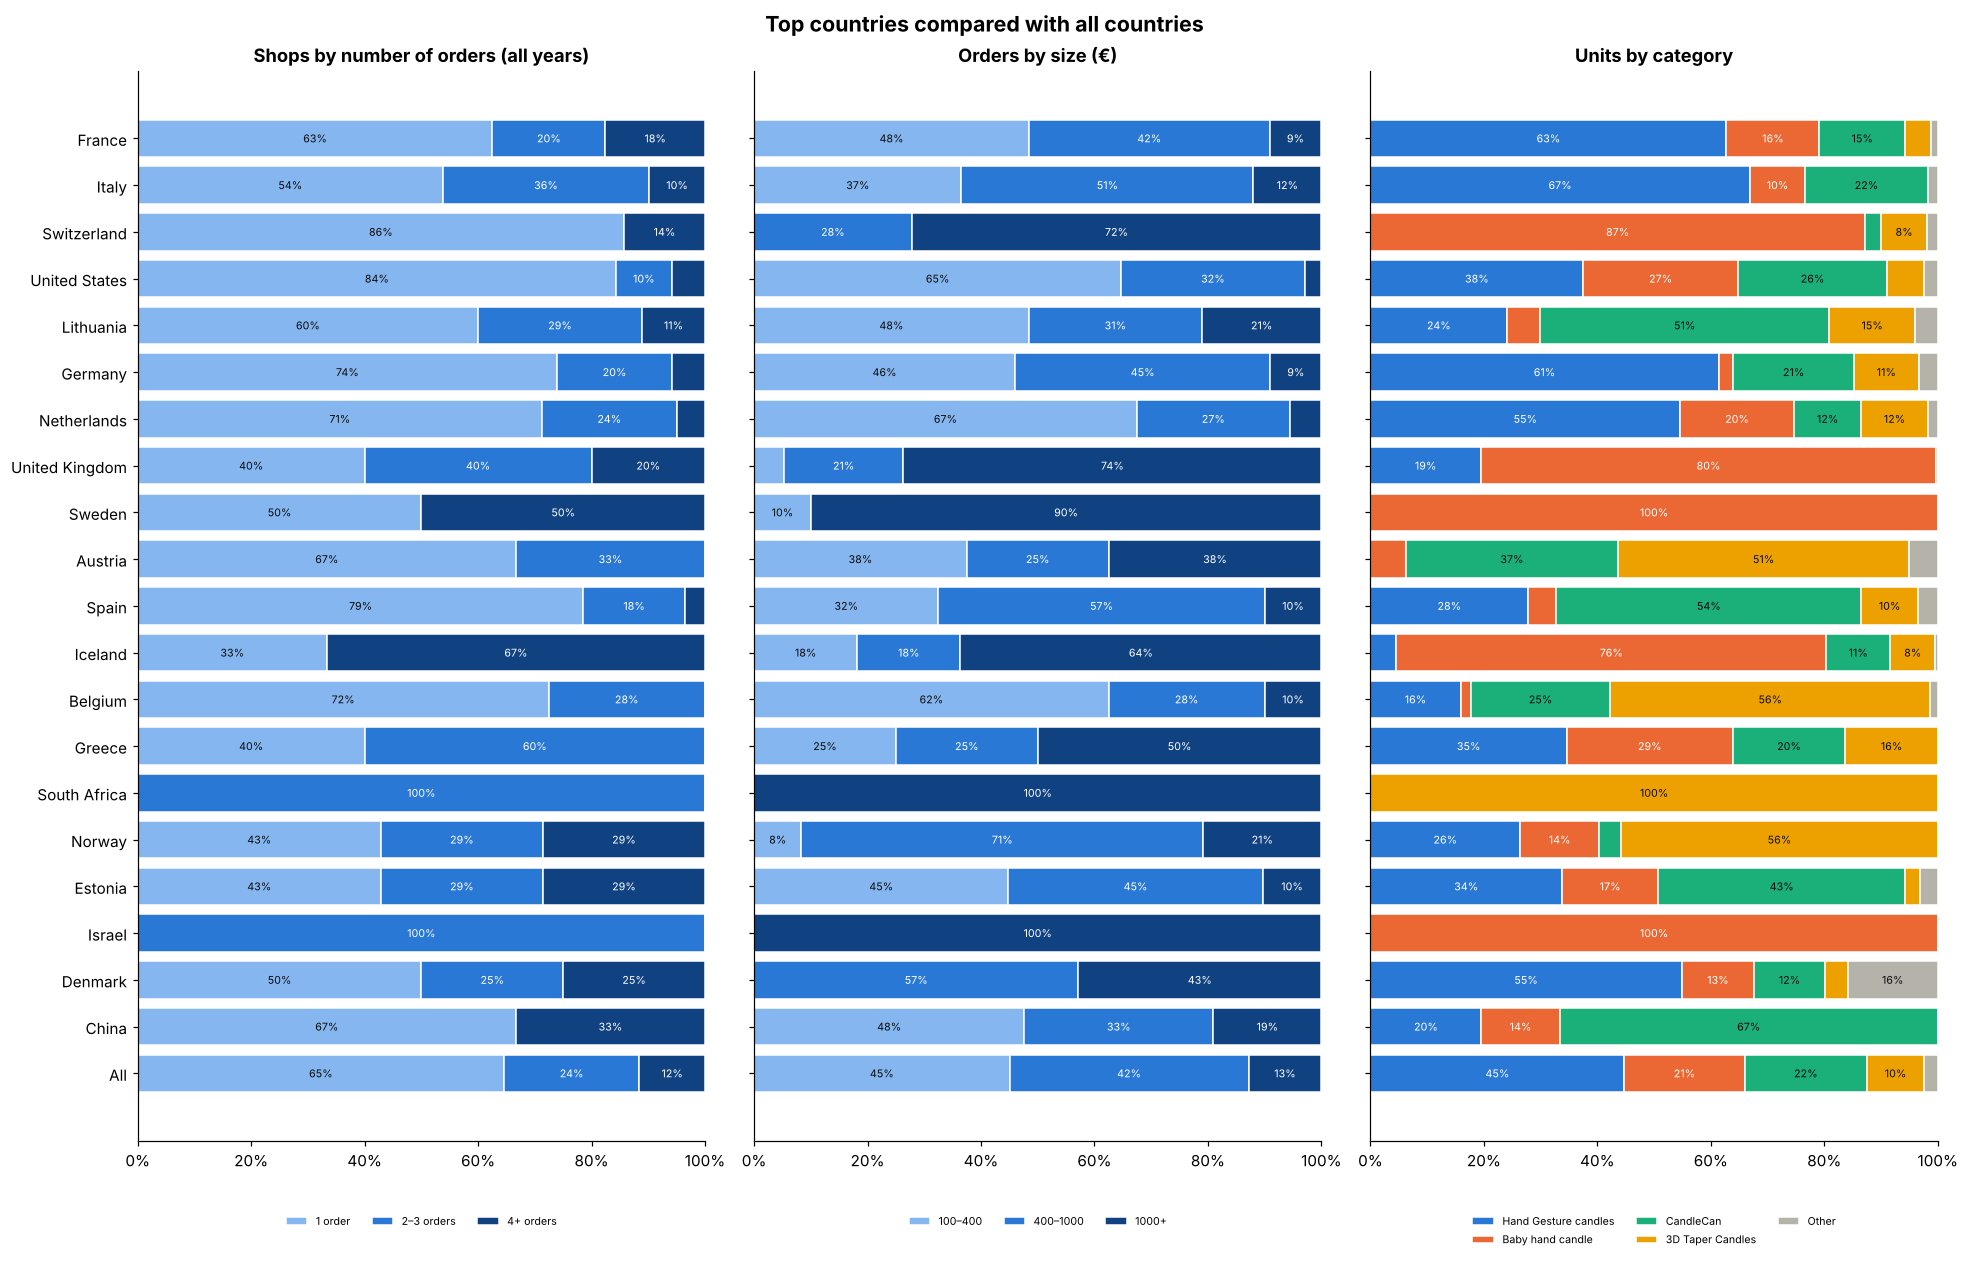

In [40]:
def country_profiles(orders: pd.DataFrame, lines: pd.DataFrame, shops: pd.DataFrame,
                     countries: list) -> dict:
    """Share tables for the top countries plus an 'All' reference row."""
    def with_all(t):
        return pd.concat([t.reindex(countries), t.sum().to_frame("All").T])

    groups = pd.crosstab(shops["country"], shops["group_total"]).reindex(columns=ORDER_GROUP_LABELS, fill_value=0)
    sizes = pd.crosstab(orders["country"], orders["size_group"]).reindex(columns=SIZE_LABELS, fill_value=0)
    cats = unit_mix(lines, "country")
    return {"groups": with_all(groups), "sizes": with_all(sizes), "cats": with_all(cats)}


profiles = country_profiles(orders, order_lines, shops, TOP_COUNTRIES)

fig, axes = plt.subplots(1, 3, figsize=(18, 0.45 * len(TOP_COUNTRIES) + 2.6), sharey=True)
for ax, (key, colours, title) in zip(axes, [
        ("groups", ORDINAL_3, "Shops by number of orders (all years)"),
        ("sizes", ORDINAL_3, "Orders by size (€)"),
        ("cats", CATEGORY_COLOURS, "Units by category")]):
    t = shares(profiles[key]).iloc[::-1]
    left = np.zeros(len(t))
    for col, colour in zip(t.columns, colours):
        ax.barh(t.index, t[col], left=left, color=colour, edgecolor="white", label=str(col))
        for yi, (v, l) in enumerate(zip(t[col], left)):
            if v >= 0.07:
                ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=7,
                        color=text_colour(colour))
        left += t[col].to_numpy()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False, fontsize=7)
fig.suptitle("Top countries compared with all countries", fontsize=14, fontweight="bold")
fig.tight_layout()
save(fig, "R5_top_country_profiles")
plt.show()

### R5.4 Top gestures by regional block
Countries are grouped into regional blocks (`REGIONS` in the configuration), because most single countries have too few shops for a reliable product profile. The table shows each block's three best-selling gestures over all years, with their share of the block's units.

In [41]:
def region_of(countries: pd.Series) -> pd.Series:
    """Map countries to the regional blocks in REGIONS; 'Unknown' stays, anything unmapped is 'Other'."""
    lookup = {c: region for region, members in REGIONS.items() for c in members}
    return countries.map(lookup).where(countries != "Unknown", "Unknown").fillna("Other")


def top_gestures_by_region(lines: pd.DataFrame, n: int = 3) -> pd.DataFrame:
    """Top n gestures (all years) per regional block, with their share of the block's units."""
    regions = region_of(lines["country"])
    rows = {}
    for region, sub in lines.assign(region=regions).groupby("region"):
        units = sub.groupby("Gesture")["Quantity total"].sum()
        share = (units / units.sum()).nlargest(n)
        rows[region] = {"countries": sub["country"].nunique(), "shops": sub["shop_id"].nunique(),
                        "units": int(units.sum()),
                        **{f"#{k}": f"{g} ({s:.0%})" for k, (g, s) in enumerate(share.items(), start=1)}}
    order = list(REGIONS) + ["Other", "Unknown"]
    return pd.DataFrame(rows).T.reindex([r for r in order if r in rows])


unmapped = sorted(set(order_lines["country"]) - {c for m in REGIONS.values() for c in m} - {"Unknown"})
print("Countries not in REGIONS (shown as 'Other'):", unmapped or "none")
top_gestures_by_region(order_lines)

Countries not in REGIONS (shown as 'Other'): none


,countries,shops,units,#1,#2,#3
Southern Europe,4,302,23082,"Candle ""F*ck you"" (27%)","Candle ""You Rock"" (14%)","Candle ""Crossed Fingers"" (7%)"
Central Europe,8,583,59474,"Candle ""F*ck you"" (25%)","BABY Candle ""F*ck You"" (11%)","Candle ""Peace"" (8%)"
UK & Ireland,2,11,3270,"BABY Candle ""F*ck You"" (32%)","BABY Candle ""Peace"" (19%)","BABY Candle ""You Rock"" (19%)"
Nordic countries,5,20,6021,"BABY Candle ""F*ck You"" (26%)","BABY Candle ""You Rock"" (13%)","BABY Candle ""Peace"" (10%)"
North-East Europe,6,61,10075,"Candle ""Peeled Tangerines"" (9%)","Candle ""You Rock"" (7%)","Candle ""Ripe Strawberries"" (7%)"
Balkans & Eastern Europe,4,9,1811,"Candle ""F*ck you"" (17%)","BABY Candle ""F*ck You"" (9%)","Candle ""You Rock"" (8%)"
Middle East,8,11,1242,"BABY Candle ""F*ck You"" (18%)","BABY Candle ""Peace"" (17%)","BABY Candle ""You Rock"" (11%)"
North America,4,55,2549,"BABY Candle ""F*ck You"" (24%)","Candle ""F*ck you"" (20%)","Candle ""You Rock"" (9%)"
Latin America,2,3,346,"Candle ""F*ck you"" (12%)",Taper candle MERRY XMAS (12%),Taper candle LOVE YOU (10%)
Asia & Oceania,6,17,4066,"BABY Candle ""Peace"" (21%)","BABY Candle ""F*ck You"" (16%)","BABY Candle ""You Rock"" (8%)"


*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **The average shop spends less per year than before:** pooled invoice value per shop was about 1,460–1,570 € in 2022–2023 and about 910–950 € in 2024–2025 (944 € in the partial 2026). The median of countries shows the same direction at a lower level (≈1,000–1,400 €). The mean of countries is dominated by single large accounts and is not a reliable summary.
- **Sales are concentrated in few countries:** the top 20 countries bring 94% of the invoice value of all 53 countries with a known location. France (602k €, 387 shops) and Italy (320k €, 264 shops) together bring about half, with average re-ordering (34% and 32%).
- **Several top-20 countries are there because of one customer.** Switzerland (3rd, 175k €) has 7 shops, but one of them placed orders of 42k € (2021), 113k € (2022) and 15k € (2024). The United States' largest year (2023) is a single 91k € order. South Africa and Israel are in the top 20 with one shop each, and Sweden with two shops, one of which brings almost all of its value. For these countries the total describes one account, not a market.
- **Markets with many shops:** the United States (51 shops, mostly Platform B shops identified in section 4.2) has a low typical spend (median ≈370 € per shop per year). Lithuania (45 shops) has strong repeat buying (36%); its value includes 21% VAT where charged, so compared with other countries it is up to about 17% lower than shown (÷ 1.21). Germany (69 shops), the Netherlands (80) and Belgium (29) have lower value per shop and lower re-ordering (21–28%); Spain's 12% is based on 26 eligible shops.
- **Italy has no orders in 2026** (up to the end of October), after 69 shops in 2024 and 11 in 2025. This is worth checking with the business: it may be a real loss of the market, or a change in how Italian orders are invoiced.
- **Product preferences differ by region (R5.4):** in Southern Europe and Central Europe (which includes France) the top design is the Hand Gesture Candle "F\*ck you" (27% and 25% of units). In the Nordic countries, UK & Ireland, North America and the Middle East, BABY Candle "F\*ck You" is the top design (18–32% of units). North-East Europe has no dominant design (the top one, Candle "Peeled Tangerines", is 9%). Africa and the "Unknown" shops (mostly recent Platform B shops) buy mainly taper candles, which reflects *when* they ordered (R4).


## R6. Early signals: does the first order predict re-ordering?

**Question.** Using only what is known on the day of a shop's **first order**, which features are associated with the shop placing a second order within the re-order window? The reverse reading identifies **red flags** for shops likely to stay at one order. Candlehand asked specifically whether **country** is related to re-ordering, so country is part of the model.

**Set-up**
- One row per **eligible** shop (first order at least one window before the data end).
- Shops whose first order is in the **first data year (2021) are left out** (`INCLUDE_FIRST_YEAR_IN_MODEL = False`): the data starts in June 2021, so many of these "first" orders were placed by existing customers.
- **Outcome:** `retained` = 1 if the second order came within the window.
- **Predictors** (all known at the first order):
  - **channel** (direct or marketplace);
  - **order value** group (100–400 €, 400–1000 €, 1000+ €);
  - **units**, as log₂(units), so the odds ratio means "units doubled";
  - **number of product categories** (1, 2, 3+);
  - **country:** each of the **top 20 countries by invoice value** (R5.2) gets its own term if it has at least `MIN_MODEL_COUNTRY_SHOPS` (10) shops in the model. All other shops (smaller countries, top-20 countries with fewer shops, and "Unknown") are grouped as **"Other"**. No shop is dropped: grouping only decides which countries get a separate estimate, because a country with a handful of shops cannot be estimated. Countries are compared with **France** (`MODEL_REFERENCE_COUNTRY`), the largest market, so each odds ratio reads "compared with a French shop".
- **Year of first order** is included as a **control**, not as a predictor (`YEAR_CONTROL = True`): retention changed a lot between years (R1), and without this control those changes would be attributed to the other features.
- Nothing calculated over the shop's later life is used (total orders, total value, payment status), because that information is not available at the moment of prediction.

**With and without Italy.** Italy is the second-largest market but behaves differently from the others: all 174 Italian shops in the model are direct, more than half of them started in 2022 (96 shops), and Italy has no orders at all in 2026 (R5). A single large, unusual country can shift the other estimates, so every model is fitted twice: **with all shops** and **without Italian shops** (`SENSITIVITY_COUNTRY`). Results that hold in both versions are more trustworthy.

In [42]:
VALUE_LEVELS = ["100-400", "400-1000", "1000+"]


def first_order_features(shops: pd.DataFrame, orders: pd.DataFrame, lines: pd.DataFrame,
                         include_first_year: bool, top_countries: list, min_country_shops: int) -> pd.DataFrame:
    """Eligible shops with features of their first order.

    :param include_first_year: keep shops whose first order is in the first (partial) data year
    :param top_countries: countries that may get their own term
    :param min_country_shops: top countries with fewer shops in the model are grouped as "Other"
    :return: one row per shop with the outcomes (retained, one_order) and the predictors
    """
    first_ids = orders.loc[orders["order_no"] == 1, ["shop_id", "order_id"]]
    fl = lines[lines["order_id"].isin(first_ids["order_id"])]
    per_order = fl.groupby("shop_id").agg(n_categories=("Product category", "nunique"))

    m = shops[shops["eligible"]].join(per_order)
    if not include_first_year:
        m = m[m["cohort"] > shops["cohort"].min()]
    m = m.copy()
    m["one_order"] = (m["n_orders"] == 1).astype(int)
    m["value_group"] = pd.Categorical(
        size_group(m["first_value"]).astype(str).str.replace("–", "-"), categories=VALUE_LEVELS)
    m["units_quartile"] = pd.qcut(m["first_units"], 4, duplicates="drop")
    m["log2_units"] = np.log2(m["first_units"])
    m["n_categories_group"] = pd.cut(m["n_categories"], [0, 1, 2, np.inf], labels=["1", "2", "3+"])
    m["year"] = m["cohort"].astype(str)
    counts = m["country"].value_counts()
    own_term = m["country"].isin(top_countries) & (m["country"].map(counts) >= min_country_shops)
    m["country_group"] = m["country"].where(own_term, "Other")
    return m


model_df = first_order_features(shops, orders, order_lines, INCLUDE_FIRST_YEAR_IN_MODEL,
                                TOP_COUNTRIES, MIN_MODEL_COUNTRY_SHOPS)
assert MODEL_REFERENCE_COUNTRY in set(model_df["country_group"]), "reference country has no own term"
MODEL_DATA = {"with Italy": model_df,
              "without Italy": model_df[model_df["country"] != SENSITIVITY_COUNTRY]}
for name, df in MODEL_DATA.items():
    print(f"{name}: {len(df)} shops, re-ordered within the window: {df['retained'].sum()} "
          f"({df['retained'].mean():.1%}); first orders {df['cohort'].min()}–{df['cohort'].max()}")
model_df["country_group"].value_counts().to_frame("shops in the model")

with Italy: 738 shops, re-ordered within the window: 184 (24.9%); first orders 2022–2026
without Italy: 564 shops, re-ordered within the window: 143 (25.4%); first orders 2022–2026


,shops in the model
country_group,
France,238
Italy,174
Other,107
Netherlands,61
Germany,56
Lithuania,33
Spain,25
Belgium,24
United States,20


### R6.1 Re-order rate by each feature
Each panel shows the re-order rate for one feature, with a 95% confidence interval (Wilson), for all shops (with Italy). A group only differs reliably from the overall rate (dashed line) if its interval stays clear of that line.

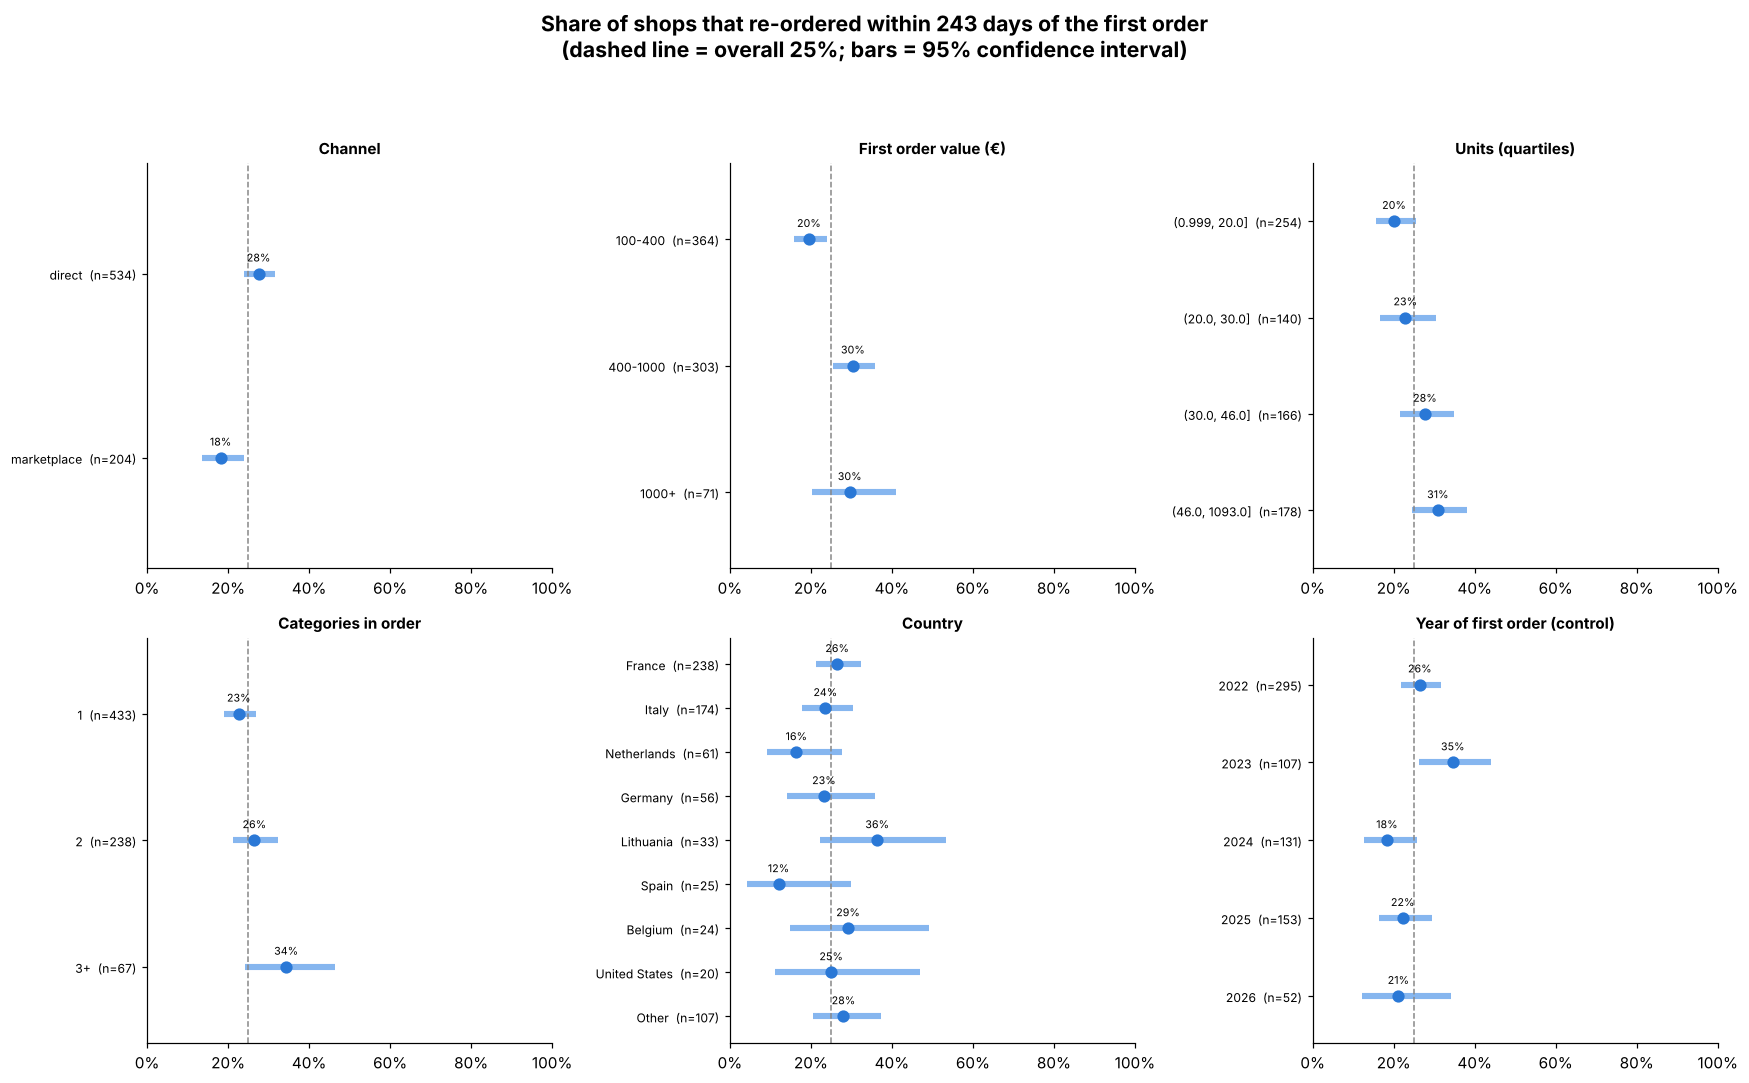

In [43]:
def rate_table(df: pd.DataFrame, col: str, outcome: str) -> pd.DataFrame:
    """Share of shops with outcome = 1 per group, with a 95% Wilson interval."""
    t = df.groupby(col, observed=True)[outcome].agg(shops="size", hits="sum")
    lo, hi = proportion_confint(t["hits"], t["shops"], method="wilson")
    return t.assign(rate=t["hits"] / t["shops"], ci_low=lo, ci_high=hi)


def plot_rate(ax, df: pd.DataFrame, col: str, title: str, outcome: str) -> None:
    """Dot + interval per group, with the overall rate as reference."""
    t = rate_table(df, col, outcome)
    if col == "country_group":
        t = t.sort_values("shops", ascending=False)
        t = pd.concat([t.drop(index="Other"), t.loc[["Other"]]])
    y = np.arange(len(t))
    ax.errorbar(t["rate"], y, xerr=[t["rate"] - t["ci_low"], t["ci_high"] - t["rate"]],
                fmt="o", color=MAIN_COLOUR, ecolor=ORDINAL_3[0], elinewidth=4, capsize=0, markersize=7)
    for yi, r in zip(y, t["rate"]):
        ax.annotate(f"{r:.0%}", (r, yi), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=7)
    ax.axvline(df[outcome].mean(), color=REFERENCE_GREY, linestyle="--", linewidth=1)
    ax.set_yticks(y, [f"{i}  (n={n})" for i, n in zip(t.index.astype(str), t["shops"])], fontsize=8)
    ax.set_ylim(len(t) - 0.4, -0.6)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title, fontsize=10)


def plot_rates(df: pd.DataFrame, outcome: str, title: str, name: str) -> None:
    """One panel per feature (and year, if used as a control)."""
    features = [("channel", "Channel"), ("value_group", "First order value (€)"),
                ("units_quartile", "Units (quartiles)"), ("n_categories_group", "Categories in order"),
                ("country_group", "Country")]
    if YEAR_CONTROL:
        features.append(("year", "Year of first order (control)"))
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (col, t) in zip(axes.flat, features):
        plot_rate(ax, df, col, t, outcome)
    for ax in list(axes.flat)[len(features):]:
        ax.axis("off")
    fig.suptitle(f"{title}\n(dashed line = overall {df[outcome].mean():.0%}; bars = 95% confidence interval)",
                 fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.94])
    save(fig, name)
    plt.show()


plot_rates(model_df, "retained", f"Share of shops that re-ordered within {REORDER_WINDOW} days of the first order",
           "R6_reorder_rates_by_feature")

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

Without the 2021 cohort, the model data has **738 shops** with first orders in 2022–2026, of which **184 (24.9%)** re-ordered within the window (564 shops and 25.4% without Italy). On their own, these features are associated with re-ordering:
- **a larger first order:** 20% for 100–400 € vs 30% for 400–1000 € and 30% for 1000+ €; 20% in the lowest unit quartile vs 31% in the highest;
- **the direct channel:** 28% vs 18% for marketplace shops;
- **more categories:** 23% (1 category) vs 34% (3+), with wide intervals;
- **country:** Lithuania is highest (36%, 33 shops); France (26%, 238 shops), Italy (24%, 174) and Germany (23%, 56) are close to the average; the Netherlands (16%, 61) and Spain (12%, 25) are lowest. Most country intervals are wide and overlap;
- **year (control):** 35% for 2023 first orders vs 18% for 2024.

These features overlap (marketplace orders are smaller and more recent, and all Italian shops are direct), so the regression in R6.2 is needed to separate them.

### R6.2 Logistic regression
The single-feature rates cannot separate features that move together (larger first orders are also more often direct, all Italian shops in the model are direct, and so on). A **logistic regression** estimates each feature's association with re-ordering **while holding the others fixed**. Results are **odds ratios** with 95% confidence intervals: 1 = no association, above 1 = higher odds of re-ordering, below 1 = lower odds (a *red flag*).

**Value and units in one model.** Both measure the size of the first order, so their effects have to be read together: *units doubled* means "twice as many units **within the same value group**" (i.e. cheaper products per unit), and each value group means "a higher value **at the same number of units**" (i.e. more expensive products). The check below (variance inflation factor, VIF) shows whether predictors overlap too strongly to be estimated separately; values above about 5 would be a problem.

**Year** (if used) is coded as a deviation from the average of all years, so each year is compared with an average year.

In [44]:
def nice_term(term: str) -> str:
    """Readable predictor names."""
    m = re.match(r"C\((\w+).*\)\[T\.(.+)\]", term)
    if m:
        var, level = m.groups()
        ref = {"value_group": "100-400 €", "channel": "direct", "n_categories_group": "1",
               "country_group": MODEL_REFERENCE_COUNTRY}.get(var, "reference")
        name = {"value_group": "Value", "channel": "Channel", "n_categories_group": "Categories",
                "country_group": "Country"}.get(var, var)
        unit = " €" if var == "value_group" else ""
        return f"{name} {level}{unit} (vs {ref})"
    return {"log2_units": "Units doubled"}.get(term, term)


PREDICTORS = ("C(channel, Treatment('direct')) + C(value_group, Treatment('100-400')) + log2_units"
              " + C(n_categories_group, Treatment('1'))"
              f" + C(country_group, Treatment('{MODEL_REFERENCE_COUNTRY}'))"
              + (" + C(year, Sum)" if YEAR_CONTROL else ""))


def formula(outcome: str) -> str:
    """Model formula: the same predictors for every outcome."""
    return f"{outcome} ~ {PREDICTORS}"


def vif_table(df: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each predictor column (year control left out)."""
    design = patsy.dmatrix(PREDICTORS, df, return_type="dataframe")
    cols = [c for c in design.columns if c != "Intercept" and not c.startswith("C(year")]
    return pd.Series([variance_inflation_factor(design.to_numpy(), design.columns.get_loc(c)) for c in cols],
                     index=cols)


vif = pd.DataFrame({name: vif_table(df) for name, df in MODEL_DATA.items()})
vif.index = [nice_term(i) for i in vif.index]
vif.round(2)

,with Italy,without Italy
Channel marketplace (vs direct),1.80,1.65
Country Belgium (vs France),1.19,1.19
Country Germany (vs France),1.25,1.25
Country Italy (vs France),1.61,NaN
Country Lithuania (vs France),1.18,1.17
Country Netherlands (vs France),1.26,1.23
Country Other (vs France),1.51,1.47
Country Spain (vs France),1.17,1.17
Country United States (vs France),1.24,1.25
Categories 2 (vs 1),1.21,1.22


In [45]:
def odds_ratios(res) -> pd.DataFrame:
    """Odds ratios with 95% CI, without intercept and year terms."""
    ci = res.conf_int()
    t = pd.DataFrame({"odds_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]),
                      "ci_high": np.exp(ci[1]), "p_value": res.pvalues})
    t = t.drop(index=[i for i in t.index if i == "Intercept" or i.startswith("C(year")])
    t.index = [nice_term(i) for i in t.index]
    return t


def year_effects(res, data: pd.DataFrame) -> pd.DataFrame:
    """Each year vs the average of all years, including the year the coding leaves out."""
    levels = sorted(data["year"].unique())
    terms = [p for p in res.params.index if p.startswith("C(year")]
    rows = []
    for i, lvl in enumerate(levels):
        c = np.zeros(len(res.params))
        if i < len(levels) - 1:
            c[res.params.index.get_loc(terms[i])] = 1
        else:
            for t in terms:
                c[res.params.index.get_loc(t)] = -1
        tt = res.t_test(c)
        lo, hi = tt.conf_int()[0]
        rows.append({"year": lvl, "odds_ratio": np.exp(tt.effect[0]), "ci_low": np.exp(lo),
                     "ci_high": np.exp(hi), "p_value": float(np.squeeze(tt.pvalue))})
    return pd.DataFrame(rows).set_index("year")


def fit_summary(res, data: pd.DataFrame, outcome: str) -> pd.Series:
    """Size and fit of a logistic model."""
    return pd.Series({"shops": int(res.nobs), f"{outcome} = 1": int(data[outcome].sum()),
                      "parameters": int(res.df_model), "converged": res.mle_retvals["converged"],
                      "McFadden R²": round(res.prsquared, 3),
                      "AUC (in-sample)": round(roc_auc_score(data[outcome], res.predict(data)), 3)})


def fit_models(outcome: str) -> dict:
    """Fit the model for one outcome on each data version (with / without the sensitivity country)."""
    return {name: smf.logit(formula(outcome), data=df).fit(disp=False) for name, df in MODEL_DATA.items()}


def side_by_side(tables: dict) -> pd.DataFrame:
    """Odds-ratio tables of several models next to each other (rows aligned by predictor)."""
    out = pd.concat(tables, axis=1)
    order = list(dict.fromkeys(i for t in tables.values() for i in t.index))
    return out.reindex(order)


OR_FORMAT = {"odds_ratio": "{:.2f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}", "p_value": "{:.3f}"}
RESULTS = fit_models("retained")
OR_TABLES = {name: odds_ratios(res) for name, res in RESULTS.items()}
display(pd.DataFrame({name: fit_summary(res, MODEL_DATA[name], "retained") for name, res in RESULTS.items()}))
side_by_side(OR_TABLES).style.format("{:.2f}", na_rep="–").format(
    "{:.3f}", subset=[(n, "p_value") for n in OR_TABLES], na_rep="–")

,with Italy,without Italy
shops,738,564
retained = 1,184,143
parameters,18,17
converged,True,True
McFadden R²,0.05,0.046
AUC (in-sample),0.656,0.643


Because value and units share information, their separate odds ratios can each look uncertain even when order size as a whole matters. The **joint tests** below check each predictor as a whole (all its levels together, e.g. *all countries*), and the size terms (value groups + units) together. A p-value below 0.05 means the predictor is associated with the outcome beyond chance.

In [46]:
def joint_tests(res) -> pd.DataFrame:
    """Wald test per predictor (all its levels together), plus value and units together."""
    t = res.wald_test_terms(scalar=True).table.drop(index="Intercept")
    out = pd.DataFrame({"chi2": t["statistic"].astype(float), "df": t["df_constraint"].astype(int),
                        "p_value": t["pvalue"].astype(float)})
    names = list(res.params.index)
    size_terms = [n for n in names if n.startswith("C(value_group") or n == "log2_units"]
    R = np.zeros((len(size_terms), len(names)))
    for k, n in enumerate(size_terms):
        R[k, names.index(n)] = 1
    w = res.wald_test(R, scalar=True)
    out.loc["order size (value groups + units)"] = [float(w.statistic), len(size_terms), float(w.pvalue)]
    out.index = [nice_term(i) if not i.startswith("C(") else re.sub(r"C\((\w+).*", r"\1", i) for i in out.index]
    return out


side_by_side({name: joint_tests(res) for name, res in RESULTS.items()}).style.format(
    {(n, c): f for n in RESULTS for c, f in [("chi2", "{:.2f}"), ("df", "{:.0f}"), ("p_value", "{:.3f}")]})

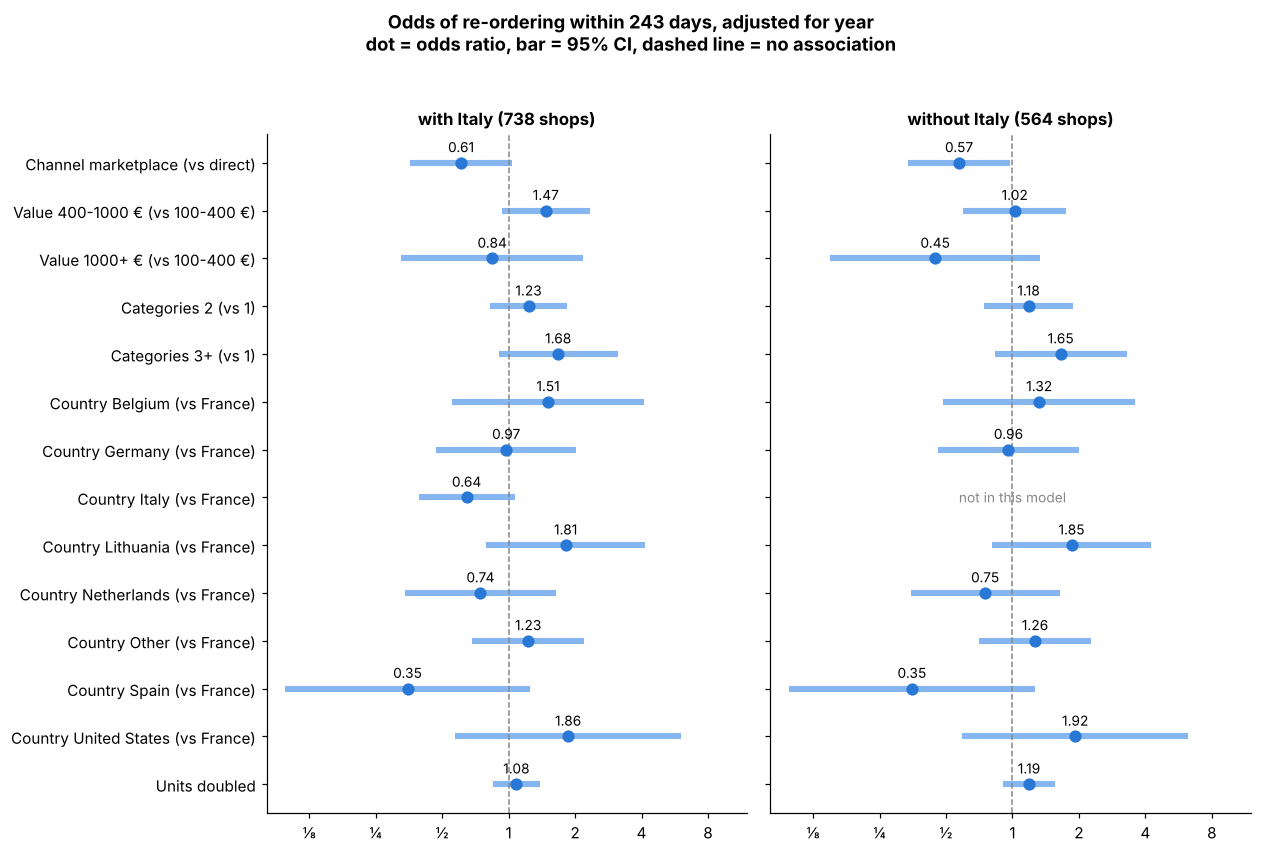

Year of first order vs an average year (control):


In [47]:
def forest(ax, t: pd.DataFrame, title: str) -> None:
    """Odds ratios with intervals on a log axis; rows with no estimate are left empty."""
    t = t.iloc[::-1]
    y = np.arange(len(t))
    ok = t["odds_ratio"].notna().to_numpy()
    ax.errorbar(t["odds_ratio"][ok], y[ok],
                xerr=[(t["odds_ratio"] - t["ci_low"])[ok], (t["ci_high"] - t["odds_ratio"])[ok]],
                fmt="o", color=MAIN_COLOUR, ecolor=ORDINAL_3[0], elinewidth=4, capsize=0, markersize=7)
    for yi, o in zip(y, t["odds_ratio"]):
        if pd.notna(o):
            ax.annotate(f"{o:.2f}", (o, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9)
        else:
            ax.annotate("not in this model", (1, yi), ha="center", va="center", fontsize=9, color=REFERENCE_GREY)
    ax.axvline(1, color=REFERENCE_GREY, linestyle="--", linewidth=1)
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_xticks([0.125, 0.25, 0.5, 1, 2, 4, 8], ["⅛", "¼", "½", "1", "2", "4", "8"])
    ax.set_xlim(0.08, 12)
    ax.set_yticks(y, t.index)
    ax.set_ylim(-0.6, len(t) - 0.4)
    ax.set_title(title, fontsize=11)


def plot_models(or_tables: dict, what: str, name: str) -> None:
    """Forest plots of the model versions next to each other, rows aligned."""
    rows = list(dict.fromkeys(i for t in or_tables.values() for i in t.index))
    fig, axes = plt.subplots(1, len(or_tables), figsize=(5.8 * len(or_tables), 0.42 * len(rows) + 2), sharey=True)
    for ax, (label, t) in zip(axes, or_tables.items()):
        forest(ax, t.reindex(rows), f"{label} ({int(RESULTS_N[label])} shops)")
    fig.suptitle(f"Odds of {what}, adjusted for year\n"
                 "dot = odds ratio, bar = 95% CI, dashed line = no association",
                 fontsize=12, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    save(fig, name)
    plt.show()


RESULTS_N = {name: len(df) for name, df in MODEL_DATA.items()}
with plt.rc_context(REPORT_RC):
    plot_models(OR_TABLES, f"re-ordering within {REORDER_WINDOW} days", "R6_odds_ratios")
if YEAR_CONTROL:
    print("Year of first order vs an average year (control):")
    display(side_by_side({n: year_effects(r, MODEL_DATA[n]) for n, r in RESULTS.items()})
            .style.format("{:.2f}").format("{:.3f}", subset=[(n, "p_value") for n in RESULTS]))

### R6.3 Positive signals and red flags
Predictors whose interval is entirely above 1 (positive signal) or entirely below 1 (red flag), in each model version. Everything else is not distinguishable from "no association" with this amount of data.

In [48]:
def signals(t: pd.DataFrame, above: str = "positive signal", below: str = "red flag") -> pd.Series:
    """Classify odds ratios whose 95% interval excludes 1."""
    return pd.Series(np.select([t["ci_low"] > 1, t["ci_high"] < 1], [above, below],
                               default="not distinguishable"), index=t.index)


def signal_table(or_tables: dict, **labels) -> pd.DataFrame:
    """Odds ratio and signal per model version, sorted by the first version's odds ratio."""
    parts = {}
    for name, t in or_tables.items():
        parts[(name, "odds_ratio")] = t["odds_ratio"]
        parts[(name, "signal")] = signals(t, **labels)
    out = pd.DataFrame(parts)
    first = next(iter(or_tables))
    return out.sort_values((first, "odds_ratio"), ascending=False)


signal_table(OR_TABLES).style.format({(n, "odds_ratio"): "{:.2f}" for n in OR_TABLES}, na_rep="–")

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

**What the models show** (first orders 2022–2026; with Italy: 738 shops, 184 re-orders; without Italy: 564 shops, 143 re-orders; 18 and 17 parameters; both fits converged)

**Country (Candlehand's question)**
- **Country is not clearly related to re-ordering once the other features are taken into account.** The countries as a whole are not significant (joint test p = 0.15 with Italy, 0.34 without), and no single country's interval excludes 1.
- The estimates point the same way as the single-country rates: compared with France, Lithuania 1.8× (CI 0.79–4.15), the United States 1.9× (CI 0.57–6.03), Spain 0.35× (CI 0.10–1.26), the Netherlands 0.74× (CI 0.34–1.63) and Italy 0.64× (CI 0.39–1.07, p = 0.09). With 20–60 shops per country, a real difference of this size cannot be confirmed; the intervals are compatible with no difference.
- **The country estimates do not change when Italy is removed** (e.g. Lithuania 1.81 with Italy, 1.85 without), so Italy does not distort the comparison between the other countries.

**Effect of Italy on the other predictors**
- **The first-order value effect comes from Italy.** With Italy, a 400–1000 € first order has 1.47× the odds of a 100–400 € order (CI 0.93–2.33), and the value groups together are borderline (p = 0.066). Without Italy the effect disappears (1.02×, CI 0.60–1.76; joint p = 0.17). In Italy, only 11% of shops with a 100–400 € first order re-ordered, against 32% (400–1000 €) and 50% (1000+ €). In the other countries the differences are small (22%, 30%, 27%).
- **The marketplace channel becomes a red flag without Italy:** 0.57× the odds of direct shops (CI 0.34–0.98, p = 0.041), compared with 0.61× (CI 0.36–1.03, p = 0.07) with Italy. All Italian shops are direct and Italy is close to average, so it adds direct shops of a different kind to the comparison. The estimate is similar in both versions; only the p-value crosses 0.05, so this is a weak result.
- **Categories and units are not distinguishable** in either version.
- **Year of first order remains a clear factor** (joint p = 0.005 with Italy, 0.064 without): 2022 and 2023 starters re-ordered more than average.
- **The models explain little** (McFadden R² 0.05, in-sample AUC 0.64–0.66).
- **Multiple testing:** 14 odds ratios are estimated in each version, so one result near p = 0.05 (such as the channel without Italy) could be chance.

**Practical reading**
- Country is not a reliable early signal for re-ordering. Lithuania tends to re-order more and Spain and the Netherlands less, but the data is too thin to confirm it.
- A small first order is a warning sign **in Italy**; elsewhere the size of the first order says little. Marketplace shops are somewhat less likely to return in both versions.

## R7. One-order shops: what predicts a shop never coming back?

**Question.** R6 asks what predicts a **quick** second order. Here the question is turned around: which first-order features, including country, are associated with a shop that **never placed a second order** (up to the data end)? If such features exist, they are the ones to avoid or to act on early.

**Set-up**
- The **same shops** as in R6 (eligible, first order in 2022–2026), the **same predictors** (with country) and the same two versions (**with and without Italy**), so the models can be compared directly.
- **Outcome:** `one_order` = 1 if the shop has exactly one order in all the data.
- Odds ratios above 1 now mean **higher odds of staying at one order** (a *risk*); below 1 means lower odds (*protective*).

**How the two outcomes relate.** Every shop that re-ordered within the window has more than one order, so `retained = 1` always means `one_order = 0`. The two outcomes differ only for shops that re-ordered **later than the window**: they count as "not retained" in R6 but as "not one-order" here. The table below shows how many such shops there are; if there are few, the two models are close to mirror images and R7 cannot add much.

**Caveat: unequal follow-up.** A shop that started in 2022 has had almost four years to place a second order; a shop from February 2026 has had eight months. "One order" therefore partly measures how recently the shop started. The year control (`YEAR_CONTROL`) absorbs the differences between years, but not within a year.

In [49]:
def outcome_overlap(df: pd.DataFrame) -> pd.DataFrame:
    """Shops by the two outcomes: retained within the window, later re-order, one order only."""
    status = np.select([df["retained"] == 1, df["one_order"] == 0],
                       [f"re-ordered within {REORDER_WINDOW} days", "re-ordered later"], default="one order only")
    t = pd.Series(status, index=df.index).value_counts().to_frame("shops")
    t["share"] = t["shops"] / t["shops"].sum()
    return t


outcome_overlap(model_df).style.format({"share": "{:.1%}"})

,shops,share
one order only,503,68.2%
re-ordered within 243 days,184,24.9%
re-ordered later,51,6.9%


### R7.1 Share of one-order shops by each feature

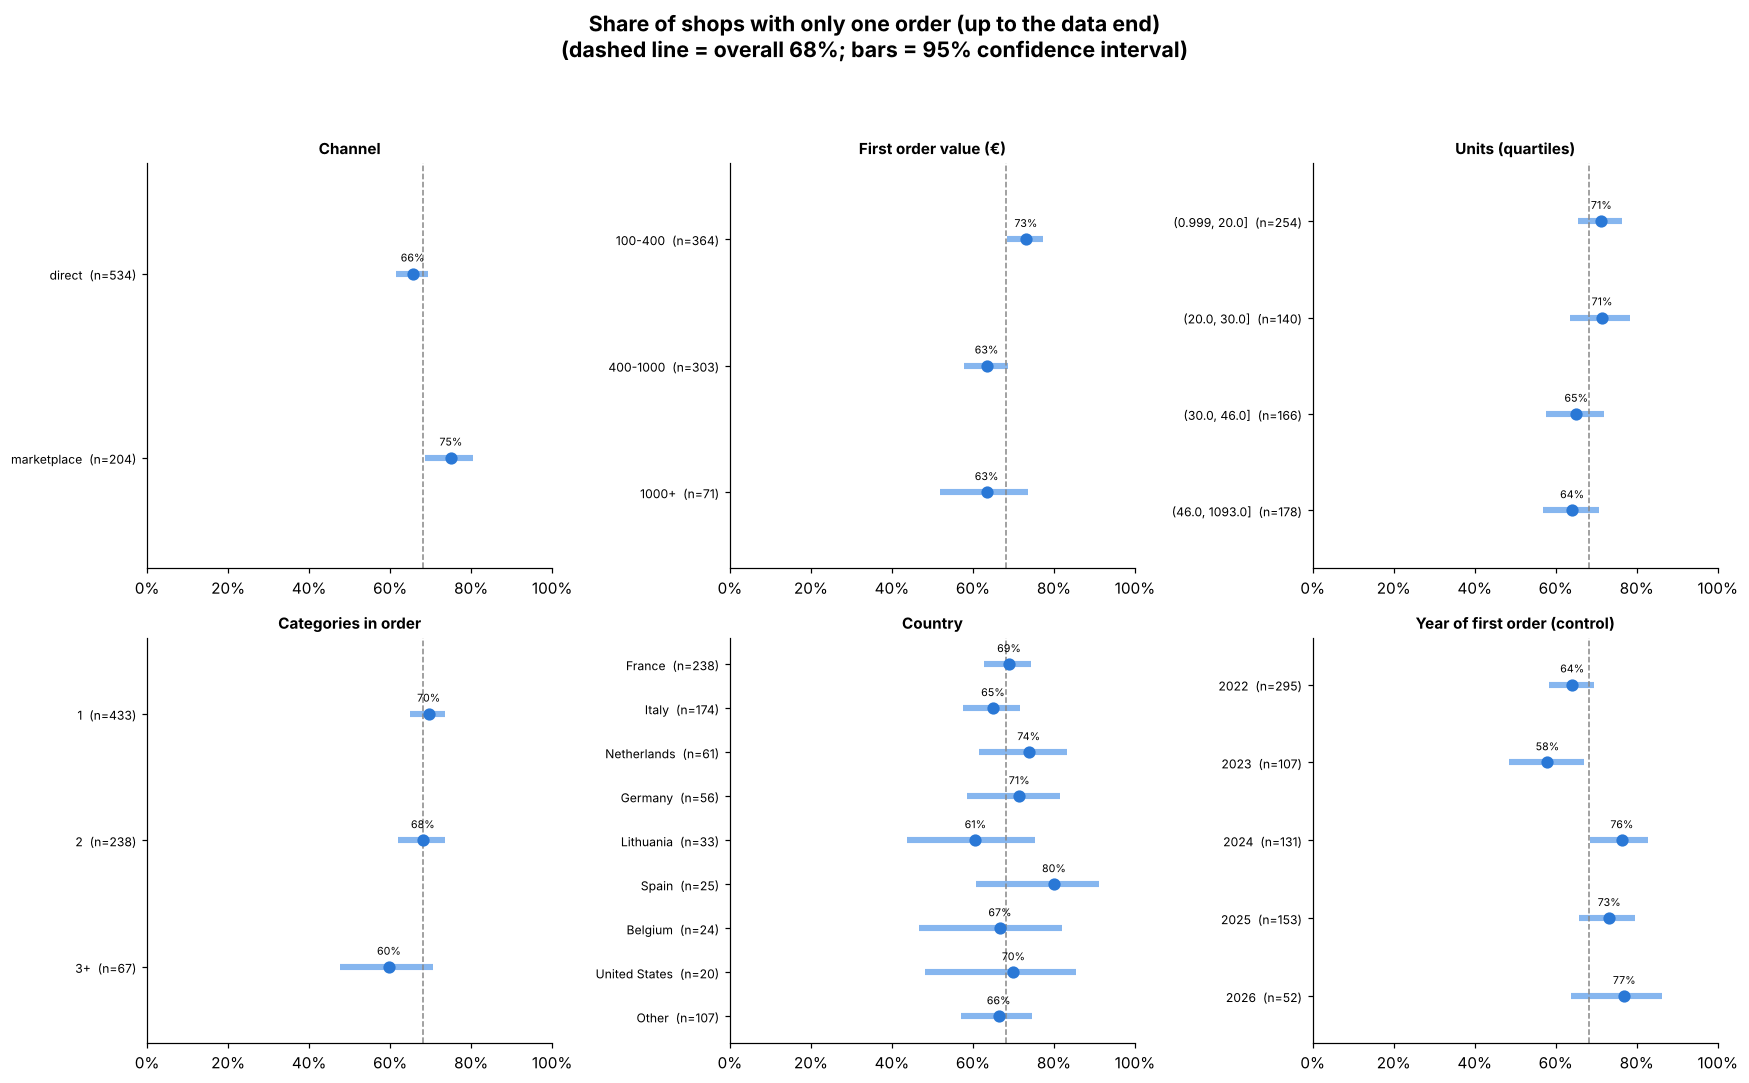

In [50]:
plot_rates(model_df, "one_order", "Share of shops with only one order (up to the data end)",
           "R7_one_order_rates_by_feature")

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

Of the 738 shops, **503 (68.2%) placed only one order** up to the data end, **184 (24.9%)** re-ordered within the window and **51 (6.9%)** re-ordered later. So **only 51 shops (7%) are classified differently** by the two outcomes.

The single-feature shares are mostly the mirror image of R6.1: one-order shops are more common among marketplace shops (75% vs 66%), small first orders (73% for 100–400 € vs 63% for 400–1000 €), single-category orders (70% vs 60% for 3+) and recent years (76–77% for 2024 and 2026 vs 58% for 2023). By country, Spain (80%) and the Netherlands (74%) have the most one-order shops and Lithuania the fewest (61%).

**One exception: Italy.** Italy's share of one-order shops (65%) is *below* average, although its share of quick re-orders (24%) is about average. Italian shops come back, but more slowly: 12% of them re-ordered only after the window (6% in the other countries), and the median time to the second order is 154 days (90 days elsewhere).

### R7.2 Logistic regression for one-order shops
The same models as in R6.2 (with and without Italy), with `one_order` as the outcome.

In [51]:
RESULTS_ONE = fit_models("one_order")
OR_TABLES_ONE = {name: odds_ratios(res) for name, res in RESULTS_ONE.items()}
display(pd.DataFrame({name: fit_summary(res, MODEL_DATA[name], "one_order") for name, res in RESULTS_ONE.items()}))
display(side_by_side({name: joint_tests(res) for name, res in RESULTS_ONE.items()}).style.format(
    {(n, c): f for n in RESULTS_ONE for c, f in [("chi2", "{:.2f}"), ("df", "{:.0f}"), ("p_value", "{:.3f}")]}))
signal_table(OR_TABLES_ONE, above="risk (more one-order)", below="protective").style.format(
    {(n, "odds_ratio"): "{:.2f}" for n in OR_TABLES_ONE}, na_rep="–")

,with Italy,without Italy
shops,738,564
one_order = 1,503,390
parameters,18,17
converged,True,True
McFadden R²,0.04,0.03
AUC (in-sample),0.636,0.615


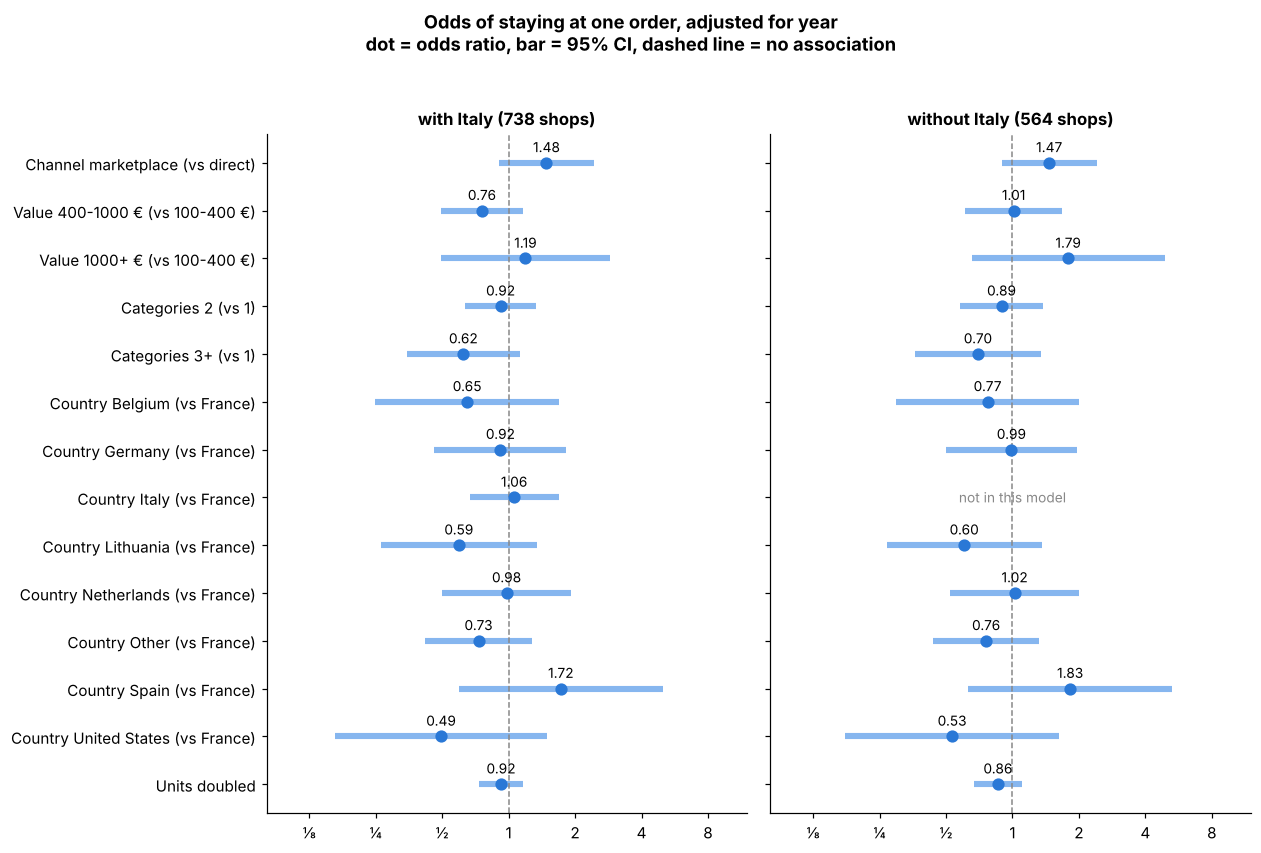

In [52]:
with plt.rc_context(REPORT_RC):
    plot_models(OR_TABLES_ONE, "staying at one order", "R7_odds_ratios")

### R7.3 Comparison with the re-order model
If one-order shops were simply the opposite of quick re-orderers, each odds ratio here would be close to **1 ÷ the odds ratio in R6**. The table puts the two side by side (model with Italy): `R6 mirrored` is 1 ÷ the R6 odds ratio, so it is on the same scale as the R7 odds ratio. Large differences between these two columns would mean that R7 tells something new.

In [53]:
def compare_models(or_retained: pd.DataFrame, or_one: pd.DataFrame) -> pd.DataFrame:
    """R7 odds ratios next to the mirrored R6 odds ratios (1 / OR), with both p-values."""
    return pd.DataFrame({"R7 one-order OR": or_one["odds_ratio"],
                         "R6 mirrored (1 / OR)": 1 / or_retained["odds_ratio"],
                         "R7 p": or_one["p_value"], "R6 p": or_retained["p_value"]})


COMPARISON = compare_models(OR_TABLES["with Italy"], OR_TABLES_ONE["with Italy"])
print("Correlation of the two predicted probabilities (per shop, model with Italy):",
      round(np.corrcoef(RESULTS["with Italy"].predict(model_df),
                        RESULTS_ONE["with Italy"].predict(model_df))[0, 1], 3))
COMPARISON.style.format({"R7 one-order OR": "{:.2f}", "R6 mirrored (1 / OR)": "{:.2f}",
                         "R7 p": "{:.3f}", "R6 p": "{:.3f}"})

Correlation of the two predicted probabilities (per shop, model with Italy): -0.929


,R7 one-order OR,R6 mirrored (1 / OR),R7 p,R6 p
Channel marketplace (vs direct),1.48,1.64,0.116,0.067
Value 400-1000 € (vs 100-400 €),0.76,0.68,0.197,0.097
Value 1000+ € (vs 100-400 €),1.19,1.19,0.697,0.723
Categories 2 (vs 1),0.92,0.81,0.659,0.310
Categories 3+ (vs 1),0.62,0.60,0.117,0.102
Country Belgium (vs France),0.65,0.66,0.377,0.422
Country Germany (vs France),0.92,1.03,0.807,0.945
Country Italy (vs France),1.06,1.55,0.809,0.087
Country Lithuania (vs France),0.59,0.55,0.209,0.160
Country Netherlands (vs France),0.98,1.34,0.950,0.462


*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

**What the one-order models show** (with Italy: 738 shops, 503 one-order shops; without Italy: 564 and 390; both fits converged)
- **No first-order feature and no country is a clear risk factor** in either version; every interval includes 1. The largest estimates: marketplace 1.48× the odds of staying at one order (CI 0.91–2.43); Spain 1.72× (CI 0.59–5.00) and the United States 0.49× (CI 0.16–1.50) compared with France. Country as a whole: p = 0.65 (with Italy) and 0.64 (without).
- **Year is again the only clear factor** (joint p = 0.001 with Italy, 0.043 without). Part of this is the unequal follow-up: 2022 shops have had the most time to come back.
- **The models explain very little** (McFadden R² 0.03–0.04, AUC 0.62–0.64).

**Does R7 tell anything new about customer behaviour? Mostly no, with one exception.**
- **The two models are still close to mirror images.** Most R7 odds ratios are close to 1 ÷ the R6 odds ratio (e.g. Lithuania 0.59 vs 0.55, units doubled 0.92 vs 0.92), and the predicted probabilities per shop have a correlation of −0.93. Only 51 shops (7%) differ between the two outcomes.
- **The exception is Italy:** in R6 Italian shops have lower odds of a *quick* re-order than French shops (0.64×, mirrored 1.55), but in R7 their odds of *never* re-ordering are the same as in France (1.06×). Italian shops are not lost more often; they come back later than the 243-day window (R7.1). For Italy, a longer follow-up period is appropriate before treating a shop as lost.
- **The idea of finding what to avoid is sound, but this data does not support it.** No feature of the first order, and no country, clearly marks a shop that will never return.
- **What would add new information:** features not in this data (shop type, city, online presence, whether the first order paid shipping), or a survival model of the time to the second order (R8 gives the descriptive part).

## R8. Time to the second order (Kaplan–Meier)

**Question.** R6 and R7 reduce the second order to yes/no: within a fixed window, or ever. Here the question is **when** shops come back: what share of new shops has placed a second order after 1, 3, 6, 12 months, and does this differ by channel, first-order value, year and the product category of the first order?

**Category of the first order.** A first order can contain several categories, but each shop must be in exactly one group for the curves and the test. Each shop is therefore assigned its **main category**: the one with the most units in its first order (ties go to the category listed first in `MAIN_CATEGORIES`). Shops whose first order is mainly outside the four main categories form the group "Other".

**Method: Kaplan–Meier curves.** Each shop is followed from its first order until its second order (the *event*) or until the data end, whichever comes first. A shop without a second order is **censored**: we only know that it has not re-ordered *yet*, after the time it has been observed. Censored shops are not counted as lost; they count as "not re-ordered" for as long as they were observed and then leave the calculation. This means:
- **all shops can be used**, also those that started after the eligibility cut-off of R6 (only the first data year is left out, as in R6, with `INCLUDE_FIRST_YEAR_IN_MODEL`);
- **no window has to be chosen**, and shops with short and long follow-up are compared fairly.

The curves show **1 − Kaplan–Meier survival**, i.e. the estimated share of shops that have placed a second order by each day after their first order. A flat end of a curve means that shops still at one order after that point rarely come back. Each curve stops where fewer than `KM_MIN_AT_RISK` (10) shops are still followed, because beyond that point a single shop moves the curve by several percentage points. The vertical line marks the re-order window used in R1 and R6 (`REORDER_WINDOW`). The **log-rank test** checks whether the curves of a feature differ more than chance would explain.

In [54]:
def first_order_category(lines: pd.DataFrame, orders: pd.DataFrame) -> pd.Series:
    """Main category of each shop's first order: the category with the most units.

    :return: one category per shop_id (ties go to the earlier category in CATEGORY_ORDER)
    """
    first_ids = orders.loc[orders["order_no"] == 1, "order_id"]
    units = (lines[lines["order_id"].isin(first_ids)]
             .groupby(["shop_id", "category"])["Quantity total"].sum().unstack(fill_value=0)
             .reindex(columns=CATEGORY_ORDER, fill_value=0))
    return units.idxmax(axis=1)


def survival_data(shops: pd.DataFrame, data_end: pd.Timestamp, include_first_year: bool,
                  first_category: pd.Series) -> pd.DataFrame:
    """One row per shop: days observed, whether the second order happened, and grouping features.

    :param data_end: last date in the data; shops without a second order are censored here
    :param include_first_year: keep shops whose first order is in the first (partial) data year
    :param first_category: main category of each shop's first order
    :return: table with duration (days), event (1 = second order) and the groups used in R8
    """
    s = shops.copy()
    if not include_first_year:
        s = s[s["cohort"] > shops["cohort"].min()]
    s["event"] = s["days_to_second"].notna().astype(int)
    s["duration"] = s["days_to_second"].fillna((data_end - s["first_date"]).dt.days)
    s["value_group"] = pd.Categorical(
        size_group(s["first_value"]).astype(str).str.replace("–", "-"), categories=VALUE_LEVELS)
    s["year"] = s["cohort"].astype(str)
    s["first_category"] = first_category.reindex(s.index)
    assert (s["duration"] >= 0).all(), "negative duration"
    assert s["first_category"].notna().all(), "shop without a first-order category"
    return s


surv_df = survival_data(shops, DATA_END, INCLUDE_FIRST_YEAR_IN_MODEL, first_order_category(order_lines, orders))
print(f"Shops: {len(surv_df)} (first orders {surv_df['cohort'].min()}–{surv_df['cohort'].max()}), "
      f"second order observed: {surv_df['event'].sum()}, censored (no second order yet): "
      f"{(surv_df['event'] == 0).sum()}")
print("Shops by main category of the first order:",
      surv_df["first_category"].value_counts().reindex(CATEGORY_ORDER).to_dict())
print("Follow-up of censored shops (days):",
      surv_df.loc[surv_df["event"] == 0, "duration"].describe()[["min", "50%", "max"]].round().to_dict())

Shops: 873 (first orders 2022–2026), second order observed: 250, censored (no second order yet): 623
Shops by main category of the first order: {'Hand Gesture candles': 414, 'Baby hand candle': 44, 'CandleCan': 278, '3D Taper Candles': 116, 'Other': 21}
Follow-up of censored shops (days): {'min': 0.0, '50%': 778.0, 'max': 1756.0}


### R8.1 All shops

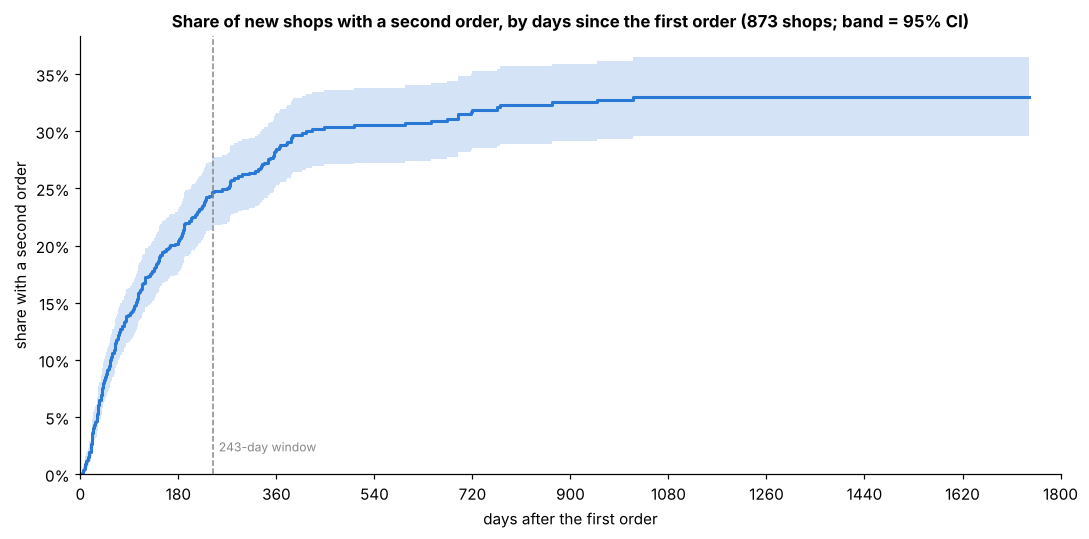

,share re-ordered,shops still at risk
days after first order,,
30,4.8%,805
90,13.9%,685
180,20.4%,619
243,24.6%,554
365,28.6%,468
730,31.9%,343


In [55]:
CHECK_DAYS = [30, 90, 180, REORDER_WINDOW, 365, 730]


def km(df: pd.DataFrame) -> SurvfuncRight:
    """Kaplan–Meier estimate of the time to the second order."""
    return SurvfuncRight(df["duration"].to_numpy(), df["event"].to_numpy())


def share_reordered(sf: SurvfuncRight, days: list[int]) -> np.ndarray:
    """1 − survival at the given days (step function)."""
    idx = np.searchsorted(sf.surv_times, days, side="right") - 1
    surv = np.where(idx >= 0, sf.surv_prob[np.clip(idx, 0, None)], 1.0)
    return 1 - surv


def km_table(df: pd.DataFrame, days: list[int]) -> pd.DataFrame:
    """Share re-ordered and shops still observed and at one order, at selected days.

    Days where fewer than KM_MIN_AT_RISK shops are still followed are shown as missing.
    """
    sf = km(df)
    at_risk = np.array([(df["duration"] >= d).sum() for d in days])
    share = np.where(at_risk >= KM_MIN_AT_RISK, share_reordered(sf, days), np.nan)
    return pd.DataFrame({"share re-ordered": share,
                         "shops still at risk": [(df["duration"] >= d).sum() for d in days]},
                        index=pd.Index(days, name="days after first order"))


def last_reliable_day(df: pd.DataFrame) -> float:
    """Last day at which at least KM_MIN_AT_RISK shops are still followed."""
    d = np.sort(df["duration"].to_numpy())[::-1]
    return float(d[KM_MIN_AT_RISK - 1]) if len(d) >= KM_MIN_AT_RISK else 0.0


def step_curve(ax, df: pd.DataFrame, label: str, colour: str, band: bool = False) -> None:
    """Draw 1 − survival as a step line up to the last reliable day, optionally with a 95% band."""
    sf = km(df)
    end = last_reliable_day(df)
    keep = sf.surv_times <= end
    t = np.r_[0, sf.surv_times[keep], end]
    prob = np.r_[1, sf.surv_prob[keep]]
    y = 1 - np.r_[prob, prob[-1]]
    ax.step(t, y, where="post", color=colour, linewidth=2, label=label)
    if band:
        se = np.r_[0, sf.surv_prob_se[keep]]
        se = np.r_[se, se[-1]]
        ax.fill_between(t, np.clip(y - 1.96 * se, 0, 1), np.clip(y + 1.96 * se, 0, 1),
                        step="post", color=colour, alpha=0.2, linewidth=0)


def style_km_axis(ax, title: str) -> None:
    """Common axis layout for the curves."""
    ax.axvline(REORDER_WINDOW, color=REFERENCE_GREY, linestyle="--", linewidth=1)
    ax.annotate(f"{REORDER_WINDOW}-day window", (REORDER_WINDOW, 0.02), xytext=(4, 0),
                textcoords="offset points", fontsize=8, color=REFERENCE_GREY)
    x_max = int(np.ceil(last_reliable_day(surv_df) / 180) * 180)
    ax.set_xlim(0, x_max)
    ax.set_xticks(range(0, x_max + 1, 180))
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.set_xlabel("days after the first order")
    ax.set_ylabel("share with a second order")
    ax.set_title(title, fontsize=11)


fig, ax = plt.subplots(figsize=(10, 5))
step_curve(ax, surv_df, "all shops", MAIN_COLOUR, band=True)
style_km_axis(ax, f"Share of new shops with a second order, by days since the first order "
                  f"({len(surv_df)} shops; band = 95% CI)")
fig.tight_layout()
save(fig, "R8_km_all")
plt.show()

km_table(surv_df, CHECK_DAYS).style.format({"share re-ordered": "{:.1%}"})

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **873 shops** with first orders in 2022–2026 are followed, 135 more than in R6, because shops that started after the eligibility cut-off can be used. **250** placed a second order; 623 had not (yet) by the data end.
- **Most shops that come back do so within the first months:** about 5% have re-ordered after 30 days, 14% after 90 days, 20% after 180 days and 25% after the 243-day window.
- **After about a year the curve is almost flat:** 29% after 365 days and 32% after 730 days. Roughly three-quarters of the second orders seen within two years happen within the 243-day window. A shop still at one order a year after its first order is unlikely to return.
- So the 243-day window used in R1 and R6 captures most re-orders, and "about one in three new shops ever re-orders" is a fair summary.

### R8.2 By channel, first-order value, year and category
Each panel shows one curve per group, with the log-rank p-value in the title. The table below gives the share re-ordered at selected days per group.

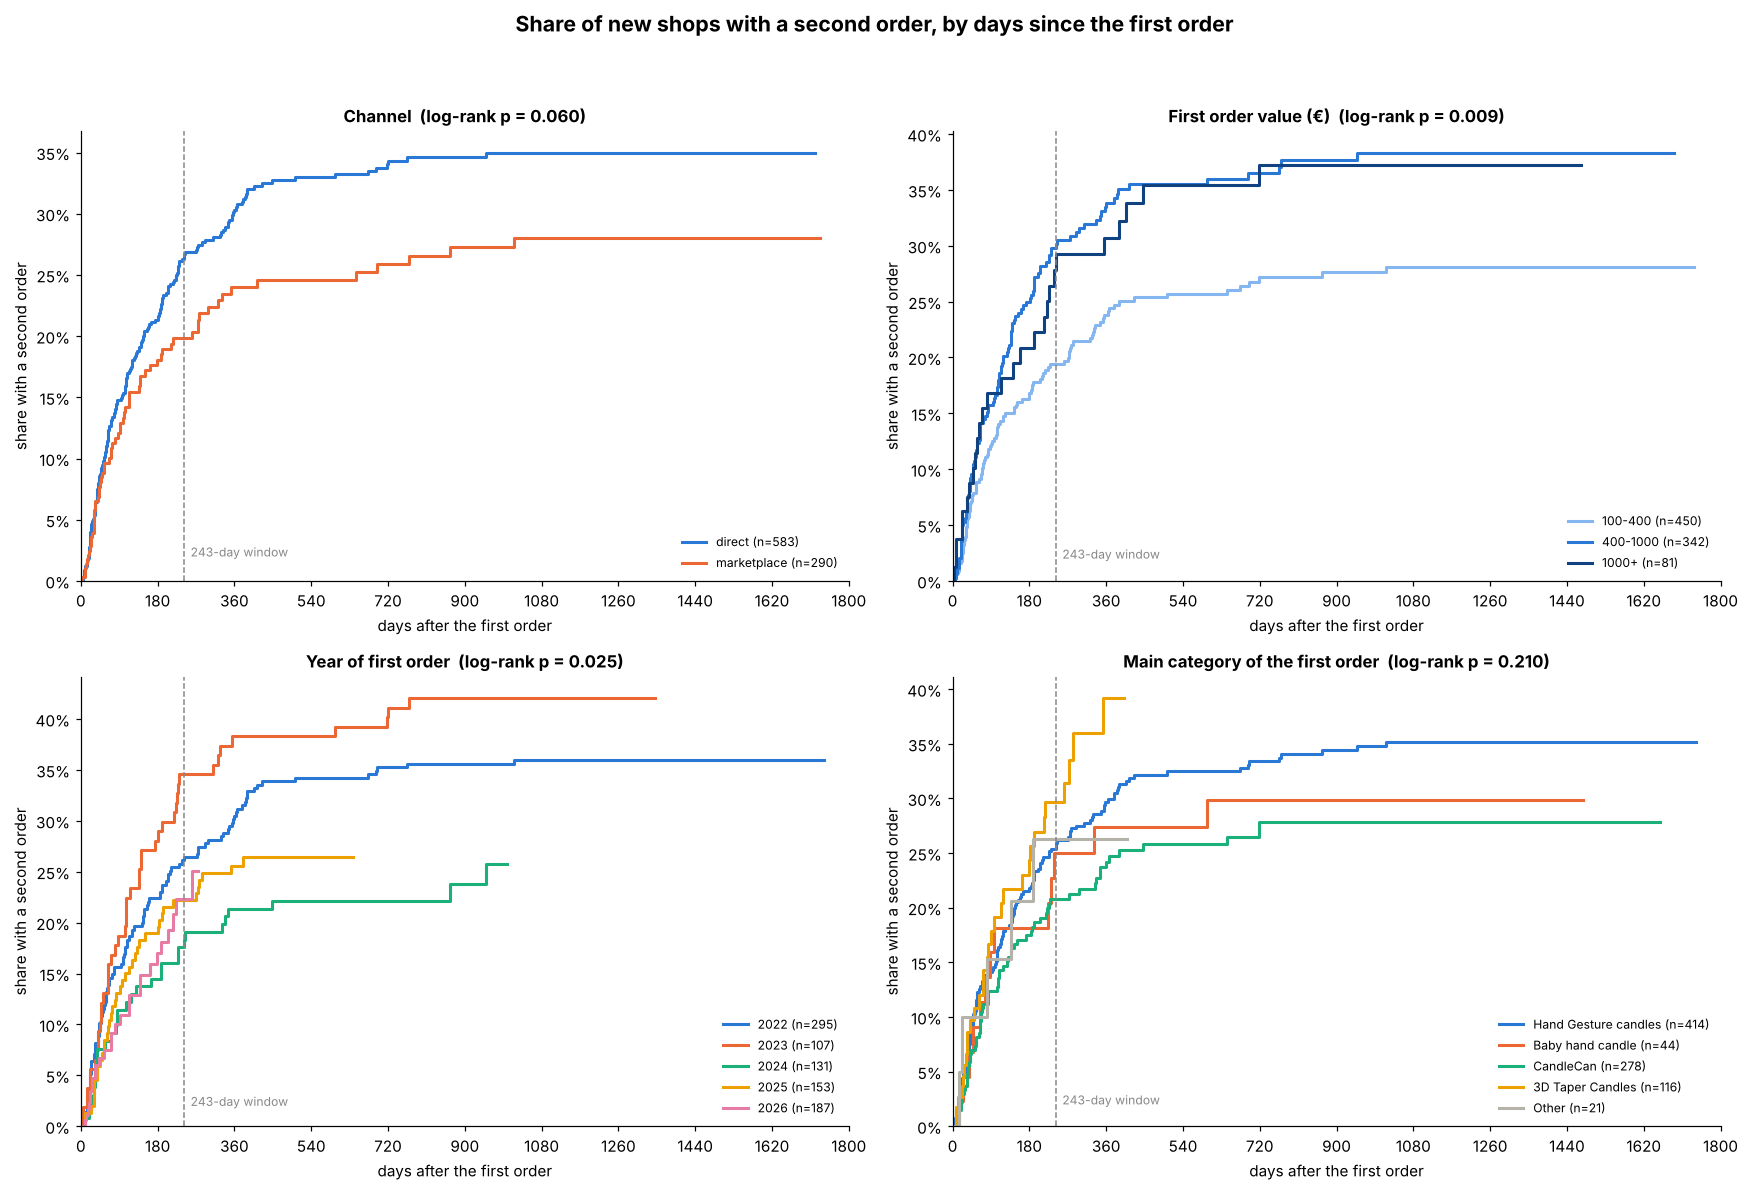

In [56]:
KM_GROUPS = [("channel", "Channel", ["direct", "marketplace"]),
             ("value_group", "First order value (€)", VALUE_LEVELS),
             ("year", "Year of first order", sorted(surv_df["year"].unique())),
             ("first_category", "Main category of the first order",
              [c for c in CATEGORY_ORDER if (surv_df["first_category"] == c).sum() >= KM_MIN_AT_RISK])]


def logrank_p(df: pd.DataFrame, col: str, levels: list) -> float:
    """Log-rank test: do the curves of the shown groups differ?"""
    df = df[df[col].astype(str).isin([str(v) for v in levels])]
    _, p = survdiff(df["duration"].to_numpy(), df["event"].to_numpy(), df[col].astype(str).to_numpy())
    return float(p)


def group_colours(col: str, levels: list) -> list:
    """Ordered blues for value groups, the category colours of R4 for categories, categorical otherwise."""
    if col == "value_group":
        return ORDINAL_3
    if col == "first_category":
        return [CATEGORY_COLOURS[CATEGORY_ORDER.index(c)] for c in levels]
    return CATEGORICAL[:len(levels)]


fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (col, title, levels) in zip(axes.flat, KM_GROUPS):
    for lvl, colour in zip(levels, group_colours(col, levels)):
        part = surv_df[surv_df[col].astype(str) == str(lvl)]
        step_curve(ax, part, f"{lvl} (n={len(part)})", colour)
    style_km_axis(ax, f"{title}  (log-rank p = {logrank_p(surv_df, col, levels):.3f})")
    ax.legend(fontsize=8, frameon=False, loc="lower right")
fig.suptitle("Share of new shops with a second order, by days since the first order",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.95])
save(fig, "R8_km_by_group")
plt.show()

rows = []
for col, title, levels in KM_GROUPS:
    for lvl in levels:
        part = surv_df[surv_df[col].astype(str) == str(lvl)]
        t = km_table(part, [90, REORDER_WINDOW, 365, 730])["share re-ordered"]
        rows.append(pd.Series(t.to_numpy(), index=[f"{d} days" for d in t.index],
                              name=(title, f"{lvl} (n={len(part)})")))
pd.DataFrame(rows).style.format("{:.1%}", na_rep="–")

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

These are single-feature comparisons (as in R6.1), not adjusted for the other features.
- **First-order value shows the clearest difference** (log-rank p = 0.009): shops with a 100–400 € first order re-order more slowly and less often (19% after 243 days, 27% after two years) than shops with 400–1000 € (30% and 37%). The 1000+ € group (81 shops) is close to the 400–1000 € group.
- **Channel** (p = 0.060, borderline): the curves are the same for the first two months and then separate; after two years 34% of direct shops have re-ordered vs 26% of marketplace shops.
- **Year of first order** (p = 0.025): shops from 2023 re-ordered most (35% after 243 days), shops from 2024 least (18%). The 2025 and 2026 shops are between the two and similar to each other so far (22% after 243 days; for 2026 this rests on 41 shops followed that long).
- **Main category of the first order** (p = 0.21): the curves are not distinguishable. Shops whose first order was mainly Hand Gesture candles (414 shops) reach 26% after 243 days and 33% after two years, and CandleCan shops (278) 21% and 28%. 3D Taper shops (116) look highest (30% after 243 days, 39% after a year), but they all started in 2025–2026, so their curve is short and rests on few shops after 243 days (44 followed that long, 19 after a year). Category is also tied to time: Hand Gesture shops mostly started in 2022, 3D Taper shops only in 2025–2026. A difference between categories could therefore be a difference between years. Baby hand (44 shops) and "Other" (21) are too small to read.
- **Compared with R6:** the value difference is clearer here than in the adjusted logistic model (R6.2), where the value effect was borderline and disappeared without Italian shops. R8 uses more shops and the timing of the second order, but does not separate value from channel and year. Value and these features overlap, so this result does not show that value matters *on its own*.

**Practical reading**
- Follow-up after a first order is most useful **in the first months**: by six months, most of the shops that will ever re-order have done so.
- Shops with a small first order (under 400 €) are the group that re-orders least and latest.

### R8.3 By country (top 20 by invoice value)
One small panel per country of the top 20 (R5.2), in the order of their invoice value. The grey line is the curve of all shops, for comparison. As in the other panels, a curve stops where fewer than `KM_MIN_AT_RISK` (10) shops are still followed; countries with fewer shops than that are marked but not drawn, because their curve would be decided by one or two shops.

The log-rank test and the table below use the countries with at least `MIN_MODEL_COUNTRY_SHOPS` (10) shops, the same rule as the models in R6 and R7.

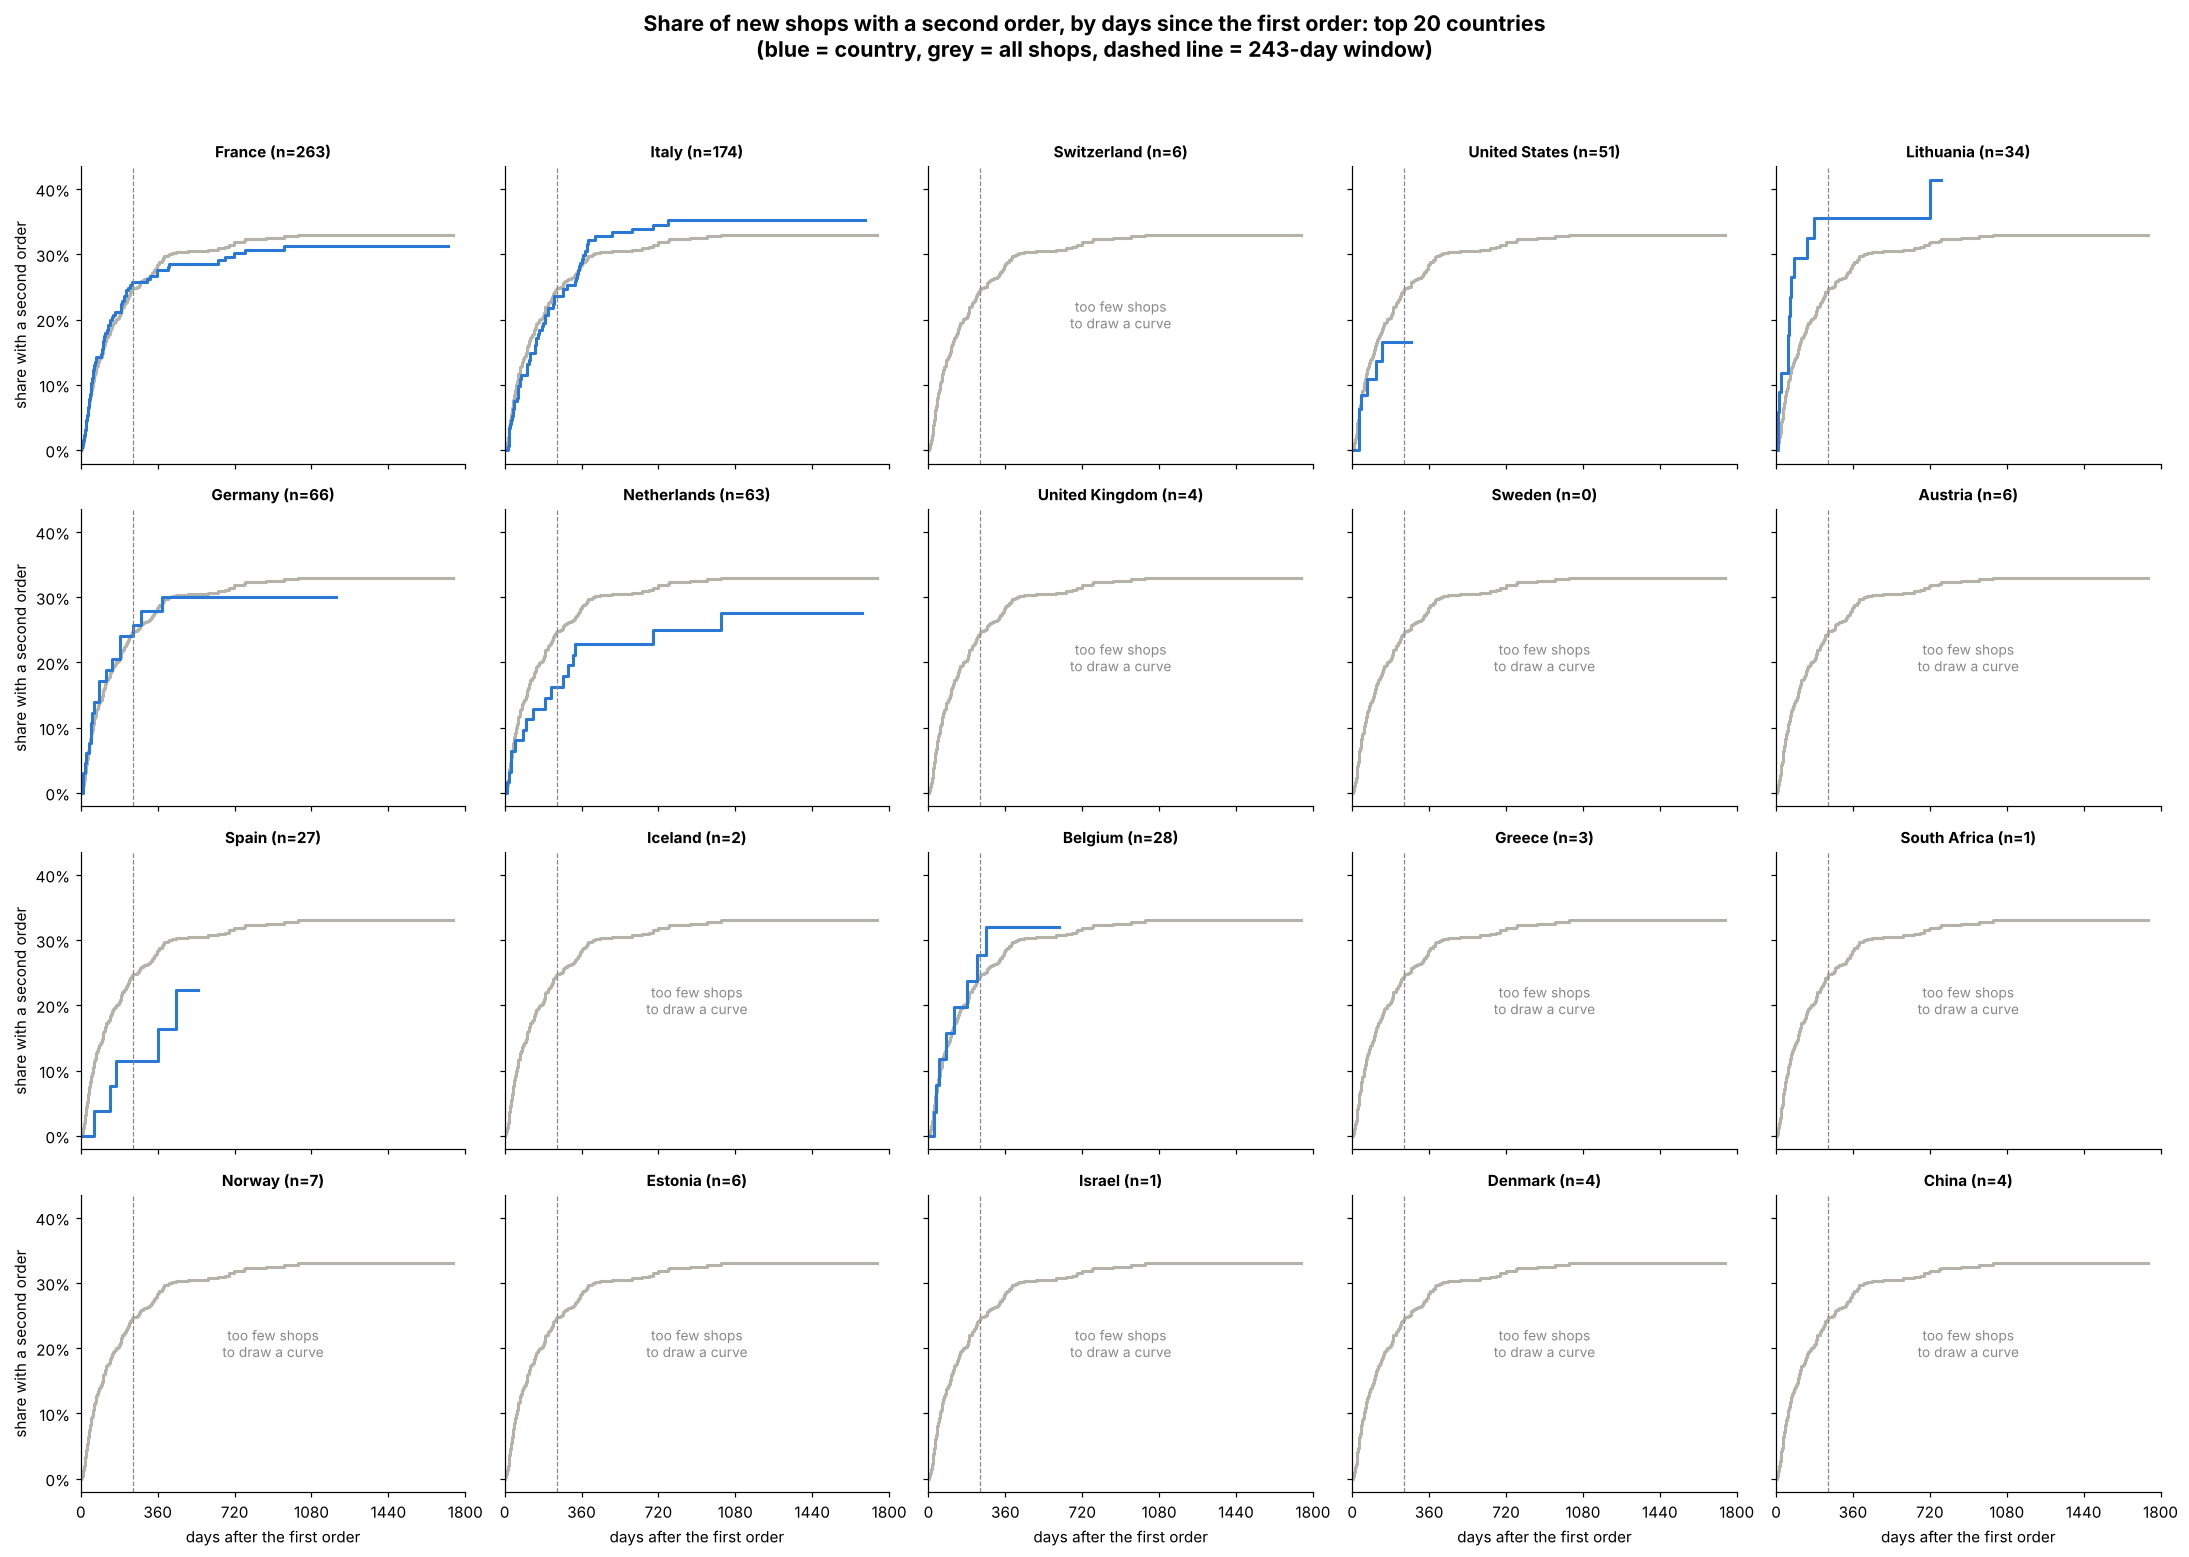

Countries with at least 10 shops: 8; log-rank p = 0.622


days after first order,90 days,243 days,365 days,730 days
France (n=263),14.3%,25.7%,27.5%,30.2%
Italy (n=174),11.5%,23.6%,29.3%,34.6%
United States (n=51),10.9%,16.6%,–,–
Lithuania (n=34),29.4%,35.5%,35.5%,41.4%
Germany (n=66),17.1%,24.0%,27.8%,30.0%
Netherlands (n=63),9.7%,16.2%,22.9%,25.0%
Spain (n=27),3.8%,11.5%,16.5%,–
Belgium (n=28),15.7%,27.8%,32.0%,–


In [57]:
def plot_country_curves(df: pd.DataFrame, countries: list) -> None:
    """Small multiples: one Kaplan–Meier curve per country, with all shops as a grey reference."""
    n_cols = 5
    n_rows = int(np.ceil(len(countries) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 3.6 * n_rows), sharex=True, sharey=True)
    x_max = int(np.ceil(last_reliable_day(df) / 180) * 180)
    for ax, country in zip(axes.flat, countries):
        part = df[df["country"] == country]
        step_curve(ax, df, "all shops", OTHER_GREY)
        if len(part) >= KM_MIN_AT_RISK:
            step_curve(ax, part, country, MAIN_COLOUR)
        else:
            ax.text(0.5, 0.5, "too few shops\nto draw a curve", transform=ax.transAxes,
                    ha="center", va="center", fontsize=9, color=REFERENCE_GREY)
        ax.axvline(REORDER_WINDOW, color=REFERENCE_GREY, linestyle="--", linewidth=0.8)
        ax.set_title(f"{country} (n={len(part)})", fontsize=10)
        ax.set_xlim(0, x_max)
        ax.set_xticks(range(0, x_max + 1, 360))
        ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    for ax in list(axes.flat)[len(countries):]:
        ax.axis("off")
    for ax in axes[-1]:
        ax.set_xlabel("days after the first order")
    for ax in axes[:, 0]:
        ax.set_ylabel("share with a second order")
    fig.suptitle("Share of new shops with a second order, by days since the first order: top 20 countries\n"
                 f"(blue = country, grey = all shops, dashed line = {REORDER_WINDOW}-day window)",
                 fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save(fig, "R8_km_by_country")
    plt.show()


plot_country_curves(surv_df, TOP_COUNTRIES)

KM_COUNTRIES = [c for c in TOP_COUNTRIES if (surv_df["country"] == c).sum() >= MIN_MODEL_COUNTRY_SHOPS]
print(f"Countries with at least {MIN_MODEL_COUNTRY_SHOPS} shops: {len(KM_COUNTRIES)}; "
      f"log-rank p = {logrank_p(surv_df, 'country', KM_COUNTRIES):.3f}")
pd.DataFrame({f"{c} (n={(surv_df['country'] == c).sum()})":
              km_table(surv_df[surv_df["country"] == c], [90, REORDER_WINDOW, 365, 730])["share re-ordered"]
              for c in KM_COUNTRIES}).T.rename(columns=lambda d: f"{d} days").style.format("{:.1%}", na_rep="–")

The same curves for the main European markets in **one chart** (`KM_REPORT_COUNTRIES`), with all shops as a dashed grey reference.

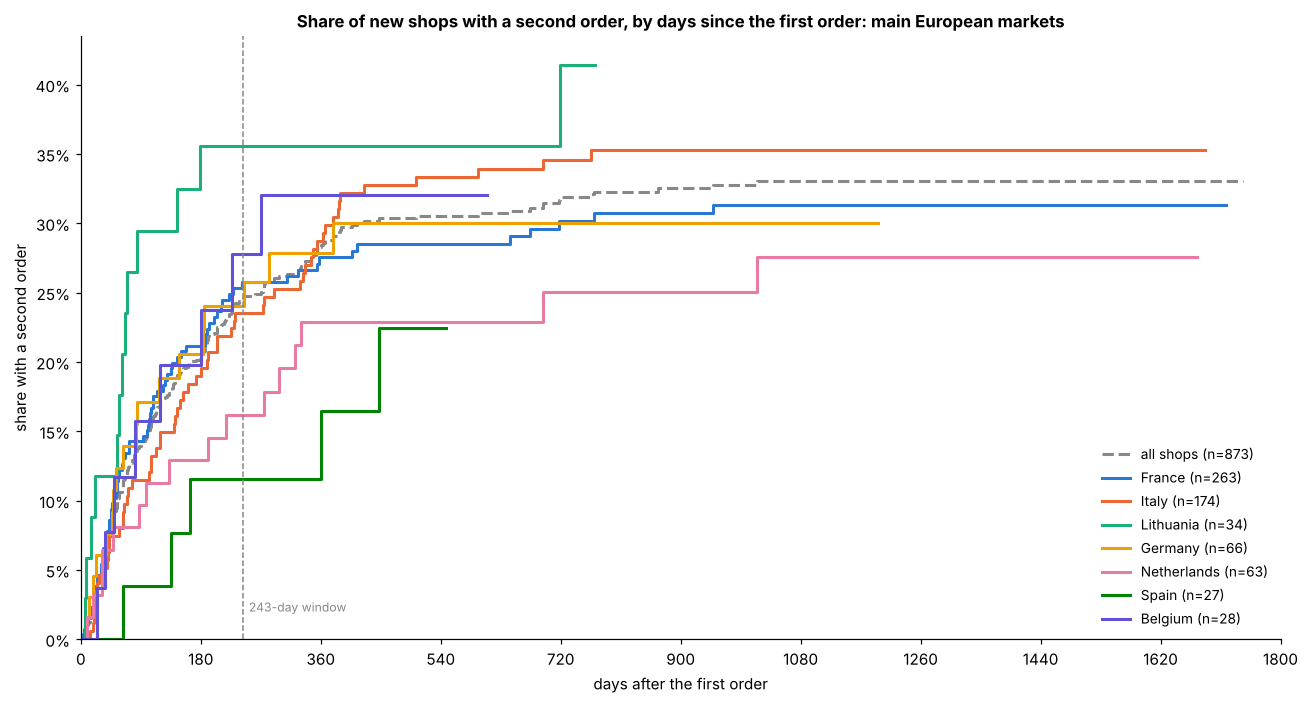

In [58]:
fig, ax = plt.subplots(figsize=(12, 6.5))
step_curve(ax, surv_df, f"all shops (n={len(surv_df)})", REFERENCE_GREY)
ax.lines[-1].set_linestyle("--")
for country, colour in zip(KM_REPORT_COUNTRIES, CATEGORICAL):
    part = surv_df[surv_df["country"] == country]
    step_curve(ax, part, f"{country} (n={len(part)})", colour)
style_km_axis(ax, "Share of new shops with a second order, by days since the first order: main European markets")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.tight_layout()
save(fig, "R8_km_main_countries")
plt.show()

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **Only 8 of the top 20 countries have enough new shops (2022–2026) for a curve.** The other 12 are in the top 20 because of a few large accounts (R5) and have 0–7 new shops in this period.
- **The country curves do not differ more than chance would explain** (log-rank p = 0.62 for the 8 countries). This matches the regression in R6.
- **Patterns worth noting, but not confirmed:**
  - **Lithuania** re-orders fastest: 29% within 90 days (all shops: 14%) and 36% within the window (34 shops).
  - **France and Germany** follow the overall curve closely (about 25% after 243 days, 30% after two years).
  - **Italy** starts slightly below the average (24% after 243 days) but keeps rising after the window, to 35% after two years, above France (30%). This is the slower return of Italian shops seen in R7.
  - **The Netherlands** (16% after 243 days, 25% after two years) and **Spain** (12% and 17% after a year, 27 shops) stay below the average throughout.
  - **The United States** curve stops at about nine months: most US shops are recent Platform B shops, so there is not yet enough follow-up to judge them.
  - **Belgium** is a candidate to watch: its new shops (most of them from 2025–2026) re-order slightly more often than average (28% after 243 days and 32% after a year, against 25% and 29% for all shops), but none of its shops has yet placed 4+ orders and the group is small (28 shops).
- **Practical reading:** country is not a reliable signal for whether a new shop will return. Two patterns could guide follow-up: Lithuanian shops return quickly, and Italian shops need a longer follow-up period before they are treated as lost.

## R9. Customer lifetime value

**Question.** How much invoice value does an average new wholesale customer bring over its first years with Candlehand? This answers goal 5 for an **average new customer**. Customers acquired at trade fairs cannot be identified in the data (see the scope notes), so this is the baseline to compare them with later.

**Definition.** *Lifetime value after N years* = the total invoice value of all orders a shop placed within N years of its first order (the first order included).
- Only shops that **have been followed for the full N years** are used for that horizon. A shop that started in 2025 cannot show its 3-year value yet, and including it would understate the value. So the 1-year value uses shops that started up to October 2025, the 3-year value only shops that started up to October 2023.
- Shops whose first order is in the first data year (2021) are left out, as in R6 (`INCLUDE_FIRST_YEAR_IN_MODEL`), because many of them were existing customers.
- This is **observed, historical** value, not a forecast. It is **invoice value, not profit**: it includes VAT for some customers and does not deduct product costs, shipping or marketplace commission (Appendix A).
- The **mean** answers "how much do new customers bring on average" (e.g. for an acquisition budget), but it is pulled up by a few large accounts. The **median** describes the typical shop.

In [59]:
def lifetime_value(orders: pd.DataFrame, shops: pd.DataFrame, years: int, data_end: pd.Timestamp,
                   include_first_year: bool) -> pd.DataFrame:
    """Invoice value and orders per shop within `years` of its first order.

    Only shops followed for the full period are returned.

    :return: one row per shop with value, orders, channel and cohort
    """
    days = int(round(365.25 * years))
    s = shops if include_first_year else shops[shops["cohort"] > shops["cohort"].min()]
    s = s[s["first_date"] <= data_end - pd.Timedelta(days=days)]
    o = orders.merge(s[["first_date"]], left_on="shop_id", right_index=True)
    o = o[(o["order_date"] - o["first_date"]).dt.days < days]
    per_shop = o.groupby("shop_id").agg(value=("order_value", "sum"), orders=("order_id", "nunique"))
    return s[["channel", "cohort"]].join(per_shop)


def ltv_summary(per_shop: pd.DataFrame) -> pd.Series:
    """Mean, median and spread of lifetime value, and how concentrated it is."""
    v = per_shop["value"].sort_values(ascending=False)
    top10 = v.head(max(1, int(round(len(v) * 0.10)))).sum() / v.sum()
    return pd.Series({"shops": len(v), "mean (€)": v.mean(), "median (€)": v.median(),
                      "90th percentile (€)": v.quantile(0.9),
                      "share of value from top 10% of shops": top10,
                      "mean orders": per_shop["orders"].mean(),
                      "share with 2+ orders": (per_shop["orders"] >= 2).mean()})


LTV = {y: lifetime_value(orders, shops, y, DATA_END, INCLUDE_FIRST_YEAR_IN_MODEL) for y in LTV_HORIZON_YEARS}
assert all(df["value"].notna().all() for df in LTV.values()), "a followed shop has no first order"

LTV_FORMAT = {"shops": "{:.0f}", "mean (€)": "{:,.0f}", "median (€)": "{:,.0f}", "90th percentile (€)": "{:,.0f}",
              "share of value from top 10% of shops": "{:.0%}", "mean orders": "{:.2f}",
              "share with 2+ orders": "{:.0%}"}
ltv_all = pd.DataFrame({f"{y} year{'s' if y > 1 else ''}": ltv_summary(df) for y, df in LTV.items()}).T
ltv_all.style.format(LTV_FORMAT)

,shops,mean (€),median (€),90th percentile (€),share of value from top 10% of shops,mean orders,share with 2+ orders
1 year,658,"1,093",534,"1,898",51%,1.51,29%
2 years,517,"1,260",591,"2,478",52%,1.70,34%
3 years,377,"1,441",589,"2,671",56%,1.86,37%


### R9.1 By channel and by year of first order

In [60]:
rows = {}
for y, df in LTV.items():
    for ch, part in df.groupby("channel"):
        rows[(f"{y} year{'s' if y > 1 else ''}", ch)] = ltv_summary(part)
ltv_channel = pd.DataFrame(rows).T.rename_axis(["horizon", "channel"])
display(ltv_channel.style.format(LTV_FORMAT))

print("1-year lifetime value by year of first order:")
ltv_cohort = pd.DataFrame({c: ltv_summary(part) for c, part in LTV[1].groupby("cohort")}).T.rename_axis("first order in")
ltv_cohort.style.format(LTV_FORMAT)

1-year lifetime value by year of first order:


,shops,mean (€),median (€),90th percentile (€),share of value from top 10% of shops,mean orders,share with 2+ orders
first order in,,,,,,,
2022,295,951,489,"1,975",45%,1.55,31%
2023,107,"2,123",641,"2,613",68%,1.63,38%
2024,131,762,526,"1,620",36%,1.38,21%
2025,125,893,532,"1,601",42%,1.46,24%


### R9.2 Value of new customers by year of first order
Is a new customer acquired in 2025 worth more or less than one acquired in 2022? The chart compares the **value in the first 12 months** and in the **first 6 months** for each year of first order.
- A shop only counts for a horizon if it has been followed for that long. 2026 shops cannot have a full first year yet, so **2026 appears only in the 6-month panel** (shops that started up to the end of April 2026). The 2025 bar in the 12-month panel uses shops that started up to the end of October 2025.
- Bars show the **mean** and the **median** per shop, with the number of shops below each year. Where the mean is far above the median, a few large accounts drive the average.

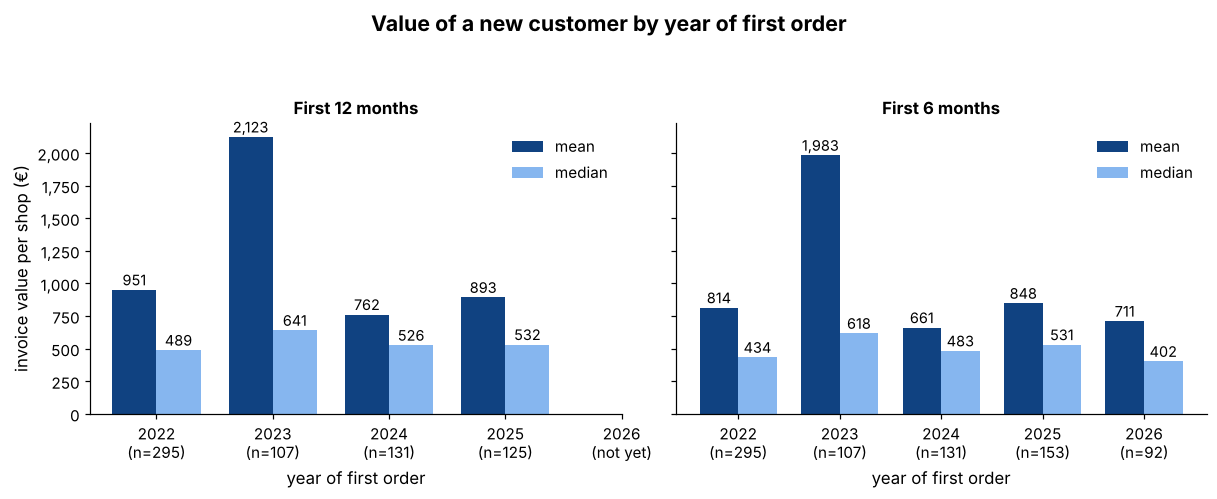

In [61]:
def value_by_cohort(orders: pd.DataFrame, shops: pd.DataFrame, years: float) -> pd.DataFrame:
    """Mean and median value per shop within `years` of the first order, per year of first order."""
    per_shop = lifetime_value(orders, shops, years, DATA_END, INCLUDE_FIRST_YEAR_IN_MODEL)
    return per_shop.groupby("cohort")["value"].agg(shops="size", mean="mean", median="median")


def plot_value_by_cohort(tables: dict) -> None:
    """Grouped bars (mean, median) per year of first order, one panel per horizon."""
    all_years = sorted(set().union(*[t.index for t in tables.values()]))
    fig, axes = plt.subplots(1, len(tables), figsize=(5.6 * len(tables), 4.6), sharey=True)
    for ax, (label, t) in zip(np.atleast_1d(axes), tables.items()):
        t = t.reindex(all_years)
        x = np.arange(len(all_years))
        for k, (stat, colour) in enumerate([("mean", ORDINAL_3[2]), ("median", ORDINAL_3[0])]):
            bars = ax.bar(x + (k - 0.5) * 0.38, t[stat], width=0.38, color=colour, label=stat)
            for b, v in zip(bars, t[stat]):
                if pd.notna(v):
                    ax.annotate(f"{v:,.0f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                                textcoords="offset points", ha="center", fontsize=9.5)
        ax.set_xticks(x, [f"{y}\n(n={int(n)})" if pd.notna(n) else f"{y}\n(not yet)"
                          for y, n in zip(all_years, t["shops"])])
        ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
        ax.set_xlabel("year of first order")
        ax.set_title(label, fontsize=11)
        ax.legend(frameon=False, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("invoice value per shop (€)")
    fig.suptitle("Value of a new customer by year of first order", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.93])
    save(fig, "R9_value_by_cohort")
    plt.show()


COHORT_VALUE = {f"First {int(round(12 * y))} months": value_by_cohort(orders, shops, y)
                for y in sorted(LTV_COHORT_HORIZON_YEARS, reverse=True)}
with plt.rc_context(REPORT_RC):
    plot_value_by_cohort(COHORT_VALUE)
pd.concat(COHORT_VALUE, axis=1).style.format("{:,.0f}", na_rep="–")

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **The typical new customer is worth about the same in every year.** The median value in the first 12 months is 490–640 € for shops that started in 2022–2025 (489, 641, 526 and 532 €). After 6 months it is 430–620 €.
- **2023 stands out only because of one order.** The 2023 mean (2,123 € after 12 months) includes a single 91.4k € order from one shop in the United States. Without that shop, the 2023 mean is about 1,280 €. That is still the highest year, in line with 2023 also having the highest re-order rate (R1).
- **2024 has the lowest mean** (762 € after 12 months), while the medians of 2022–2025 are close (489–641 €). 2025: mean 893 €, median 532 €.
- **2026 starts lower:** after 6 months, the 92 shops that started in January–April 2026 are worth a median of 402 €, the lowest of all years (mean 711 €). This fits the rise of small Platform B orders in 2026 (R2, R3). It rests on the first four months of 2026 only and should be re-checked when the year is complete.
- **Practical reading:** for a typical shop the first order is most of its lifetime value, and the size of that first order has not grown. Yearly sales therefore move with how many new shops are won and how many of them become frequent buyers.

### R9.3 Value over time since the first order

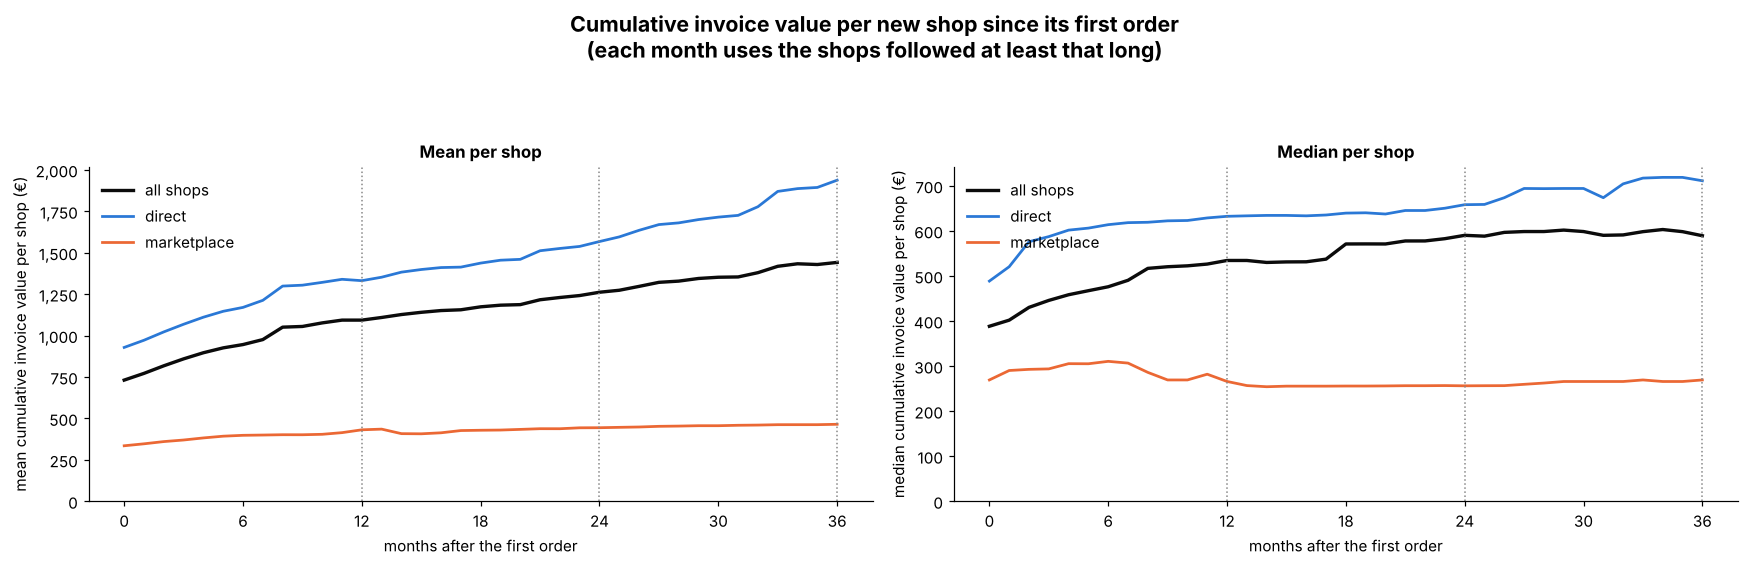

In [62]:
def mean_value_curve(orders: pd.DataFrame, shops: pd.DataFrame, max_months: int,
                     include_first_year: bool) -> pd.DataFrame:
    """Mean and median cumulative value per shop by month since the first order.

    Each month uses the shops followed at least that long, so later months rest on older shops.
    """
    s = shops if include_first_year else shops[shops["cohort"] > shops["cohort"].min()]
    o = orders.merge(s[["first_date", "channel"]], left_on="shop_id", right_index=True,
                     suffixes=("", "_shop"))
    o["days"] = (o["order_date"] - o["first_date"]).dt.days
    followed = (DATA_END - s["first_date"]).dt.days
    rows = []
    for m in range(0, max_months + 1):
        d = int(round(m * 30.44))
        ids = followed.index[followed >= d]
        value = o[(o["days"] <= d) & o["shop_id"].isin(ids)].groupby("shop_id")["order_value"].sum()
        for ch, grp in [("all shops", ids), *[(c, ids[s.loc[ids, "channel"] == c]) for c in ["direct", "marketplace"]]]:
            v = value.reindex(grp)
            rows.append({"month": m, "group": ch, "shops": len(v), "mean": v.mean(), "median": v.median()})
    return pd.DataFrame(rows)


curve = mean_value_curve(orders, shops, 12 * max(LTV_HORIZON_YEARS), INCLUDE_FIRST_YEAR_IN_MODEL)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=False)
for ax, stat in zip(axes, ["mean", "median"]):
    for (grp, colour) in [("all shops", "#0b0b0b"), ("direct", CATEGORICAL[0]), ("marketplace", CATEGORICAL[1])]:
        c = curve[curve["group"] == grp]
        ax.plot(c["month"], c[stat], color=colour, linewidth=2.2 if grp == "all shops" else 1.8, label=grp)
    for y in LTV_HORIZON_YEARS:
        ax.axvline(12 * y, color=REFERENCE_GREY, linestyle=":", linewidth=1)
    ax.set_xticks(range(0, 12 * max(LTV_HORIZON_YEARS) + 1, 6))
    ax.set_xlabel("months after the first order")
    ax.set_ylabel(f"{stat} cumulative invoice value per shop (€)")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    ax.set_ylim(0, None)
    ax.set_title(f"{stat.capitalize()} per shop", fontsize=11)
    ax.legend(frameon=False, loc="upper left")
fig.suptitle("Cumulative invoice value per new shop since its first order\n"
             "(each month uses the shops followed at least that long)", fontsize=14, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.9])
save(fig, "R9_lifetime_value")
plt.show()

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **An average new customer brings about 1,090 € of invoice value in its first year, 1,260 € in two years and 1,440 € in three years** (658, 517 and 377 shops followed that long). Most of the value comes with the first order: the average first order is about 730 €.
- **The typical customer brings much less:** the median is about 530 € after one year and about 590 € after two and three years. About two-thirds of new shops never place a second order, so for them the first order is the whole lifetime value.
- **The value is concentrated:** the top 10% of new shops bring 51–56% of the lifetime value. The mean is therefore driven by a few large accounts; for example, the high 1-year mean of the 2023 starters (2,120 €, median 641 €) comes mainly from one very large order (R5: a single 91k € order from the United States).
- **Direct customers are worth about three times as much as marketplace customers:** 1,330 € vs 430 € after one year and 1,940 € vs 460 € after three years (median 711 € vs 269 €). Direct customers keep adding value over the years; marketplace customers add very little after the first order (44% vs 24% have a second order within three years). Note that some marketplace invoices are recorded at about 80% of the wholesale price (commission, Appendix A), so the true gap is somewhat smaller, but still large.
- **The 1-year value of new customers did not grow:** median 490–640 € for every first-order year from 2022 to 2025 (the 2023 mean is the large-order outlier).

**Practical reading**
- For budgeting customer acquisition (for example trade-fair costs per new customer), a new **direct** customer is worth roughly 1,300 € in invoice value in its first year and 1,900 € in three years on average, but half of them stay under about 650–700 €. These are invoice values, not profit.
- This average is the baseline to compare trade-fair customers with, once they are identified.

# Appendix A. What does `invoice_total_amount` contain?

During the analysis, three amounts per invoice were found to disagree:

- `sales_total`: sum of the product lines in `data_synthetic.csv` (without VAT);
- `invoice_total_amount`: the invoice amount in `data_synthetic.csv` (the *invoice value* used in this notebook);
- `Total Signed`: Odoo's invoice total from `Total_synthetic.xlsx`.

This appendix shows the patterns that explain most of the differences. They are inferred from the data, not confirmed from the system configuration, and were reported to the person responsible for the ERP → AWS data pipeline.

In [63]:
def classify_differences(invoices: pd.DataFrame) -> pd.DataFrame:
    """Classify each invoice by both gaps."""
    d = invoices.assign(
        diff_signed=(invoices["total_signed"] - invoices["invoice_value"]).round(2),
        ratio_signed=invoices["total_signed"] / invoices["invoice_value"],
        ratio_vat=invoices["invoice_value"] / invoices["sales_total"],
    )
    vat_like = np.zeros(len(d), dtype=bool)
    for rate in [1.19, 1.20, 1.21, 1.22, 1.23, 1.24, 1.25, 1.27]:
        vat_like |= (d["ratio_vat"] - rate).abs().to_numpy() <= 0.005
    d["vs_lines"] = np.select(
        [(d["invoice_value"] - d["sales_total"]).abs() <= 0.02, vat_like],
        ["equal", "VAT-like ratio"], default="other")
    d["vs_total_signed"] = np.select(
        [d["total_signed"].isna(), d["diff_signed"].abs() <= 1, d["diff_signed"].round(0) == 30,
         d["diff_signed"].between(20, 80), d["ratio_signed"].round(2).between(0.79, 0.81)],
        ["missing", "equal (±1 €)", "+30 € exactly", "+20–80 € (other)", "×0.80"],
        default="other")
    return d


diffs = classify_differences(invoices_c)
display(pd.crosstab(diffs["vs_lines"], diffs["vs_total_signed"], margins=True))

vs_total_signed,+20–80 € (other),+30 € exactly,equal (±1 €),other,×0.80,All
vs_lines,,,,,,
VAT-like ratio,18,4,51,43,0,116
equal,367,336,473,296,65,1537
other,92,214,279,91,1,677
All,477,554,803,430,66,2330


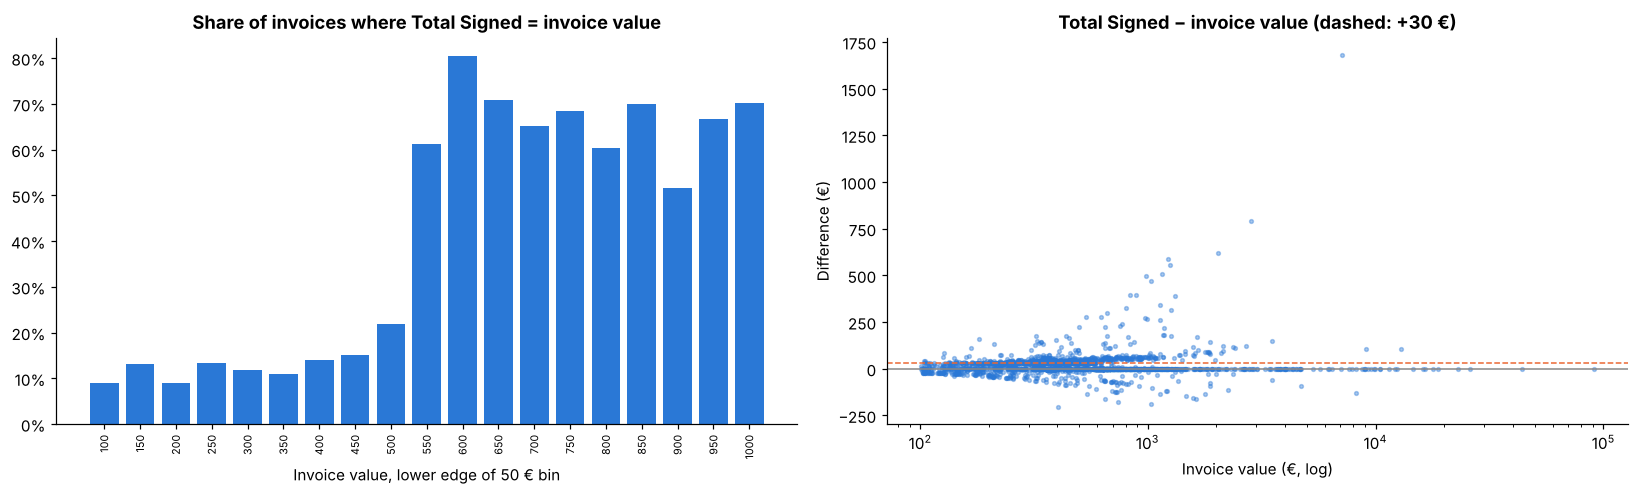

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))

# 1. Free-shipping threshold: share of invoices with no extra charge, by value
bins = list(range(100, 1001, 50)) + [np.inf]
d = diffs.assign(value_bin=pd.cut(diffs["invoice_value"], bins, right=False))
match = d.groupby("value_bin", observed=True)["vs_total_signed"].apply(lambda s: (s == "equal (±1 €)").mean())
axes[0].bar(range(len(match)), match.to_numpy(), color=MAIN_COLOUR)
axes[0].set_xticks(range(len(match)), [str(int(b.left)) for b in match.index], rotation=90, fontsize=7)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].set(title="Share of invoices where Total Signed = invoice value",
            xlabel="Invoice value, lower edge of 50 € bin")

# 2. Size of the difference vs invoice value
axes[1].scatter(diffs["invoice_value"], diffs["diff_signed"], s=6, alpha=0.4, color=MAIN_COLOUR)
axes[1].set_xscale("log")
axes[1].axhline(0, color=REFERENCE_GREY, linewidth=1)
axes[1].axhline(30, color=CATEGORICAL[1], linewidth=1, linestyle="--")
axes[1].set(title="Total Signed − invoice value (dashed: +30 €)", xlabel="Invoice value (€, log)",
            ylabel="Difference (€)")
fig.tight_layout()
save(fig, "A_invoice_amount_checks")
plt.show()

In [65]:
mp = diffs[diffs["channel"] == "marketplace"].assign(
    platform=lambda x: x["customer"].str.extract(f"({MARKETPLACE_PATTERN})", expand=False),
    year=lambda x: x["date"].dt.year)
(mp.groupby(["platform", "year"])
   .agg(invoices=("Invoice number", "size"),
        share_x080=("vs_total_signed", lambda s: (s == "×0.80").mean()))
   .unstack("platform").round(2))

invoices                       share_x080                      
platform Platform A Platform B Platform C Platform A Platform B Platform C
year                                                                      
2021           83.0        NaN       25.0       0.35        NaN       0.00
2022          128.0        NaN       47.0       0.23        NaN       0.00
2023           32.0        NaN       26.0       0.00        NaN       0.00
2024           17.0        3.0       12.0       0.00       0.00       0.00
2025            9.0       30.0       12.0       0.00       0.00       0.33
2026            2.0      151.0        4.0       0.00       0.01       0.50

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

- **`invoice_total_amount` vs the product lines:** equal for 66% of invoices; a VAT-like ratio (×1.19–1.27) for 5%; something else for 29%, which these exports cannot explain.
- **`Total Signed` vs `invoice_total_amount`:**
  - equal for 34% of invoices;
  - exactly **+30 €** for 24% (consistent with a flat shipping charge);
  - +20–80 € for another 20% (probably other shipping rates);
  - **×0.80** for 3%;
  - other differences for 18%.
- **Free shipping above about 600 €:** below 500 € only 9–15% of invoices have no extra charge; from 600 € this jumps to 52–80%. The transition is between 500 and 600 €. In this synthetic data the 550–600 € bin is already at 61%, because the ±5% change of amounts moves some invoices across the threshold; in the original data the step at 600 € is sharper.
- **×0.80 is a marketplace effect:** Platform A invoices in 2021–2022 (35% and 23% of them) and Platform C in 2025–2026. This is consistent with a 20% platform commission deducted on the invoice.
- **Consequence for this notebook:** invoice value = goods value incl. VAT where charged, excl. shipping and commission. That fits a study of *buying behaviour*, but it is **not** Candlehand's revenue. These inconsistencies were reported to the person who maintains the ERP → AWS pipeline; monthly reports built on the same fields were affected.

# Conclusions, limitations and next steps

*Findings for the synthetic data (dates up to 29 October 2026). Re-read them against the outputs after updating the data.*

### Answers to Candlehand's goals

1. **Ordering patterns of direct and marketplace customers (R1–R4).** Most shops order once a year, and this share has grown (69% of active shops in 2022, 79% in 2025). A small loyal group (12% of shops with 4+ orders) brought 49% of invoice value. Orders are getting smaller, and the product mix moved from Hand Gesture and Baby candles to CandleCan and 3D Taper candles. Marketplace shops place smaller orders and re-order less than direct shops.
2. **Re-order rate (5, R1, R8).** 80% of re-orders come within 243 days. About 30% of new shops re-order within that window (25% of shops that started in 2022–2026), and about one in three ever re-orders. The rate fell from 26–35% (2022–2023) to 18–22% (2024–2025).
3. **Regular customers, 4+ orders a year (R2).** Few, and fewer than before: 8% of active shops in 2022, 2–4% in 2023–2026 (5–10 shops a year).
4. **Category, country and client type vs re-ordering (R5–R8).**
   - *Client type:* direct shops re-order more often than marketplace shops (28% vs 18% within the window for 2022–2026 starters). In the regression the marketplace odds are about 0.6× those of direct shops; this is borderline (p = 0.07 with Italy, p = 0.041 without).
   - *Country:* France and Italy bring about half of the value with average re-ordering; Lithuania has the strongest repeat buying (36%), the Netherlands and Spain the weakest (12–16%). In the regression (R6), country is **not** a clear signal once channel, order size and year are taken into account (joint p = 0.15; no single country distinguishable from France). Italian shops are not lost more often than French shops, but return more slowly (R7). Several high-value countries depend on a single customer.
   - *Product category:* the main category of the first order is not clearly related to re-ordering (R8). Product effects are hard to separate from time, because the range changed completely over the period.
   - *First-order size:* small first orders (under 400 €) re-order less (clear in R8). The regression shows that this comes mainly from Italy: without Italian shops, first-order value has no effect.
5. **Lifetime value (R9).** An average new customer brings about 1,090 € of invoice value in its first year and 1,440 € in three years (median about 530–590 €); a direct customer about three times as much as a marketplace customer. Customers from trade fairs cannot yet be identified in the data (Next steps).

### Main findings
1. **Re-ordering has declined.** About 3 in 10 new shops re-order within 243 days. Retention fell from 26–35% (2022–2023 cohorts) to 18–22% (2024–2025), and the share of shops ordering only once a year rose from 69% to 79%. The trend is visible in both direct and marketplace shops.
2. **The business depends on a small loyal group.** 12% of shops (4+ orders) brought 49% of invoice value over 2021–2026. The loss of frequent, high-value shops after 2022 accounts for about two-thirds of the fall in yearly value (615k € in 2022 → 176k € in 2025).
3. **The product range changed completely.** Hand Gesture and Baby candles, which the early loyal shops bought, fell by 80–90%. CandleCan and the new 3D Taper candles (from 2025) now lead. Total units have stabilised, but orders are smaller.
4. **Sales are concentrated:** the top 20 countries bring 94% of invoice value, and France and Italy about half. Several top-20 countries (Switzerland, Sweden, South Africa, Israel) are there because of a single large customer. Lithuania has strong and fast repeat buying, and Belgium is a candidate to watch (above-average re-ordering among recent shops, but no frequent buyers yet); the United States has many shops (mostly via Platform B) but a low typical spend. Italy has no orders in 2026 so far.
5. **First-order features and country are weak predictors.** For shops that started in 2022–2026, marketplace shops, small first orders and single-category orders go with less re-ordering, and Lithuania re-orders most, the Netherlands and Spain least. Once these features, country and year are in one model, none is clearly distinguishable from chance. The year of the first order matters more than anything in the order itself. The value effect comes from Italy, where small first orders rarely lead to a re-order. Modelling shops that never came back (R7) mostly mirrors the re-order model; its one new insight is that Italian shops re-order later rather than less. Both models explain little (AUC ≈ 0.62–0.66). Kaplan–Meier curves (R8) show that most shops that re-order do so within a few months, and that the share re-ordered hardly grows after about a year (25% after 243 days, 32% after two years).
6. **Lifetime value is concentrated and channel-dependent.** A new customer brings about 1,090 € in its first year on average, but the median is about 530 €; direct customers bring about three times as much as marketplace customers.
7. **The source data has known inconsistencies** (shipping, VAT, marketplace commission). Documenting them helped correct the AWS data pipeline.

### Limitations
- **Data window:** it starts in June 2021, so first orders in 2021 include existing customers; 2026 is partial until the data is updated.
- **Shop identity rests on names.** A shop whose name changed, or that is written differently in two places, counts as two shops, which understates re-ordering.
- **Invoice value is not revenue.** It includes VAT for some customers and excludes shipping and commission (Appendix A). Lifetime value (R9) is therefore invoice value, not profit.
- **Client type is direct vs marketplace only.** Customers managed by agents or distributors cannot be identified and are counted as direct; the acquisition source (e.g. trade fairs) is not recorded.
- **Filters change the population:** private persons, credit notes and invoices under 100 € were removed.
- **Associations, not causes.** Larger first orders may mark larger or more committed shops rather than *cause* re-ordering.
- **Product effects are confounded with time,** because products were introduced and phased out during the period.
- **Small groups give wide intervals:** many countries, the 4+ group in recent years and the 2026 cohort are small.
- **Some countries come from a manual web lookup** (section 4.2): 78 shops were assigned a country marked "likely"; 62 shops (77 invoices) remain "Unknown".

### Next steps
1. **Re-run after 2026 is complete** (replace the files, restart and run all) and re-check the 2026 cohort and the per-year trends.
2. **Survival model of the time to the second order.** R8 describes the timing with Kaplan–Meier curves; a Cox model would add the same predictors as R6, adjusted for each other, while still using all shops.
3. **Investigate the loss of frequent shops after 2022:** which shops stopped, what they had bought, and whether it coincided with the product changes or the shipping charges.
4. **Test the shipping threshold:** whether shops bunch just above ~600 € (topping up to avoid the fee), and whether shops that paid shipping on their first order re-order less.
5. **Enrich shop data** (shop type, city size, online presence) for a sample of shops, to support finding new customers.
6. **Confirm the field definitions** with the owners of the ERP → AWS pipeline after their fix, and switch to net revenue if it becomes available.
7. **Lifetime value of trade-fair customers:** mark the shops acquired at Maison&Objet, Ambiente and other fairs (e.g. from the fair lead lists) and compare their lifetime value with the average new customer in R9.

Final check that the raw data was not modified anywhere in the notebook and the prepared tables are still consistent.

In [66]:
validate(raw_lines, invoices_c, orders, order_lines)
print("Raw data unchanged; all checks passed.")

Raw data unchanged; all checks passed.
